<a href="https://colab.research.google.com/github/mohammadrehan2403-stack/BioSeq-AI/blob/main/BioSeq_AI_Next_Version.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q gradio pandas matplotlib biopython scikit-learn



In [ ]:

# ============================================
# BioSeq AI — Next Version
# Educational DNA Sequence Analysis Platform
# ============================================

from datetime import datetime

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt

from Bio.Seq import Seq
from collections import Counter

# Project configuration
APP_NAME = "BioSeq AI — Next Version"
APP_VERSION = "2.0.0"

print("=" * 45)
print(APP_NAME)
print("Version:", APP_VERSION)
print("Python environment initialized successfully!")
print("Time:", datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print("=" * 45)


# Validate a DNA sequence
def validate_dna(sequence):
    """
    Validate a DNA sequence containing A, T, G and C.
    Spaces and line breaks are ignored.
    Returns a cleaned sequence or a helpful error.
    """

    if not isinstance(sequence, str) or not sequence.strip():
        return False, "Please enter a DNA sequence."

    cleaned = "".join(sequence.upper().split())

    allowed = set("ATGC")
    invalid = sorted(set(cleaned) - allowed)

    if invalid:
        return False, (
            "Invalid character(s): "
            + ", ".join(invalid)
            + ". Use only A, T, G and C."
        )

    return True, cleaned


# Test the validation function
test_sequences = [
    "ATGCGTAA",
    "atgc gtaa",
    "ATGXGT",
    ""
]

for sequence in test_sequences:
    valid, result = validate_dna(sequence)
    print(f"\nInput: {sequence!r}")
    print(f"Valid: {valid}")
    print(f"Result: {result}")


BioSeq AI — Next Version
Version: 2.0.0
Python environment initialized successfully!
Time: 2026-10-22 12:48:59

Input: 'ATGCGTAA'
Valid: True
Result: ATGCGTAA

Input: 'atgc gtaa'
Valid: True
Result: ATGCGTAA

Input: 'ATGXGT'
Valid: False
Result: Invalid character(s): X. Use only A, T, G and C.

Input: ''
Valid: False
Result: Please enter a DNA sequence.


In [ ]:
dna_functions = [
    "validate_dna",
    "analyze_dna",
    "translate_dna",
    "reverse_complement",
    "compare_dna_sequences",
    "detect_orfs",
    "search_dna_motif",
    "detect_dna_mutations",
    "dna_quality_report",
    "blast_dna_search",
    "generate_dna_report",
    "kmer_analysis_dashboard"
]

for name in dna_functions:
    status = "Available ✅" if callable(globals().get(name)) else "Missing ❌"
    print(f"{name}: {status}")

validate_dna: Available ✅
analyze_dna: Missing ❌
translate_dna: Missing ❌
reverse_complement: Missing ❌
compare_dna_sequences: Missing ❌
detect_orfs: Missing ❌
search_dna_motif: Missing ❌
detect_dna_mutations: Missing ❌
dna_quality_report: Missing ❌
blast_dna_search: Missing ❌
generate_dna_report: Missing ❌
kmer_analysis_dashboard: Missing ❌


========== BIOSEQ AI DNA ANALYZER ==========
DNA Sequence: ATGCGCGTATATGC
Sequence Length: 14
Adenine (A): 3
Thymine (T): 4
Guanine (G): 4
Cytosine (C): 3
GC Count: 7
GC Content: 50.0%
AT Content: 50.0%


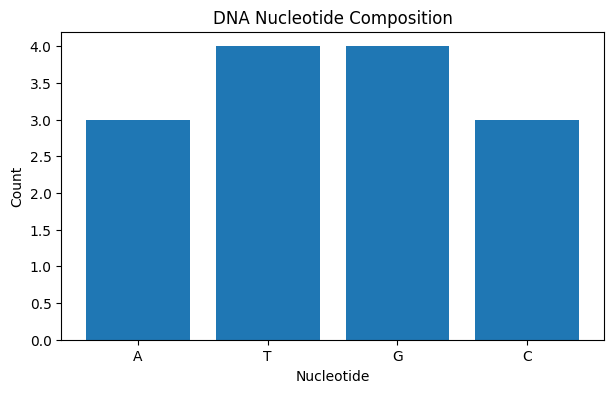

In [ ]:

# ============================================
# STEP 3: DNA ANALYZER
# ============================================

from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd


def analyze_dna(sequence):

    # Validate the input
    valid, result = validate_dna(sequence)

    if not valid:
        return {"error": result}

    dna = result
    length = len(dna)

    # Count each nucleotide
    counts = Counter(dna)

    a_count = counts.get("A", 0)
    t_count = counts.get("T", 0)
    g_count = counts.get("G", 0)
    c_count = counts.get("C", 0)

    # GC percentage
    gc_count = g_count + c_count
    gc_percent = (gc_count / length) * 100

    # AT percentage
    at_percent = ((a_count + t_count) / length) * 100

    return {
        "sequence": dna,
        "length": length,
        "A": a_count,
        "T": t_count,
        "G": g_count,
        "C": c_count,
        "GC_count": gc_count,
        "GC_percent": round(gc_percent, 2),
        "AT_percent": round(at_percent, 2)
    }


# Test the DNA Analyzer
sample_dna = "ATGCGCGTATATGC"

result = analyze_dna(sample_dna)

print("========== BIOSEQ AI DNA ANALYZER ==========")
print("DNA Sequence:", result["sequence"])
print("Sequence Length:", result["length"])
print("Adenine (A):", result["A"])
print("Thymine (T):", result["T"])
print("Guanine (G):", result["G"])
print("Cytosine (C):", result["C"])
print("GC Count:", result["GC_count"])
print("GC Content:", str(result["GC_percent"]) + "%")
print("AT Content:", str(result["AT_percent"]) + "%")

# Visualize nucleotide composition
nucleotides = ["A", "T", "G", "C"]
values = [result[n] for n in nucleotides]

plt.figure(figsize=(7, 4))
plt.bar(nucleotides, values)
plt.title("DNA Nucleotide Composition")
plt.xlabel("Nucleotide")
plt.ylabel("Count")
plt.show()



In [ ]:
# ============================================
# STEP 4: CODON & AMINO ACID ANALYSIS
# Corrected Version 2.0
# ============================================

from Bio.Seq import Seq
from Bio.Data import CodonTable
from itertools import product
import pandas as pd

# Standard genetic code
GENETIC_CODE = CodonTable.unambiguous_dna_by_name["Standard"]

# Amino acid information:
# One-letter code: (Full name, Three-letter code)

AMINO_ACID_NAMES = {
    "A": ("Alanine", "Ala"),
    "R": ("Arginine", "Arg"),
    "N": ("Asparagine", "Asn"),
    "D": ("Aspartic acid", "Asp"),
    "C": ("Cysteine", "Cys"),
    "Q": ("Glutamine", "Gln"),
    "E": ("Glutamic acid", "Glu"),
    "G": ("Glycine", "Gly"),
    "H": ("Histidine", "His"),
    "I": ("Isoleucine", "Ile"),
    "L": ("Leucine", "Leu"),
    "K": ("Lysine", "Lys"),
    "M": ("Methionine", "Met"),
    "F": ("Phenylalanine", "Phe"),
    "P": ("Proline", "Pro"),
    "S": ("Serine", "Ser"),
    "T": ("Threonine", "Thr"),
    "W": ("Tryptophan", "Trp"),
    "Y": ("Tyrosine", "Tyr"),
    "V": ("Valine", "Val")
}

# Generate the complete 64-codon table
CODON_ROWS = []

for bases in product("TCAG", repeat=3):

    codon = "".join(bases)

    if codon in GENETIC_CODE.stop_codons:

        CODON_ROWS.append({
            "Codon": codon,
            "Amino Acid": "Stop",
            "Three-letter": "Ter",
            "One-letter": "*",
            "Type": "Stop"
        })

    else:

        aa_code = GENETIC_CODE.forward_table[codon]
        full_name, three_letter = AMINO_ACID_NAMES[aa_code]

        CODON_ROWS.append({
            "Codon": codon,
            "Amino Acid": full_name,
            "Three-letter": three_letter,
            "One-letter": aa_code,

            # ATG is the standard start codon
            # in the standard genetic code.
            "Type": (
                "Start" if codon == "ATG"
                else "Standard"
            )
        })


codon_table_df = (
    pd.DataFrame(CODON_ROWS)
    .sort_values("Codon")
    .reset_index(drop=True)
)


# Search by codon or amino acid
def search_codon(query):

    if not isinstance(query, str) or not query.strip():
        return codon_table_df.copy()

    q = query.strip().upper()

    mask = (
        codon_table_df["Codon"].str.contains(
            q, regex=False
        )
        | codon_table_df["Amino Acid"].str.upper().str.contains(
            q, regex=False
        )
        | codon_table_df["Three-letter"].str.upper().str.contains(
            q, regex=False
        )
        | codon_table_df["One-letter"].str.upper().eq(q)
    )

    return codon_table_df[mask].reset_index(drop=True)


# Translate DNA in all six reading frames
def translate_six_frames(sequence):

    valid, result = validate_dna(sequence)

    if not valid:
        return {"error": result}

    dna = Seq(result)
    reverse_dna = dna.reverse_complement()

    translations = {}

    strands = [
        ("Forward", dna),
        ("Reverse complement", reverse_dna)
    ]

    for strand_name, strand in strands:

        for frame in range(3):

            framed = strand[frame:]

            # Use only complete codons
            complete_length = (len(framed) // 3) * 3
            complete_codons = framed[:complete_length]

            if len(complete_codons) == 0:
                protein = "(No complete codons)"

            else:
                protein = str(
                    complete_codons.translate(
                        table="Standard",
                        to_stop=False
                    )
                )

            translations[
                f"{strand_name} frame {frame + 1}"
            ] = protein

    return translations


# ============================================
# TEST 1: Complete codon table
# ============================================

print("=" * 45)
print("BIOSEQ AI: CODON ANALYSIS")
print("=" * 45)

print("Total codons:", len(codon_table_df))

assert len(codon_table_df) == 64
assert codon_table_df["Codon"].nunique() == 64

print("\nComplete codon table:")
print(codon_table_df.to_string(index=False))


# ============================================
# TEST 2: Required codons
# ============================================

print("\n========== CODON VALIDATION ==========")

for codon in ["ATG", "TGG", "TAA", "TAG", "TGA"]:

    print(f"\nCodon: {codon}")
    print(search_codon(codon).to_string(index=False))


# ============================================
# TEST 3: Six-frame translation
# ============================================

print("\n========== SIX-FRAME TRANSLATION ==========")

test_dna = "ATGGAGCTTTAA"

for frame, protein in translate_six_frames(test_dna).items():
    print(f"{frame}: {protein}")


# ============================================
# TEST 4: Start codon verification
# ============================================

start_result = search_codon("ATG")

assert len(start_result) == 1
assert start_result.iloc[0]["Type"] == "Start"

for codon in ["TAA", "TAG", "TGA"]:

    result = search_codon(codon)

    assert len(result) == 1
    assert result.iloc[0]["Type"] == "Stop"

print("\nAll codon validation tests passed!")

BIOSEQ AI: CODON ANALYSIS
Total codons: 64

Complete codon table:
Codon    Amino Acid Three-letter One-letter     Type
  AAA        Lysine          Lys          K Standard
  AAC    Asparagine          Asn          N Standard
  AAG        Lysine          Lys          K Standard
  AAT    Asparagine          Asn          N Standard
  ACA     Threonine          Thr          T Standard
  ACC     Threonine          Thr          T Standard
  ACG     Threonine          Thr          T Standard
  ACT     Threonine          Thr          T Standard
  AGA      Arginine          Arg          R Standard
  AGC        Serine          Ser          S Standard
  AGG      Arginine          Arg          R Standard
  AGT        Serine          Ser          S Standard
  ATA    Isoleucine          Ile          I Standard
  ATC    Isoleucine          Ile          I Standard
  ATG    Methionine          Met          M    Start
  ATT    Isoleucine          Ile          I Standard
  CAA     Glutamine          Gln 

In [ ]:

%pip install -q biopython pandas


In [ ]:
# ============================================
# STEP 5: DNA SEQUENCE COMPARISON
# ============================================

from Bio import Align
from Bio.Seq import Seq
import pandas as pd


def compare_dna_sequences(reference, test):

    # Validate both sequences
    ref_valid, ref_result = validate_dna(reference)
    test_valid, test_result = validate_dna(test)

    if not ref_valid:
        return {"error": f"Reference sequence: {ref_result}"}

    if not test_valid:
        return {"error": f"Test sequence: {test_result}"}

    reference = ref_result
    test = test_result

    # Configure global alignment
    aligner = Align.PairwiseAligner()
    aligner.mode = "global"
    aligner.match_score = 2
    aligner.mismatch_score = -1
    aligner.open_gap_score = -3
    aligner.extend_gap_score = -0.5

    alignments = aligner.align(reference, test)
    alignment = alignments[0]

    aligned_ref, aligned_test = alignment.aligned

    # Reconstruct aligned strings, including gaps
    aligned_reference_parts = []
    aligned_test_parts = []

    ref_pos = 0
    test_pos = 0

    for (ref_start, ref_end), (test_start, test_end) in zip(
        aligned_ref, aligned_test
    ):

        # Add the alignment segment before this block.
        # For global alignment, any unaligned section here
        # is represented by gaps in the opposite sequence.
        if ref_start > ref_pos:
            gap_len = ref_start - ref_pos
            aligned_reference_parts.append(reference[ref_pos:ref_start])
            aligned_test_parts.append("-" * gap_len)

        if test_start > test_pos:
            gap_len = test_start - test_pos
            aligned_reference_parts.append("-" * gap_len)
            aligned_test_parts.append(test[test_pos:test_start])

        aligned_reference_parts.append(reference[ref_start:ref_end])
        aligned_test_parts.append(test[test_start:test_end])

        ref_pos = ref_end
        test_pos = test_end

    # Add trailing portions
    if ref_pos < len(reference):
        aligned_reference_parts.append(reference[ref_pos:])
        aligned_test_parts.append("-" * (len(reference) - ref_pos))

    if test_pos < len(test):
        aligned_reference_parts.append("-" * (len(test) - test_pos))
        aligned_test_parts.append(test[test_pos:])

    aligned_reference = "".join(aligned_reference_parts)
    aligned_test = "".join(aligned_test_parts)

    # Count aligned matches and differences
    matches = 0
    substitutions = []
    insertions = []
    deletions = []

    ref_position = 0
    test_position = 0

    for column, (ref_base, test_base) in enumerate(
        zip(aligned_reference, aligned_test), start=1
    ):

        if ref_base != "-":
            ref_position += 1

        if test_base != "-":
            test_position += 1

        if ref_base == test_base:
            matches += 1
            continue

        if ref_base == "-":
            insertions.append({
                "Alignment position": column,
                "Reference position": ref_position,
                "Test position": test_position,
                "Reference base": "-",
                "Test base": test_base,
                "Variation": "Insertion"
            })

        elif test_base == "-":
            deletions.append({
                "Alignment position": column,
                "Reference position": ref_position,
                "Test position": test_position,
                "Reference base": ref_base,
                "Test base": "-",
                "Variation": "Deletion"
            })

        else:
            substitutions.append({
                "Alignment position": column,
                "Reference position": ref_position,
                "Test position": test_position,
                "Reference base": ref_base,
                "Test base": test_base,
                "Variation": "Substitution"
            })

    alignment_length = len(aligned_reference)

    identity = (
        matches / alignment_length * 100
        if alignment_length else 0
    )

    coverage = (
        sum(base != "-" for base in aligned_reference)
        / len(reference) * 100
        if reference else 0
    )

    differences = (
        substitutions + insertions + deletions
    )

    return {
        "reference_length": len(reference),
        "test_length": len(test),
        "alignment_length": alignment_length,
        "matches": matches,
        "substitution_count": len(substitutions),
        "insertion_count": len(insertions),
        "deletion_count": len(deletions),
        "identity_percent": round(identity, 2),
        "reference_coverage_percent": round(coverage, 2),
        "aligned_reference": aligned_reference,
        "aligned_test": aligned_test,
        "differences": differences,
        "alignment_score": alignment.score
    }


# ============================================
# TEST THE COMPARISON ENGINE
# ============================================

reference_dna = "ATGCCGTAA"
test_dna = "ATGTCGTTAA"

result = compare_dna_sequences(reference_dna, test_dna)

print("========== BIOSEQ AI SEQUENCE COMPARISON ==========")

if "error" in result:
    print(result["error"])

else:
    print("Reference length:", result["reference_length"])
    print("Test length:", result["test_length"])
    print("Alignment length:", result["alignment_length"])
    print("Alignment score:", result["alignment_score"])

    print("\nAligned reference:")
    print(result["aligned_reference"])

    print("Aligned test:")
    print(result["aligned_test"])

    print("\nSequence identity:", result["identity_percent"], "%")
    print(
        "Reference coverage:",
        result["reference_coverage_percent"], "%"
    )

    print("\nSubstitutions:", result["substitution_count"])
    print("Insertions:", result["insertion_count"])
    print("Deletions:", result["deletion_count"])

    print("\nDetected differences:")

    if result["differences"]:
        differences_df = pd.DataFrame(result["differences"])
        display(differences_df)

        differences_df.to_csv(
            "bioseq_ai_sequence_differences.csv",
            index=False
        )

        print("CSV report saved.")
    else:
        print("No differences detected.")

========== BIOSEQ AI SEQUENCE COMPARISON ==========
Reference length: 9
Test length: 10
Alignment length: 10
Alignment score: 12.0

Aligned reference:
ATGCCG-TAA
Aligned test:
ATGTCGTTAA

Sequence identity: 80.0 %
Reference coverage: 100.0 %

Substitutions: 1
Insertions: 1
Deletions: 0

Detected differences:


,Alignment position,Reference position,Test position,Reference base,Test base,Variation
0,4,4,4,C,T,Substitution
1,7,6,7,-,T,Insertion


CSV report saved.


In [ ]:
# BioSeq AI — Sequence Comparison Test

test_cases = [
    ("ATGC", "ATGC"),       # Identical sequences
    ("ATGC", "ATGT"),       # One substitution
    ("ATGC", "ATGGC"),      # One insertion
    ("ATGC", "ATC"),        # One deletion
    ("ATGCCGTAA", "ATGTCGTTAA")  # Mixed variations
]

for reference, test in test_cases:
    result = compare_dna_sequences(reference, test)

    print("\nReference:", reference)
    print("Test:", test)

    if "error" in result:
        print("Error:", result["error"])
    else:
        print("Identity:", result["identity_percent"], "%")
        print("Substitutions:", result["substitution_count"])
        print("Insertions:", result["insertion_count"])
        print("Deletions:", result["deletion_count"])


Reference: ATGC
Test: ATGC
Identity: 100.0 %
Substitutions: 0
Insertions: 0
Deletions: 0

Reference: ATGC
Test: ATGT
Identity: 75.0 %
Substitutions: 1
Insertions: 0
Deletions: 0

Reference: ATGC
Test: ATGGC
Identity: 80.0 %
Substitutions: 0
Insertions: 1
Deletions: 0

Reference: ATGC
Test: ATC
Identity: 75.0 %
Substitutions: 0
Insertions: 0
Deletions: 1

Reference: ATGCCGTAA
Test: ATGTCGTTAA
Identity: 80.0 %
Substitutions: 1
Insertions: 1
Deletions: 0


In [ ]:
# BIOSEQ AI — PROTEIN TRANSLATION MODULE

from Bio.Seq import Seq

def translate_dna(sequence, frame=0, strand="Forward"):
    valid, result = validate_dna(sequence)

    if not valid:
        return {"error": result}

    if frame not in (0, 1, 2):
        return {"error": "Frame must be 0, 1, or 2."}

    dna = Seq(result)

    if strand == "Reverse":
        dna = dna.reverse_complement()
    elif strand != "Forward":
        return {"error": "Strand must be Forward or Reverse."}

    # Selected reading frame
    framed_dna = dna[frame:]

    # Ignore trailing incomplete codon
    usable_length = (len(framed_dna) // 3) * 3
    coding_dna = framed_dna[:usable_length]

    protein = str(coding_dna.translate())

    return {
        "strand": strand,
        "frame": frame,
        "DNA sequence": str(coding_dna),
        "Protein sequence": protein,
        "Complete codons": len(coding_dna) // 3,
        "Ignored trailing bases": len(framed_dna) - usable_length
    }


# Test
sample = "ATGGCTTTTTAA"

result = translate_dna(sample, frame=0, strand="Forward")

for key, value in result.items():
    print(f"{key}: {value}")

strand: Forward
frame: 0
DNA sequence: ATGGCTTTTTAA
Protein sequence: MAF*
Complete codons: 4
Ignored trailing bases: 0


In [ ]:
# BIOSEQ AI — MACHINE LEARNING ENVIRONMENT CHECK

import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr

print("Scikit-learn version:", sklearn.__version__)
print("Pandas version:", pd.__version__)
print("Gradio version:", gr.__version__)
print("\nAll required libraries imported successfully!")

Scikit-learn version: 1.6.1
Pandas version: 2.2.3
Gradio version: 6.30.0

All required libraries imported successfully!


In [ ]:
!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo

try:
    dataset = fetch_ucirepo(id=67)

    X_raw = dataset.data.features
    y_raw = dataset.data.targets

    print("Dataset downloaded successfully!")
    print("Number of samples:", len(X_raw))
    print("Number of features:", X_raw.shape[1])

    print("\nTarget labels:")
    print(y_raw.value_counts())

    display(X_raw.head())

except Exception as e:
    print("Dataset download failed.")
    print("Error:", str(e))

Dataset download failed.
Error: "Molecular Biology (Promoter Gene Sequences)" dataset (id=67) exists in the repository, but is not available for import. Please select a dataset from this list: https://archive.ics.uci.edu/datasets?skip=0&take=10&sort=desc&orderBy=NumHits&search=&Python=true


In [ ]:
import pandas as pd

url = "https://archive.ics.uci.edu/static/public/67/molecular+biology+promoter+gene+sequences.zip"

try:
    import io
    import zipfile
    import urllib.request

    request = urllib.request.Request(
        url,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    with urllib.request.urlopen(request, timeout=30) as response:
        zip_data = response.read()

    with zipfile.ZipFile(io.BytesIO(zip_data)) as z:
        print("Files inside dataset:", z.namelist())

        data_file = next(
            name for name in z.namelist()
            if name.lower().endswith("promoters.data")
        )

        with z.open(data_file) as f:
            raw_data = pd.read_csv(
                f,
                header=None,
                names=["Class", "ID", "Sequence"],
                sep=","
            )

    print("\nDataset downloaded successfully!")
    print("Rows:", len(raw_data))
    display(raw_data.head())

except Exception as e:
    print("Download failed:", repr(e))

Files inside dataset: ['Index', 'promoters.data', 'promoters.names', 'promoters.theory']

Dataset downloaded successfully!
Rows: 106


,Class,ID,Sequence
0,+,S10,\t\ttactagcaatacgcttgcgttcggtggttaagtatgtataat...
1,+,AMPC,\t\ttgctatcctgacagttgtcacgctgattggtgtcgttacaat...
2,+,AROH,\t\tgtactagagaactagtgcattagcttatttttttgttatcat...
3,+,DEOP2,\taattgtgatgtgtatcgaagtgtgttgcggagtagatgttagaa...
4,+,LEU1_TRNA,\ttcgataattaactattgacgaaaagctgaaaaccactagaatgc...


In [ ]:
df = raw_data.copy()

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (106, 3)
Columns: ['Class', 'ID', 'Sequence']


,Class,ID,Sequence
0,+,S10,\t\ttactagcaatacgcttgcgttcggtggttaagtatgtataat...
1,+,AMPC,\t\ttgctatcctgacagttgtcacgctgattggtgtcgttacaat...
2,+,AROH,\t\tgtactagagaactagtgcattagcttatttttttgttatcat...
3,+,DEOP2,\taattgtgatgtgtatcgaagtgtgttgcggagtagatgttagaa...
4,+,LEU1_TRNA,\ttcgataattaactattgacgaaaagctgaaaaccactagaatgc...


In [ ]:
# Clean dataset columns and DNA sequences
df = raw_data.copy()

for col in ["Class", "ID", "Sequence"]:
    df[col] = df[col].astype(str).str.strip()

df["Sequence"] = df["Sequence"].str.replace(r"\s+", "", regex=True)
df["Class"] = df["Class"].str.strip()

print("Dataset shape:", df.shape)
print("Classes:", df["Class"].value_counts().to_dict())
print("Sequence lengths:", df["Sequence"].str.len().value_counts().to_dict())
print("First sequence:", df["Sequence"].iloc[0])
print("Tabs/spaces remaining:", df["Sequence"].str.contains(r"\s").any())

display(df.head())

Dataset shape: (106, 3)
Classes: {'+': 53, '-': 53}
Sequence lengths: {57: 106}
First sequence: tactagcaatacgcttgcgttcggtggttaagtatgtataatgcgcgggcttgtcgt
Tabs/spaces remaining: False


,Class,ID,Sequence
0,+,S10,tactagcaatacgcttgcgttcggtggttaagtatgtataatgcgc...
1,+,AMPC,tgctatcctgacagttgtcacgctgattggtgtcgttacaatctaa...
2,+,AROH,gtactagagaactagtgcattagcttatttttttgttatcatgcta...
3,+,DEOP2,aattgtgatgtgtatcgaagtgtgttgcggagtagatgttagaata...
4,+,LEU1_TRNA,tcgataattaactattgacgaaaagctgaaaaccactagaatgcgc...


In [ ]:
print("===== BioSeq AI Status Check =====")

print("Dataset available:", "df" in globals())
print("Dataset shape:", df.shape if "df" in globals() else "Missing")

print("Model available:", "model" in globals())
print("ML pipeline available:", "pipeline" in globals())

dna_functions = [
    "validate_dna",
    "analyze_dna",
    "translate_dna",
    "reverse_complement",
    "compare_dna_sequences",
    "detect_orfs",
    "search_dna_motif",
    "detect_dna_mutations",
    "dna_quality_report",
    "blast_dna_search",
    "generate_dna_report",
    "kmer_analysis_dashboard"
]

print("\n===== DNA Functions =====")
for name in dna_functions:
    print(f"{name}: {'Available' if callable(globals().get(name)) else 'Missing'}")

print("\n===== Existing Apps =====")
print("Unified App:", "bioseq_unified_app" in globals())
print("Advanced App:", "bioseq_advanced_app" in globals())

===== BioSeq AI Status Check =====
Dataset available: True
Dataset shape: (106, 3)
Model available: True
ML pipeline available: False

===== DNA Functions =====
validate_dna: Available
analyze_dna: Available
translate_dna: Available
reverse_complement: Missing
compare_dna_sequences: Available
detect_orfs: Missing
search_dna_motif: Missing
detect_dna_mutations: Missing
dna_quality_report: Missing
blast_dna_search: Missing
generate_dna_report: Missing
kmer_analysis_dashboard: Missing

===== Existing Apps =====
Unified App: True
Advanced App: True


In [ ]:
# BIOSEQ AI — CLEAN AND PREPARE DNA DATASET

import re
import pandas as pd

# Extract and clean the original dataset
df = raw_data.copy()

df["Class"] = df["Class"].astype(str).str.strip()
df["ID"] = df["ID"].astype(str).str.strip()

# Remove whitespace and tabs from DNA sequences
df["Sequence"] = (
    df["Sequence"]
    .astype(str)
    .str.upper()
    .str.replace(r"\s+", "", regex=True)
)

# Keep only rows with valid DNA sequences and + or - labels
df = df[
    df["Class"].isin(["+", "-"])
    & df["Sequence"].str.fullmatch(r"[ATGC]+")
].copy()

df = df.reset_index(drop=True)

print("========== CLEAN DATASET ==========")
print("Total valid sequences:", len(df))
print("\nClass distribution:")
print(df["Class"].value_counts())

print("\nSequence length summary:")
print(df["Sequence"].str.len().describe())

print("\nFirst 5 cleaned sequences:")
display(df.head())

# Basic validation checks
assert len(df) > 0, "No valid DNA sequences found."
assert set(df["Class"].unique()) == {"+", "-"}, "Expected both classes."

print("\nDataset cleaning and validation successful!")

========== CLEAN DATASET ==========
Total valid sequences: 106

Class distribution:
Class
+    53
-    53
Name: count, dtype: int64

Sequence length summary:
count    106.0
mean      57.0
std        0.0
min       57.0
25%       57.0
50%       57.0
75%       57.0
max       57.0
Name: Sequence, dtype: float64

First 5 cleaned sequences:


,Class,ID,Sequence
0,+,S10,TACTAGCAATACGCTTGCGTTCGGTGGTTAAGTATGTATAATGCGC...
1,+,AMPC,TGCTATCCTGACAGTTGTCACGCTGATTGGTGTCGTTACAATCTAA...
2,+,AROH,GTACTAGAGAACTAGTGCATTAGCTTATTTTTTTGTTATCATGCTA...
3,+,DEOP2,AATTGTGATGTGTATCGAAGTGTGTTGCGGAGTAGATGTTAGAATA...
4,+,LEU1_TRNA,TCGATAATTAACTATTGACGAAAAGCTGAAAACCACTAGAATGCGC...



Dataset cleaning and validation successful!


========== BIOSEQ AI ML RESULTS ==========
Training samples: 79
Testing samples: 27
Test accuracy: 92.59%

Classification report:
                  precision    recall  f1-score   support

    Promoter (+)       0.88      1.00      0.93        14
Non-promoter (-)       1.00      0.85      0.92        13

        accuracy                           0.93        27
       macro avg       0.94      0.92      0.93        27
    weighted avg       0.94      0.93      0.93        27



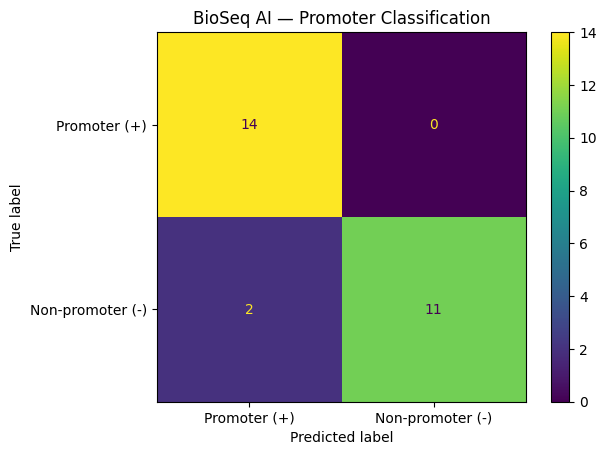

In [ ]:
# BIOSEQ AI — TRAIN AND EVALUATE ML MODEL

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Features and labels
X = df["Sequence"]
y = df["Class"]

# Split before training; preserve class balance
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Character n-grams + Logistic Regression
model = Pipeline([
    ("vectorizer", CountVectorizer(
        analyzer="char",
        ngram_range=(2, 3)
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train only on the training data
model.fit(X_train, y_train)

# Evaluate on held-out test data
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("========== BIOSEQ AI ML RESULTS ==========")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"Test accuracy: {accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["+", "-"],
    target_names=["Promoter (+)", "Non-promoter (-)"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=["+", "-"])

display_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Promoter (+)", "Non-promoter (-)"]
)

display_plot.plot()
plt.title("BioSeq AI — Promoter Classification")
plt.show()

In [ ]:
print("Model available:", "model" in globals())
print("Model type:", type(model).__name__ if "model" in globals() else "Missing")

if "model" in globals():
    print("Pipeline steps:", list(model.named_steps.keys()))
    print("Training completed:", hasattr(model, "classes_"))
    print("Classes:", model.classes_ if hasattr(model, "classes_") else "Not available")

Model available: True
Model type: Pipeline
Pipeline steps: ['vectorizer', 'classifier']
Training completed: True
Classes: ['+' '-']


In [ ]:
# BIOSEQ AI — SAVE TRAINED MODEL

import joblib
import json

MODEL_FILE = "bioseq_ai_promoter_model.joblib"
METRICS_FILE = "bioseq_ai_model_metrics.json"

# Save the complete trained pipeline
joblib.dump(model, MODEL_FILE)

# Save actual evaluation metrics
metrics = {
    "model_name": "Character N-gram Logistic Regression",
    "dataset": "UCI Molecular Biology Promoter Sequences",
    "total_samples": int(len(df)),
    "training_samples": int(len(X_train)),
    "testing_samples": int(len(X_test)),
    "test_accuracy_percent": round(float(accuracy) * 100, 2)
}

with open(METRICS_FILE, "w") as file:
    json.dump(metrics, file, indent=4)

print("Model saved:", MODEL_FILE)
print("Metrics saved:", METRICS_FILE)

# Verify that the saved model can be loaded
loaded_model = joblib.load(MODEL_FILE)

sample_sequence = X_test.iloc[0]
prediction = loaded_model.predict([sample_sequence])[0]

print("\nModel reload test: PASSED")
print("Sample sequence length:", len(sample_sequence))
print("Predicted class:", prediction)
print("Actual class:", y_test.iloc[0])

Model saved: bioseq_ai_promoter_model.joblib
Metrics saved: bioseq_ai_model_metrics.json

Model reload test: PASSED
Sample sequence length: 57
Predicted class: -
Actual class: -


In [ ]:
# BIOSEQ AI — PRE-APP CHECK

required_items = [
    "validate_dna",
    "analyze_dna",
    "codon_table_df",
    "search_codon",
    "translate_six_frames",
    "compare_dna_sequences",
    "translate_dna",
    "model",
    "df",
    "accuracy"
]

missing_items = [
    name for name in required_items
    if name not in globals()
]

if missing_items:
    print("Missing items:", missing_items)
    print("We need to restore these before building the app.")
else:
    print("All required modules are available!")
    print("DNA samples:", len(df))
    print("Codons:", len(codon_table_df))
    print(f"Model test accuracy: {accuracy * 100:.2f}%")
    print("\nReady to build the Gradio interface!")

All required modules are available!
DNA samples: 106
Codons: 64
Model test accuracy: 92.59%

Ready to build the Gradio interface!


In [ ]:
# BIOSEQ AI — RESTORE CORE FUNCTIONS

from collections import Counter
from itertools import product

import pandas as pd
from Bio.Seq import Seq
from Bio.Data import CodonTable
from Bio import Align


# ==================================================
# 1. DNA VALIDATION
# ==================================================

def validate_dna(sequence):
    if not isinstance(sequence, str) or not sequence.strip():
        return False, "Please enter a DNA sequence."

    cleaned = "".join(sequence.upper().split())
    invalid = sorted(set(cleaned) - set("ATGC"))

    if invalid:
        return False, "Invalid characters: " + ", ".join(invalid)

    return True, cleaned


# ==================================================
# 2. DNA ANALYSIS
# ==================================================

def analyze_dna(sequence):
    valid, result = validate_dna(sequence)

    if not valid:
        return {"error": result}

    dna = result
    counts = Counter(dna)
    length = len(dna)

    a = counts.get("A", 0)
    t = counts.get("T", 0)
    g = counts.get("G", 0)
    c = counts.get("C", 0)

    return {
        "sequence": dna,
        "length": length,
        "A": a,
        "T": t,
        "G": g,
        "C": c,
        "GC_count": g + c,
        "GC_percent": round((g + c) / length * 100, 2),
        "AT_percent": round((a + t) / length * 100, 2)
    }


# ==================================================
# 3. CODON TABLE AND SEARCH
# ==================================================

GENETIC_CODE = CodonTable.unambiguous_dna_by_name["Standard"]

AMINO_ACID_NAMES = {
    "A": ("Alanine", "Ala"),
    "R": ("Arginine", "Arg"),
    "N": ("Asparagine", "Asn"),
    "D": ("Aspartic acid", "Asp"),
    "C": ("Cysteine", "Cys"),
    "Q": ("Glutamine", "Gln"),
    "E": ("Glutamic acid", "Glu"),
    "G": ("Glycine", "Gly"),
    "H": ("Histidine", "His"),
    "I": ("Isoleucine", "Ile"),
    "L": ("Leucine", "Leu"),
    "K": ("Lysine", "Lys"),
    "M": ("Methionine", "Met"),
    "F": ("Phenylalanine", "Phe"),
    "P": ("Proline", "Pro"),
    "S": ("Serine", "Ser"),
    "T": ("Threonine", "Thr"),
    "W": ("Tryptophan", "Trp"),
    "Y": ("Tyrosine", "Tyr"),
    "V": ("Valine", "Val")
}

CODON_ROWS = []

for bases in product("TCAG", repeat=3):
    codon = "".join(bases)

    if codon in GENETIC_CODE.stop_codons:
        row = {
            "Codon": codon,
            "Amino Acid": "Stop",
            "Three Letter": "Ter",
            "One Letter": "*",
            "Type": "Stop"
        }
    else:
        aa = GENETIC_CODE.forward_table[codon]
        full_name, three_letter = AMINO_ACID_NAMES[aa]

        row = {
            "Codon": codon,
            "Amino Acid": full_name,
            "Three Letter": three_letter,
            "One Letter": aa,
            "Type": "Start" if codon == "ATG" else "Standard"
        }

    CODON_ROWS.append(row)

codon_table_df = (
    pd.DataFrame(CODON_ROWS)
    .sort_values("Codon")
    .reset_index(drop=True)
)


def search_codon(query):
    query = str(query).strip().lower()

    if not query:
        return codon_table_df.copy()

    mask = codon_table_df.apply(
        lambda row: row.astype(str)
        .str.lower()
        .str.contains(query, regex=False)
        .any(),
        axis=1
    )

    return codon_table_df[mask].reset_index(drop=True)


# ==================================================
# 4. SIX-FRAME TRANSLATION
# ==================================================

def translate_six_frames(sequence):
    valid, result = validate_dna(sequence)

    if not valid:
        return {"error": result}

    dna = Seq(result)
    reverse_dna = dna.reverse_complement()
    output = {}

    for strand_name, strand in [
        ("Forward", dna),
        ("Reverse", reverse_dna)
    ]:
        for frame in range(3):
            framed = strand[frame:]
            usable_length = (len(framed) // 3) * 3
            coding = framed[:usable_length]

            output[f"{strand_name} frame {frame + 1}"] = str(
                coding.translate()
            )

    return output


# ==================================================
# 5. DNA SEQUENCE COMPARISON
# ==================================================

def compare_dna_sequences(reference, test):
    ref_valid, ref_result = validate_dna(reference)
    test_valid, test_result = validate_dna(test)

    if not ref_valid:
        return {"error": f"Reference: {ref_result}"}

    if not test_valid:
        return {"error": f"Test: {test_result}"}

    reference = ref_result
    test = test_result

    aligner = Align.PairwiseAligner()
    aligner.mode = "global"
    aligner.match_score = 2
    aligner.mismatch_score = -1
    aligner.open_gap_score = -3
    aligner.extend_gap_score = -0.5

    alignment = aligner.align(reference, test)[0]

    # Reconstruct the alignment from its coordinate path.
    aligned_ref_parts = []
    aligned_test_parts = []
    coordinates = alignment.coordinates

    for i in range(coordinates.shape[1] - 1):
        r0, r1 = int(coordinates[0, i]), int(coordinates[0, i + 1])
        t0, t1 = int(coordinates[1, i]), int(coordinates[1, i + 1])

        if r1 > r0 and t1 > t0:
            aligned_ref_parts.append(reference[r0:r1])
            aligned_test_parts.append(test[t0:t1])

        elif r1 > r0:
            aligned_ref_parts.append(reference[r0:r1])
            aligned_test_parts.append("-" * (r1 - r0))

        elif t1 > t0:
            aligned_ref_parts.append("-" * (t1 - t0))
            aligned_test_parts.append(test[t0:t1])

    aligned_reference = "".join(aligned_ref_parts)
    aligned_test = "".join(aligned_test_parts)

    differences = []
    matches = 0
    ref_position = 0
    test_position = 0

    for column, (ref_base, test_base) in enumerate(
        zip(aligned_reference, aligned_test), start=1
    ):
        if ref_base != "-":
            ref_position += 1

        if test_base != "-":
            test_position += 1

        if ref_base == test_base:
            matches += 1
            continue

        if ref_base == "-":
            variation = "Insertion"
        elif test_base == "-":
            variation = "Deletion"
        else:
            variation = "Substitution"

        differences.append({
            "Alignment position": column,
            "Reference position": ref_position,
            "Test position": test_position,
            "Reference base": ref_base,
            "Test base": test_base,
            "Variation": variation
        })

    alignment_length = len(aligned_reference)

    return {
        "reference_length": len(reference),
        "test_length": len(test),
        "alignment_length": alignment_length,
        "matches": matches,
        "substitution_count": sum(
            d["Variation"] == "Substitution" for d in differences
        ),
        "insertion_count": sum(
            d["Variation"] == "Insertion" for d in differences
        ),
        "deletion_count": sum(
            d["Variation"] == "Deletion" for d in differences
        ),
        "identity_percent": round(
            matches / alignment_length * 100, 2
        ) if alignment_length else 0,
        "reference_coverage_percent": 100.0 if reference else 0,
        "aligned_reference": aligned_reference,
        "aligned_test": aligned_test,
        "differences": differences,
        "alignment_score": float(alignment.score)
    }


# ==================================================
# 6. PROTEIN TRANSLATION
# ==================================================

def translate_dna(sequence, frame=0, strand="Forward"):
    valid, result = validate_dna(sequence)

    if not valid:
        return {"error": result}

    if frame not in (0, 1, 2):
        return {"error": "Frame must be 0, 1, or 2."}

    dna = Seq(result)

    if strand == "Reverse":
        dna = dna.reverse_complement()
    elif strand != "Forward":
        return {"error": "Strand must be Forward or Reverse."}

    framed_dna = dna[frame:]
    usable_length = (len(framed_dna) // 3) * 3
    coding_dna = framed_dna[:usable_length]

    return {
        "strand": strand,
        "frame": frame,
        "DNA sequence": str(coding_dna),
        "Protein sequence": str(coding_dna.translate()),
        "Complete codons": len(coding_dna) // 3,
        "Ignored trailing bases": len(framed_dna) - usable_length
    }


print("All seven core functions have been restored!")
print("Codon table rows:", len(codon_table_df))

All seven core functions have been restored!
Codon table rows: 64


In [ ]:
print("DNA analysis:", analyze_dna("ATGCGCTA"))
print("\nCodon search:")
display(search_codon("Methionine"))

print("\nProtein translation:")
print(translate_dna("ATGGCTTTTTAA"))

print("\nSequence comparison:")
print(compare_dna_sequences("ATGC", "ATGGC"))

print("\nSix-frame translation:")
print(translate_six_frames("ATGGCTTTTTAA").keys())

DNA analysis: {'sequence': 'ATGCGCTA', 'length': 8, 'A': 2, 'T': 2, 'G': 2, 'C': 2, 'GC_count': 4, 'GC_percent': 50.0, 'AT_percent': 50.0}

Codon search:


,Codon,Amino Acid,Three Letter,One Letter,Type
0,ATG,Methionine,Met,M,Start



Protein translation:
{'strand': 'Forward', 'frame': 0, 'DNA sequence': 'ATGGCTTTTTAA', 'Protein sequence': 'MAF*', 'Complete codons': 4, 'Ignored trailing bases': 0}

Sequence comparison:
{'reference_length': 4, 'test_length': 5, 'alignment_length': 5, 'matches': 4, 'substitution_count': 0, 'insertion_count': 1, 'deletion_count': 0, 'identity_percent': 80.0, 'reference_coverage_percent': 100.0, 'aligned_reference': 'AT-GC', 'aligned_test': 'ATGGC', 'differences': [{'Alignment position': 3, 'Reference position': 2, 'Test position': 3, 'Reference base': '-', 'Test base': 'G', 'Variation': 'Insertion'}], 'alignment_score': 5.0}

Six-frame translation:
dict_keys(['Forward frame 1', 'Forward frame 2', 'Forward frame 3', 'Reverse frame 1', 'Reverse frame 2', 'Reverse frame 3'])


In [ ]:
print("Model available:", "model" in globals())
print("Dataset available:", "df" in globals())
print("Accuracy available:", "accuracy" in globals())
print("Gradio available:", "gr" in globals())

Model available: True
Dataset available: True
Accuracy available: True
Gradio available: True


In [ ]:
%pip install -q gradio

In [ ]:
import gradio as gr

print("Gradio version:", gr.__version__)
print("Gradio is ready!")

Gradio version: 6.30.0
Gradio is ready!


In [ ]:
required_items = [
"validate_dna",
"analyze_dna",
"codon_table_df",
"search_codon",
"translate_six_frames",
"compare_dna_sequences",
"translate_dna",
"model",
"df",
"accuracy",
"gr"
]

for item in required_items:
    status = "READY" if item in globals() else "MISSING"
    print(f"{item}: {status}")


validate_dna: READY
analyze_dna: READY
codon_table_df: READY
search_codon: READY
translate_six_frames: READY
compare_dna_sequences: READY
translate_dna: READY
model: READY
df: READY
accuracy: READY
gr: READY


In [ ]:
# ============================================================
# BIOSEQ AI — INTEGRATED BIOINFORMATICS DASHBOARD
# ============================================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import json
import os
import tempfile
from datetime import datetime
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. CHECK REQUIRED COMPONENTS
# ------------------------------------------------------------

required = [
    "validate_dna", "analyze_dna", "codon_table_df",
    "search_codon", "translate_six_frames",
    "compare_dna_sequences", "translate_dna",
    "model", "df", "accuracy"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Missing components: " + ", ".join(missing)
        + ". Please restore these components first."
    )

print("All required components are available.")


# ------------------------------------------------------------
# 2. HELPER FUNCTIONS
# ------------------------------------------------------------

def safe_json(data):
    """Convert values to JSON-friendly Python types."""
    return json.loads(json.dumps(data, default=str))


def analyze_callback(sequence):
    result = analyze_dna(sequence)

    if "error" in result:
        return result, None, None

    labels = ["A", "T", "G", "C"]
    counts = [result[x] for x in labels]
    percentages = [
        round(result[x] / result["length"] * 100, 2)
        for x in labels
    ]

    fig1, ax1 = plt.subplots(figsize=(6, 4))
    ax1.bar(labels, counts)
    ax1.set_title("Nucleotide Counts")
    ax1.set_xlabel("Nucleotide")
    ax1.set_ylabel("Count")
    ax1.grid(axis="y", alpha=0.25)
    fig1.tight_layout()

    fig2, ax2 = plt.subplots(figsize=(6, 4))
    ax2.pie(
        percentages,
        labels=labels,
        autopct="%1.1f%%",
        startangle=90
    )
    ax2.set_title("Nucleotide Composition (%)")
    fig2.tight_layout()

    detailed = {
        **result,
        "A_percent": percentages[0],
        "T_percent": percentages[1],
        "G_percent": percentages[2],
        "C_percent": percentages[3],
        "Total_AT_count": result["A"] + result["T"],
        "Total_GC_count": result["G"] + result["C"],
        "Validation": "Valid DNA sequence",
        "Sequence_length_is_zero": False
    }

    return safe_json(detailed), fig1, fig2


def codon_callback(query):
    return search_codon(query)


def comparison_callback(reference, test):
    result = compare_dna_sequences(reference, test)

    if "error" in result:
        return safe_json(result), pd.DataFrame(), ""

    differences = pd.DataFrame(result["differences"])

    alignment_text = (
        f"Reference: {result['aligned_reference']}\n"
        f"Test:      {result['aligned_test']}\n\n"
        f"Alignment score: {result['alignment_score']}\n"
        f"Identity: {result['identity_percent']}%"
    )

    return safe_json(result), differences, alignment_text


def protein_callback(sequence, frame, strand):
    result = translate_dna(
        sequence,
        frame=int(frame),
        strand=strand
    )

    if "error" in result:
        return safe_json(result), pd.DataFrame()

    protein = result["Protein sequence"]

    codon_rows = []
    dna = result["DNA sequence"]

    for i in range(0, len(dna), 3):
        codon = dna[i:i+3]
        row = codon_table_df[
            codon_table_df["Codon"] == codon
        ]

        if not row.empty:
            info = row.iloc[0].to_dict()
            codon_rows.append({
                "Codon Number": i // 3 + 1,
                "DNA Codon": codon,
                "Amino Acid": info["Amino Acid"],
                "Three Letter": info["Three Letter"],
                "One Letter": info["One Letter"],
                "Codon Type": info["Type"]
            })

    result["Protein_length_including_stop_symbols"] = len(protein)
    result["Stop_codon_count"] = protein.count("*")
    result["Contains_start_codon_at_selected_frame_start"] = (
        dna.startswith("ATG") if strand == "Forward" else False
    )

    return safe_json(result), pd.DataFrame(codon_rows)


def six_frame_callback(sequence):
    result = translate_six_frames(sequence)

    if "error" in result:
        return pd.DataFrame(), safe_json(result)

    table = pd.DataFrame([
        {"Reading Frame": frame, "Protein Sequence": protein}
        for frame, protein in result.items()
    ])

    return table, safe_json(result)


def promoter_callback(sequence):
    valid, cleaned = validate_dna(sequence)

    if not valid:
        return safe_json({"error": cleaned}), pd.DataFrame()

    # The training dataset contains 57-base sequences.
    if len(cleaned) != 57:
        return safe_json({
            "error": "This model was trained on 57-base sequences.",
            "input_length": len(cleaned),
            "required_length": 57,
            "message": "Enter a valid 57-base DNA sequence."
        }), pd.DataFrame()

    prediction = model.predict([cleaned])[0]

    probabilities = {}
    if hasattr(model, "predict_proba"):
        probs = model.predict_proba([cleaned])[0]
        classes = model.classes_

        probabilities = {
            str(label): round(float(prob) * 100, 2)
            for label, prob in zip(classes, probs)
        }

    readable = (
        "Promoter (+)" if prediction == "+"
        else "Non-promoter (-)"
    )

    result = {
        "Input sequence": cleaned,
        "Sequence length": len(cleaned),
        "Predicted class": readable,
        "Predicted label": str(prediction),
        "Model": "Character N-gram Logistic Regression",
        "Dataset": "UCI Molecular Biology Promoter Sequences",
        "Dataset size": len(df),
        "Previously measured test accuracy (%)": round(
            float(accuracy) * 100, 2
        ),
        "Prediction probabilities (%)": probabilities,
        "Important limitation": (
            "Educational prediction only. This small dataset and model "
            "cannot establish biological function or diagnose disease."
        )
    }

    probability_table = pd.DataFrame([
        {"Class": str(label), "Model probability (%)": value}
        for label, value in probabilities.items()
    ])

    return safe_json(result), probability_table


def performance_callback():
    from sklearn.model_selection import train_test_split

    X = df["Sequence"]
    y = df["Class"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.25,
        random_state=42,
        stratify=y
    )

    # Evaluate a fresh model on the same reproducible split.
    # This is a holdout evaluation, not an independent external validation.
    from sklearn.pipeline import Pipeline
    from sklearn.feature_extraction.text import CountVectorizer
    from sklearn.linear_model import LogisticRegression

    evaluation_model = Pipeline([
        (
            "vectorizer",
            CountVectorizer(analyzer="char", ngram_range=(2, 3))
        ),
        (
            "classifier",
            LogisticRegression(max_iter=2000, random_state=42)
        )
    ])

    evaluation_model.fit(X_train, y_train)
    predictions = evaluation_model.predict(X_test)

    metrics = {
        "Dataset samples": int(len(df)),
        "Training samples": int(len(X_train)),
        "Test samples": int(len(X_test)),
        "Accuracy (%)": round(
            accuracy_score(y_test, predictions) * 100, 2
        ),
        "Macro precision (%)": round(
            precision_score(
                y_test, predictions, average="macro",
                zero_division=0
            ) * 100, 2
        ),
        "Macro recall (%)": round(
            recall_score(
                y_test, predictions, average="macro",
                zero_division=0
            ) * 100, 2
        ),
        "Macro F1-score (%)": round(
            f1_score(
                y_test, predictions, average="macro",
                zero_division=0
            ) * 100, 2
        ),
        "Dataset class counts": {
            str(k): int(v)
            for k, v in df["Class"].value_counts().items()
        },
        "Evaluation note": (
            "Small dataset; metrics depend on the chosen split and "
            "do not establish generalization to other biological data."
        )
    }

    cm = confusion_matrix(
        y_test, predictions, labels=["+", "-"]
    )

    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(cm)
    ax.set_title("Confusion Matrix")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.set_xticks([0, 1], ["Promoter (+)", "Non-promoter (-)"])
    ax.set_yticks([0, 1], ["Promoter (+)", "Non-promoter (-)"])

    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")

    fig.tight_layout()

    report = classification_report(
        y_test,
        predictions,
        labels=["+", "-"],
        target_names=["Promoter (+)", "Non-promoter (-)"],
        zero_division=0,
        output_dict=True
    )

    return safe_json(metrics), pd.DataFrame(report).transpose(), fig


def export_results(sequence, reference, test):
    """Create a downloadable JSON report from current inputs."""
    report = {
        "project": "BioSeq AI",
        "generated_at": datetime.now().isoformat(),
        "dna_analysis": analyze_dna(sequence),
        "sequence_comparison": compare_dna_sequences(reference, test),
        "note": (
            "Educational prototype; results are not medical diagnoses. "
            "Only included analyses are computed in this report."
        )
    }

    fd, path = tempfile.mkstemp(suffix=".json")
    os.close(fd)

    with open(path, "w", encoding="utf-8") as f:
        json.dump(report, f, indent=2, ensure_ascii=False, default=str)

    return path


# ------------------------------------------------------------
# 3. BUILD THE USER INTERFACE
# ------------------------------------------------------------

with gr.Blocks(
    title="BioSeq AI — Bioinformatics Dashboard",
    theme=gr.themes.Soft()
) as demo:

    gr.Markdown("""
    # 🧬 BioSeq AI
    ### DNA Analysis • Codon Explorer • Sequence Comparison • AI Promoter Classification

    **Educational bioinformatics prototype.**
    This tool is not a clinical diagnostic system. Do not enter private or
    sensitive genetic information.
    """)

    with gr.Tabs():

        # TAB 1 — DNA ANALYZER
        with gr.Tab("🧬 DNA Analyzer"):
            gr.Markdown("### Nucleotide composition and sequence statistics")

            dna_input = gr.Textbox(
                label="Enter DNA sequence",
                placeholder="Example: ATGCGCTA",
                value="ATGCGCTA",
                lines=3
            )

            dna_button = gr.Button("Analyze DNA", variant="primary")

            dna_output = gr.JSON(label="Complete DNA Analysis Parameters")

            with gr.Row():
                dna_bar = gr.Plot(label="Nucleotide Counts")
                dna_pie = gr.Plot(label="Nucleotide Composition")

            dna_button.click(
                analyze_callback,
                inputs=dna_input,
                outputs=[dna_output, dna_bar, dna_pie]
            )

        # TAB 2 — CODON EXPLORER
        with gr.Tab("🧬 Codon Explorer"):
            gr.Markdown("""
            ### Search the standard genetic code
            Search by codon, full amino-acid name, three-letter abbreviation,
            or one-letter amino-acid code. Leave blank to display all 64 codons.
            """)

            codon_query = gr.Textbox(
                label="Search codon or amino acid",
                placeholder="Examples: ATG, Methionine, Met"
            )

            codon_button = gr.Button("Search Codons", variant="primary")

            codon_output = gr.Dataframe(
                label="Codon Search Results",
                interactive=False
            )

            codon_button.click(
                codon_callback,
                inputs=codon_query,
                outputs=codon_output
            )

            gr.Markdown("### Complete 64-codon reference table")

            gr.Dataframe(
                value=codon_table_df,
                label="Standard Genetic Code",
                interactive=False
            )

        # TAB 3 — SEQUENCE COMPARISON
        with gr.Tab("🔬 Sequence Comparison"):
            gr.Markdown("""
            ### Compare a reference DNA sequence with a test sequence
            """)

            reference_input = gr.Textbox(
                label="Reference sequence",
                value="ATGCCGTAA",
                lines=2
            )

            test_input = gr.Textbox(
                label="Test sequence",
                value="ATGTCGTTAA",
                lines=2
            )

            compare_button = gr.Button(
                "Compare Sequences",
                variant="primary"
            )

            compare_output = gr.JSON(
                label="Alignment and Comparison Parameters"
            )

            alignment_output = gr.Textbox(
                label="Aligned Sequences",
                lines=4,
                interactive=False
            )

            differences_output = gr.Dataframe(
                label="Substitutions, Insertions and Deletions",
                interactive=False
            )

            compare_button.click(
                comparison_callback,
                inputs=[reference_input, test_input],
                outputs=[
                    compare_output,
                    differences_output,
                    alignment_output
                ]
            )

        # TAB 4 — PROTEIN TRANSLATION
        with gr.Tab("🧪 Protein Translation"):
            gr.Markdown("""
            ### Translate DNA into an amino-acid sequence
            Frames are numbered 0, 1 and 2 in the underlying Python function.
            """)

            protein_input = gr.Textbox(
                label="DNA sequence",
                value="ATGGCTTTTTAA",
                lines=2
            )

            with gr.Row():
                frame_input = gr.Dropdown(
                    choices=[0, 1, 2],
                    value=0,
                    label="Reading frame"
                )

                strand_input = gr.Dropdown(
                    choices=["Forward", "Reverse"],
                    value="Forward",
                    label="Strand"
                )

            protein_button = gr.Button(
                "Translate Protein",
                variant="primary"
            )

            protein_output = gr.JSON(
                label="Translation Parameters"
            )

            protein_table = gr.Dataframe(
                label="Codon-by-Codon Translation",
                interactive=False
            )

            protein_button.click(
                protein_callback,
                inputs=[protein_input, frame_input, strand_input],
                outputs=[protein_output, protein_table]
            )

            gr.Markdown("### Six-frame translation")

            six_input = gr.Textbox(
                label="DNA sequence for six-frame translation",
                value="ATGGCTTTTTAA",
                lines=2
            )

            six_button = gr.Button("Translate All Six Frames")

            six_table = gr.Dataframe(
                label="All Six Reading Frames",
                interactive=False
            )

            six_details = gr.JSON(
                label="Six-Frame Translation Details"
            )

            six_button.click(
                six_frame_callback,
                inputs=six_input,
                outputs=[six_table, six_details]
            )

        # TAB 5 — AI PROMOTER CLASSIFIER
        with gr.Tab("🤖 AI Promoter Classifier"):
            gr.Markdown("""
            ### Educational promoter-sequence classification

            The current model was trained using the UCI Molecular Biology
            Promoter Sequences dataset. Its sequences are 57 bases long.

            **Important:** This prediction does not prove gene function,
            diagnose a disease, or establish clinical significance.
            """)

            promoter_input = gr.Textbox(
                label="Enter a 57-base DNA sequence",
                placeholder="Paste a 57-base sequence containing A, T, G and C",
                lines=3
            )

            promoter_button = gr.Button(
                "Classify Sequence",
                variant="primary"
            )

            promoter_output = gr.JSON(
                label="Prediction and Model Information"
            )

            promoter_probs = gr.Dataframe(
                label="Model Prediction Probabilities",
                interactive=False
            )

            promoter_button.click(
                promoter_callback,
                inputs=promoter_input,
                outputs=[promoter_output, promoter_probs]
            )

        # TAB 6 — MODEL PERFORMANCE
        with gr.Tab("📊 Model Performance"):
            gr.Markdown("""
            ### Evaluate the promoter classifier

            Metrics below are recalculated using a reproducible stratified
            train/test split. A small test set can produce unstable estimates.
            """)

            metrics_button = gr.Button(
                "Calculate Model Metrics",
                variant="primary"
            )

            metrics_output = gr.JSON(
                label="Model Evaluation Metrics"
            )

            report_output = gr.Dataframe(
                label="Precision, Recall and F1-score Report",
                interactive=False
            )

            confusion_plot = gr.Plot(
                label="Confusion Matrix"
            )

            metrics_button.click(
                performance_callback,
                inputs=[],
                outputs=[
                    metrics_output,
                    report_output,
                    confusion_plot
                ]
            )

        # TAB 7 — EXPORT
        with gr.Tab("📥 Export Results"):
            gr.Markdown("""
            ### Export analysis results

            Enter your DNA sequence and reference/test sequences.
            The JSON report includes these analyses and their calculated
            parameters. It does not include every tab's output.
            """)

            export_dna = gr.Textbox(
                label="DNA sequence",
                value="ATGCGCTA"
            )

            export_reference = gr.Textbox(
                label="Reference sequence",
                value="ATGCCGTAA"
            )

            export_test = gr.Textbox(
                label="Test sequence",
                value="ATGTCGTTAA"
            )

            export_button = gr.Button(
                "Generate JSON Report",
                variant="primary"
            )

            export_file = gr.File(label="Download JSON Report")

            export_button.click(
                export_results,
                inputs=[
                    export_dna,
                    export_reference,
                    export_test
                ],
                outputs=export_file
            )

    gr.Markdown("""
    ---
    **BioSeq AI | Educational Prototype**

    Predictions and sequence comparisons depend on the input, algorithms,
    dataset and reference information. Results must not be interpreted as
    medical advice or a clinical diagnosis.
    """)


# ------------------------------------------------------------
# 4. LAUNCH DASHBOARD
# ------------------------------------------------------------

print("BioSeq AI dashboard is starting...")

demo.launch(share=True)

All required components are available.


/tmp/ipykernel_416/1742547609.py:359: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


BioSeq AI dashboard is starting...
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://121518628e7930c215.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from collections import Counter
from itertools import product
import math
import pandas as pd

def advanced_dna_analysis(sequence):

    # 1. Validate DNA
    valid, result = validate_dna(sequence)

    if not valid:
        return {"error": result}, pd.DataFrame(), pd.DataFrame()

    dna = result
    length = len(dna)

    # 2. Nucleotide counts and percentages
    nucleotide_counts = Counter(dna)

    nucleotide_data = []

    for nucleotide in "ATGC":
        count = nucleotide_counts.get(nucleotide, 0)

        nucleotide_data.append({
            "Nucleotide": nucleotide,
            "Count": count,
            "Percentage": round(count / length * 100, 2)
        })

    nucleotide_df = pd.DataFrame(nucleotide_data)

    # 3. GC and AT statistics
    gc_count = nucleotide_counts.get("G", 0) + nucleotide_counts.get("C", 0)
    at_count = nucleotide_counts.get("A", 0) + nucleotide_counts.get("T", 0)

    gc_percent = gc_count / length * 100
    at_percent = at_count / length * 100

    gc_at_ratio = gc_count / at_count if at_count else None

    # 4. Dinucleotide frequencies: 16 possible combinations
    dinucleotide_counts = Counter(
        dna[i:i+2] for i in range(length - 1)
    )

    dinucleotide_data = []

    for bases in product("ATGC", repeat=2):
        motif = "".join(bases)
        count = dinucleotide_counts.get(motif, 0)

        dinucleotide_data.append({
            "Dinucleotide": motif,
            "Count": count,
            "Percentage of overlapping windows": (
                round(count / (length - 1) * 100, 2)
                if length >= 2 else 0
            )
        })

    dinucleotide_df = pd.DataFrame(dinucleotide_data)

    # 5. Trinucleotide frequencies: 64 possible combinations
    trinucleotide_counts = Counter(
        dna[i:i+3] for i in range(length - 2)
    )

    trinucleotide_data = []

    for bases in product("ATGC", repeat=3):
        motif = "".join(bases)
        count = trinucleotide_counts.get(motif, 0)

        trinucleotide_data.append({
            "Trinucleotide": motif,
            "Count": count,
            "Percentage of overlapping windows": (
                round(count / (length - 2) * 100, 2)
                if length >= 3 else 0
            )
        })

    trinucleotide_df = pd.DataFrame(trinucleotide_data)

    # 6. Shannon nucleotide entropy
    entropy = 0.0

    for nucleotide in "ATGC":
        count = nucleotide_counts.get(nucleotide, 0)

        if count:
            probability = count / length
            entropy -= probability * math.log2(probability)

    # 7. Longest consecutive run of the same nucleotide
    longest_run = 1
    current_run = 1
    longest_run_base = dna[0]

    for i in range(1, length):
        if dna[i] == dna[i - 1]:
            current_run += 1

            if current_run > longest_run:
                longest_run = current_run
                longest_run_base = dna[i]
        else:
            current_run = 1

    # 8. Distinct k-mers and sequence complexity
    distinct_dinucleotides = len(dinucleotide_counts)
    distinct_trinucleotides = len(trinucleotide_counts)

    # 9. Summary
    summary = {
        "Sequence": dna,
        "Sequence length": length,
        "A count": nucleotide_counts.get("A", 0),
        "T count": nucleotide_counts.get("T", 0),
        "G count": nucleotide_counts.get("G", 0),
        "C count": nucleotide_counts.get("C", 0),
        "GC count": gc_count,
        "AT count": at_count,
        "GC percentage": round(gc_percent, 2),
        "AT percentage": round(at_percent, 2),
        "GC/AT ratio": round(gc_at_ratio, 4) if gc_at_ratio is not None else None,
        "Nucleotide entropy (bits)": round(entropy, 4),
        "Maximum possible nucleotide entropy (bits)": 2.0,
        "Longest consecutive repeat length": longest_run,
        "Base in longest repeat": longest_run_base,
        "Distinct dinucleotides observed": distinct_dinucleotides,
        "Possible dinucleotides": 16,
        "Distinct trinucleotides observed": distinct_trinucleotides,
        "Possible trinucleotides": 64
    }

    return summary, dinucleotide_df, trinucleotide_df


print("Advanced DNA Statistics function is ready!")

Advanced DNA Statistics function is ready!


In [ ]:
summary, dinucleotides, trinucleotides = advanced_dna_analysis(
    "ATGCGCTA"
)

print("========== ADVANCED DNA ANALYSIS ==========")

for parameter, value in summary.items():
    print(f"{parameter}: {value}")

print("\n========== DINUCLEOTIDE FREQUENCIES ==========")
display(dinucleotides)

print("\n========== TRINUCLEOTIDE FREQUENCIES ==========")
display(trinucleotides)

========== ADVANCED DNA ANALYSIS ==========
Sequence: ATGCGCTA
Sequence length: 8
A count: 2
T count: 2
G count: 2
C count: 2
GC count: 4
AT count: 4
GC percentage: 50.0
AT percentage: 50.0
GC/AT ratio: 1.0
Nucleotide entropy (bits): 2.0
Maximum possible nucleotide entropy (bits): 2.0
Longest consecutive repeat length: 1
Base in longest repeat: A
Distinct dinucleotides observed: 6
Possible dinucleotides: 16
Distinct trinucleotides observed: 6
Possible trinucleotides: 64

========== DINUCLEOTIDE FREQUENCIES ==========


,Dinucleotide,Count,Percentage of overlapping windows
0,AA,0,0.00
1,AT,1,14.29
2,AG,0,0.00
3,AC,0,0.00
4,TA,1,14.29
5,TT,0,0.00
6,TG,1,14.29
7,TC,0,0.00
8,GA,0,0.00
9,GT,0,0.00



========== TRINUCLEOTIDE FREQUENCIES ==========


,Trinucleotide,Count,Percentage of overlapping windows
0,AAA,0,0.00
1,AAT,0,0.00
2,AAG,0,0.00
3,AAC,0,0.00
4,ATA,0,0.00
...,...,...,...
59,CGC,1,16.67
60,CCA,0,0.00
61,CCT,0,0.00
62,CCG,0,0.00


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

def gc_sliding_window(sequence, window_size=10, step_size=1):

    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(result)

    dna = result

    if not isinstance(window_size, int) or isinstance(window_size, bool):
        raise ValueError("Window size must be an integer.")

    if not isinstance(step_size, int) or isinstance(step_size, bool):
        raise ValueError("Step size must be an integer.")

    if window_size < 1:
        raise ValueError("Window size must be at least 1.")

    if step_size < 1:
        raise ValueError("Step size must be at least 1.")

    if window_size > len(dna):
        raise ValueError("Window size cannot exceed DNA sequence length.")

    results = []

    for start in range(0, len(dna) - window_size + 1, step_size):

        window = dna[start:start + window_size]

        gc_count = window.count("G") + window.count("C")
        gc_percent = (gc_count / window_size) * 100

        results.append({
            "Start Position": start + 1,
            "End Position": start + window_size,
            "DNA Window": window,
            "GC Count": gc_count,
            "GC Percentage": round(gc_percent, 2)
        })

    return pd.DataFrame(results)


def plot_gc_sliding_window(sequence, window_size=10, step_size=1):

    gc_data = gc_sliding_window(
        sequence,
        window_size=window_size,
        step_size=step_size
    )

    plt.figure(figsize=(10, 5))

    plt.plot(
        gc_data["Start Position"],
        gc_data["GC Percentage"],
        marker="o"
    )

    plt.xlabel("DNA Sequence Position")
    plt.ylabel("GC Content (%)")
    plt.title(f"GC Sliding-Window Analysis (Window = {window_size})")

    plt.ylim(0, 100)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return gc_data


print("GC Sliding-Window Analysis is ready!")

GC Sliding-Window Analysis is ready!


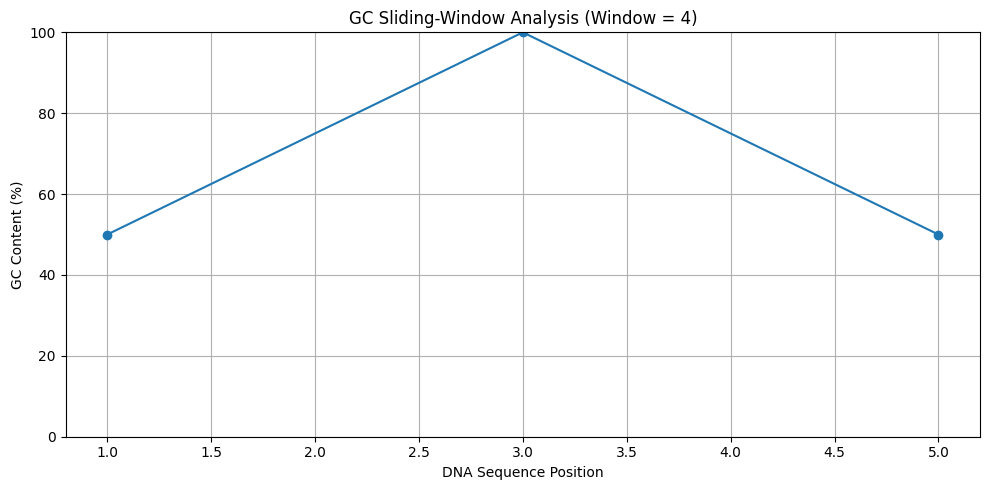

,Start Position,End Position,DNA Window,GC Count,GC Percentage
0,1,4,ATGC,2,50.0
1,3,6,GCGC,4,100.0
2,5,8,GCTA,2,50.0


In [ ]:
test_sequence = "ATGCGCTA"

gc_results = plot_gc_sliding_window(
    test_sequence,
    window_size=4,
    step_size=2
)

display(gc_results)

In [ ]:
from Bio.Seq import Seq
import pandas as pd

def detect_orfs(sequence, min_length=1):

    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(result)

    dna = result

    if not isinstance(min_length, int) or isinstance(min_length, bool) or min_length < 1:
        raise ValueError("min_length must be a positive integer.")

    results = []

    strands = [
        ("Forward", dna),
        ("Reverse", str(Seq(dna).reverse_complement()))
    ]

    for strand_name, strand_seq in strands:

        for frame in range(3):

            start_positions = []

            for pos in range(frame, len(strand_seq) - 2, 3):

                codon = strand_seq[pos:pos + 3]

                if codon == "ATG":
                    start_positions.append(pos)

                elif codon in ("TAA", "TAG", "TGA"):

                    # Match each stop codon with earlier open start codons
                    for start in start_positions:

                        end = pos + 3
                        orf_length = end - start

                        if orf_length // 3 >= min_length:

                            orf_dna = strand_seq[start:end]
                            protein = str(Seq(orf_dna).translate())

                            if strand_name == "Forward":
                                original_start = start + 1
                                original_end = end
                            else:
                                original_start = len(dna) - end + 1
                                original_end = len(dna) - start

                            results.append({
                                "Strand": strand_name,
                                "Frame": frame,
                                "Start Position (original sequence)": original_start,
                                "End Position (original sequence)": original_end,
                                "Length (bp)": orf_length,
                                "Start Codon": "ATG",
                                "Stop Codon": codon,
                                "DNA Sequence": orf_dna,
                                "Protein Sequence": protein
                            })

                    # A stop codon closes the current ORF search
                    start_positions = []

    columns = [
        "Strand",
        "Frame",
        "Start Position (original sequence)",
        "End Position (original sequence)",
        "Length (bp)",
        "Start Codon",
        "Stop Codon",
        "DNA Sequence",
        "Protein Sequence"
    ]

    return pd.DataFrame(results, columns=columns)


print("ORF Detection function is ready!")

ORF Detection function is ready!


In [ ]:
test_dna = "ATGAAATAA"

orf_results = detect_orfs(test_dna)

if orf_results.empty:
    print("No ORFs found.")
else:
    display(orf_results)

,Strand,Frame,Start Position (original sequence),End Position (original sequence),Length (bp),Start Codon,Stop Codon,DNA Sequence,Protein Sequence
0,Forward,0,1,9,9,ATG,TAA,ATGAAATAA,MK*


In [ ]:
print(orf_results.to_string(index=False))

 Strand  Frame  Start Position (original sequence)  End Position (original sequence)  Length (bp) Start Codon Stop Codon DNA Sequence Protein Sequence
Forward      0                                   1                                 9            9         ATG        TAA    ATGAAATAA              MK*


In [ ]:
from Bio.Seq import Seq
import pandas as pd

def detect_orfs(sequence, min_length=1):

    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(result)

    dna = result

    if not isinstance(min_length, int) or isinstance(min_length, bool) or min_length < 1:
        raise ValueError("min_length must be a positive integer.")

    results = []

    for strand_name, strand_seq in [
        ("Forward", dna),
        ("Reverse", str(Seq(dna).reverse_complement()))
    ]:

        for frame in range(3):

            start_positions = []

            for pos in range(frame, len(strand_seq) - 2, 3):

                codon = strand_seq[pos:pos + 3]

                if codon == "ATG":
                    start_positions.append(pos)

                elif codon in ("TAA", "TAG", "TGA"):

                    for start in start_positions:

                        end = pos + 3
                        length = end - start

                        if length // 3 >= min_length:

                            orf_dna = strand_seq[start:end]
                            protein = str(Seq(orf_dna).translate())

                            if strand_name == "Forward":
                                original_start = start + 1
                                original_end = end
                            else:
                                original_start = len(dna) - end + 1
                                original_end = len(dna) - start

                            results.append({
                                "Strand": strand_name,
                                "Frame": frame,
                                "Start Position": original_start,
                                "End Position": original_end,
                                "Length (bp)": length,
                                "Start Codon": "ATG",
                                "Stop Codon": codon,
                                "DNA Sequence": orf_dna,
                                "Protein Sequence": protein
                            })

                    start_positions = []

    columns = [
        "Strand", "Frame", "Start Position", "End Position",
        "Length (bp)", "Start Codon", "Stop Codon",
        "DNA Sequence", "Protein Sequence"
    ]

    return pd.DataFrame(results, columns=columns)


# Test
orf_results = detect_orfs("ATGAAATAA")

if orf_results.empty:
    print("No ORFs found.")
else:
    print(orf_results.to_string(index=False))

 Strand  Frame  Start Position  End Position  Length (bp) Start Codon Stop Codon DNA Sequence Protein Sequence
Forward      0               1             9            9         ATG        TAA    ATGAAATAA              MK*


In [ ]:
from Bio.SeqUtils.ProtParam import ProteinAnalysis
from Bio.Seq import Seq
import pandas as pd


def analyze_protein(protein_sequence):

    protein = protein_sequence.strip().upper()

    # Remove a terminal stop symbol, if present
    if protein.endswith("*"):
        protein = protein[:-1]

    if not protein:
        raise ValueError("Protein sequence cannot be empty.")

    # Standard amino acids only for this analysis
    valid_amino_acids = set("ACDEFGHIKLMNPQRSTVWY")

    if any(aa not in valid_amino_acids for aa in protein):
        raise ValueError(
            "Use a protein sequence containing only the 20 standard amino acids."
        )

    analysis = ProteinAnalysis(protein)

    # Amino acid composition
    composition = analysis.count_amino_acids()
    total = len(protein)

    composition_data = []

    for aa, count in sorted(composition.items()):
        composition_data.append({
            "Amino Acid": aa,
            "Count": count,
            "Percentage": round(count / total * 100, 2)
        })

    composition_df = pd.DataFrame(
        composition_data,
        columns=["Amino Acid", "Count", "Percentage"]
    )

    # Hydrophobic amino acids: simplified classification
    hydrophobic = set("AVILMFWY")
    hydrophilic = set("RNDQEHKST")

    hydrophobic_count = sum(protein.count(aa) for aa in hydrophobic)
    hydrophilic_count = sum(protein.count(aa) for aa in hydrophilic)

    summary = {
        "Protein Sequence": protein,
        "Protein Length (amino acids)": total,
        "Estimated Molecular Weight (Da)": round(
            analysis.molecular_weight(), 2
        ),
        "Estimated Isoelectric Point (pI)": round(
            analysis.isoelectric_point(), 3
        ),
        "Hydrophobic Amino Acids": hydrophobic_count,
        "Hydrophilic Amino Acids": hydrophilic_count,
        "Other Amino Acids": total - hydrophobic_count - hydrophilic_count
    }

    return summary, composition_df


print("Advanced Protein Analysis function is ready!")

Advanced Protein Analysis function is ready!


In [ ]:
protein_summary, amino_acid_table = analyze_protein("MKWVTF")

print("========== PROTEIN ANALYSIS ==========")

for key, value in protein_summary.items():
    print(f"{key}: {value}")

print("\n========== AMINO ACID COMPOSITION ==========")

display(amino_acid_table)

========== PROTEIN ANALYSIS ==========
Protein Sequence: MKWVTF
Protein Length (amino acids): 6
Estimated Molecular Weight (Da): 811.0
Estimated Isoelectric Point (pI): 8.5
Hydrophobic Amino Acids: 4
Hydrophilic Amino Acids: 2
Other Amino Acids: 0

========== AMINO ACID COMPOSITION ==========


,Amino Acid,Count,Percentage
0,A,0,0.00
1,C,0,0.00
2,D,0,0.00
3,E,0,0.00
4,F,1,16.67
5,G,0,0.00
6,H,0,0.00
7,I,0,0.00
8,K,1,16.67
9,L,0,0.00


In [ ]:
from Bio import Align
import pandas as pd


def advanced_dna_comparison(reference, query):

    valid_ref, ref = validate_dna(reference)
    valid_query, qry = validate_dna(query)

    if not valid_ref:
        raise ValueError(f"Reference sequence: {ref}")

    if not valid_query:
        raise ValueError(f"Query sequence: {qry}")

    aligner = Align.PairwiseAligner()
    aligner.mode = "global"
    aligner.match_score = 2
    aligner.mismatch_score = -1
    aligner.open_gap_score = -3
    aligner.extend_gap_score = -0.5

    alignment = aligner.align(ref, qry)[0]

    coordinates = alignment.coordinates

    aligned_ref = []
    aligned_query = []
    differences = []

    matches = 0
    substitutions = 0
    insertions = 0
    deletions = 0
    alignment_position = 0

    ref_position = 0
    query_position = 0

    for i in range(coordinates.shape[1] - 1):

        ref_start = coordinates[0, i]
        ref_end = coordinates[0, i + 1]

        qry_start = coordinates[1, i]
        qry_end = coordinates[1, i + 1]

        ref_chunk = ref[ref_start:ref_end]
        qry_chunk = qry[qry_start:qry_end]

        ref_step = ref_end - ref_start
        qry_step = qry_end - qry_start

        # Insertion in query relative to reference
        if ref_step == 0 and qry_step > 0:

            for base in qry_chunk:
                alignment_position += 1
                aligned_ref.append("-")
                aligned_query.append(base)
                insertions += 1

                differences.append({
                    "Alignment Position": alignment_position,
                    "Reference Position": "-",
                    "Query Position": query_position + 1,
                    "Reference Base": "-",
                    "Query Base": base,
                    "Type": "Insertion"
                })

                query_position += 1

        # Deletion from query relative to reference
        elif qry_step == 0 and ref_step > 0:

            for base in ref_chunk:
                alignment_position += 1
                aligned_ref.append(base)
                aligned_query.append("-")
                deletions += 1

                differences.append({
                    "Alignment Position": alignment_position,
                    "Reference Position": ref_position + 1,
                    "Query Position": "-",
                    "Reference Base": base,
                    "Query Base": "-",
                    "Type": "Deletion"
                })

                ref_position += 1

        # Aligned base-to-base region
        else:

            for ref_base, qry_base in zip(ref_chunk, qry_chunk):
                alignment_position += 1
                aligned_ref.append(ref_base)
                aligned_query.append(qry_base)

                if ref_base == qry_base:
                    matches += 1
                else:
                    substitutions += 1

                    differences.append({
                        "Alignment Position": alignment_position,
                        "Reference Position": ref_position + 1,
                        "Query Position": query_position + 1,
                        "Reference Base": ref_base,
                        "Query Base": qry_base,
                        "Type": "Substitution"
                    })

                ref_position += 1
                query_position += 1

    aligned_ref = "".join(aligned_ref)
    aligned_query = "".join(aligned_query)

    alignment_length = len(aligned_ref)

    identity = (
        matches / alignment_length * 100
        if alignment_length else 0
    )

    summary = {
        "Reference Length": len(ref),
        "Query Length": len(qry),
        "Alignment Length": alignment_length,
        "Matches": matches,
        "Substitutions": substitutions,
        "Insertions": insertions,
        "Deletions": deletions,
        "Sequence Identity (%)": round(identity, 2),
        "Alignment Score": alignment.score,
        "Aligned Reference": aligned_ref,
        "Aligned Query": aligned_query
    }

    differences_df = pd.DataFrame(
        differences,
        columns=[
            "Alignment Position",
            "Reference Position",
            "Query Position",
            "Reference Base",
            "Query Base",
            "Type"
        ]
    )

    return summary, differences_df


print("Advanced DNA Comparison function is ready!")

Advanced DNA Comparison function is ready!


In [ ]:
reference = "ATGCGCTA"
query = "ATGCACTA"

comparison, differences = advanced_dna_comparison(
    reference,
    query
)

print("========== COMPARISON RESULTS ==========")

for key, value in comparison.items():
    print(f"{key}: {value}")

print("\n========== DIFFERENCES ==========")
display(differences)

========== COMPARISON RESULTS ==========
Reference Length: 8
Query Length: 8
Alignment Length: 8
Matches: 7
Substitutions: 1
Insertions: 0
Deletions: 0
Sequence Identity (%): 87.5
Alignment Score: 13.0
Aligned Reference: ATGCGCTA
Aligned Query: ATGCACTA

========== DIFFERENCES ==========


,Alignment Position,Reference Position,Query Position,Reference Base,Query Base,Type
0,5,5,5,G,A,Substitution


In [ ]:
from Bio.Blast import NCBIWWW, NCBIXML
import pandas as pd
import time


def blast_dna_search(sequence, max_results=10):

    # Validate the input sequence
    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(result)

    dna = result

    if len(dna) < 50:
        raise ValueError(
            "Please provide at least 50 DNA bases for this demo. "
            "Longer sequences may produce more informative results."
        )

    if not isinstance(max_results, int) or isinstance(max_results, bool):
        raise ValueError("max_results must be an integer.")

    if not 1 <= max_results <= 20:
        raise ValueError("max_results must be between 1 and 20.")

    print("Submitting DNA sequence to NCBI BLAST...")
    print("This may take several minutes. Please wait.")

    try:
        # Submit the DNA sequence to the NCBI nucleotide database.
        # BLAST runs remotely, so an internet connection is required.
        result_handle = NCBIWWW.qblast(
            program="blastn",
            database="nt",
            sequence=dna,
            hitlist_size=max_results,
            expect=10.0,
            format_type="XML"
        )

        # Parse the XML response
        blast_record = NCBIXML.read(result_handle)
        result_handle.close()

    except Exception as error:
        raise RuntimeError(
            "NCBI BLAST search failed. Check your internet connection "
            "and try again later. Details: " + str(error)
        ) from error

    results = []

    for alignment in blast_record.alignments:

        if not alignment.hsps:
            continue

        # Select the HSP with the lowest E-value for this record
        hsp = min(alignment.hsps, key=lambda item: item.expect)

        query_coverage = (
            (hsp.query_end - hsp.query_start + 1) / len(dna)
        ) * 100

        percent_identity = (
            hsp.identities / hsp.align_length * 100
            if hsp.align_length else 0
        )

        results.append({
            "Accession ID": alignment.accession,
            "Description": alignment.hit_def,
            "Alignment Length": hsp.align_length,
            "Identical Bases": hsp.identities,
            "Percentage Identity": round(percent_identity, 2),
            "Query Coverage (%)": round(query_coverage, 2),
            "E-value": hsp.expect,
            "Bit Score": round(hsp.bits, 2)
        })

    columns = [
        "Accession ID",
        "Description",
        "Alignment Length",
        "Identical Bases",
        "Percentage Identity",
        "Query Coverage (%)",
        "E-value",
        "Bit Score"
    ]

    results_df = pd.DataFrame(results, columns=columns)

    print(f"\nBLAST search completed. Results found: {len(results_df)}")

    return results_df


print("NCBI BLAST reference search function is ready!")

NCBI BLAST reference search function is ready!


In [ ]:
print("Dataset columns:")
print(df.columns.tolist())

print("\nFirst few rows:")
display(df.head())

Dataset columns:
['Class', 'ID', 'Sequence']

First few rows:


,Class,ID,Sequence
0,+,S10,TACTAGCAATACGCTTGCGTTCGGTGGTTAAGTATGTATAATGCGC...
1,+,AMPC,TGCTATCCTGACAGTTGTCACGCTGATTGGTGTCGTTACAATCTAA...
2,+,AROH,GTACTAGAGAACTAGTGCATTAGCTTATTTTTTTGTTATCATGCTA...
3,+,DEOP2,AATTGTGATGTGTATCGAAGTGTGTTGCGGAGTAGATGTTAGAATA...
4,+,LEU1_TRNA,TCGATAATTAACTATTGACGAAAAGCTGAAAACCACTAGAATGCGC...


In [ ]:
# Take the first DNA sequence from the dataset
test_sequence = df.loc[0, "Sequence"]

print("Dataset ID:", df.loc[0, "ID"])
print("Class:", df.loc[0, "Class"])
print("DNA Sequence:", test_sequence)
print("Sequence Length:", len(test_sequence))

# Run NCBI BLAST search
blast_results = blast_dna_search(test_sequence, max_results=5)

# Display results
if not blast_results.empty:
    display(blast_results)
else:
    print("No matching reference sequences were found.")

Dataset ID: S10
Class: +
DNA Sequence: TACTAGCAATACGCTTGCGTTCGGTGGTTAAGTATGTATAATGCGCGGGCTTGTCGT
Sequence Length: 57
Submitting DNA sequence to NCBI BLAST...
This may take several minutes. Please wait.

BLAST search completed. Results found: 5


,Accession ID,Description,Alignment Length,Identical Bases,Percentage Identity,Query Coverage (%),E-value,Bit Score
0,OZ555114,Escherichia coli isolate AF197 genome assembly...,57,57,100.0,100.0,1.063940e-18,104.08
1,OZ553413,"Escherichia coli isolate AG1 genome assembly, ...",57,57,100.0,100.0,1.063940e-18,104.08
2,OZ555246,Escherichia coli isolate AHB80 genome assembly...,57,57,100.0,100.0,1.063940e-18,104.08
3,OZ554225,Escherichia coli isolate AB146 genome assembly...,57,57,100.0,100.0,1.063940e-18,104.08
4,OZ554435,Escherichia coli isolate AB177 genome assembly...,57,57,100.0,100.0,1.063940e-18,104.08


In [ ]:
def summarize_blast_results(blast_results):
    if blast_results.empty:
        print("No BLAST matches found.")
        return

    print("=" * 60)
    print("          NCBI BLAST SEARCH SUMMARY")
    print("=" * 60)

    print(f"Total matches returned: {len(blast_results)}")

    best_match = blast_results.iloc[0]

    print("\nBEST MATCH")
    print("-" * 60)
    print("Accession ID:", best_match["Accession ID"])
    print("Description:", best_match["Description"])
    print("Percentage Identity:", best_match["Percentage Identity"], "%")
    print("Query Coverage:", best_match["Query Coverage (%)"], "%")
    print("E-value:", best_match["E-value"])
    print("Bit Score:", best_match["Bit Score"])

    print("\nINTERPRETATION")
    print("-" * 60)
    print(
        "The best returned alignment matches the submitted DNA sequence "
        "at the identity and coverage percentages shown above."
    )
    print(
        "A sequence match alone does not confirm biological function "
        "or clinical significance."
    )


summarize_blast_results(blast_results)

          NCBI BLAST SEARCH SUMMARY
Total matches returned: 5

BEST MATCH
------------------------------------------------------------
Accession ID: OZ555114
Description: Escherichia coli isolate AF197 genome assembly, chromosome: 1
Percentage Identity: 100.0 %
Query Coverage: 100.0 %
E-value: 1.06394e-18
Bit Score: 104.08

INTERPRETATION
------------------------------------------------------------
The best returned alignment matches the submitted DNA sequence at the identity and coverage percentages shown above.
A sequence match alone does not confirm biological function or clinical significance.


In [ ]:
import pandas as pd

def search_dna_motif(sequence, motif):
    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(result)

    sequence = result
    motif = motif.strip().upper()

    if not motif:
        raise ValueError("Please enter a DNA motif.")

    if any(base not in "ATGC" for base in motif):
        raise ValueError("Motif must contain only A, T, G, and C.")

    matches = []
    start = 0

    while True:
        position = sequence.find(motif, start)

        if position == -1:
            break

        matches.append({
            "Motif": motif,
            "Start Position (1-based)": position + 1,
            "End Position (1-based)": position + len(motif),
            "Matched Sequence": sequence[position:position + len(motif)]
        })

        # Include overlapping matches
        start = position + 1

    results = pd.DataFrame(
        matches,
        columns=[
            "Motif",
            "Start Position (1-based)",
            "End Position (1-based)",
            "Matched Sequence"
        ]
    )

    print("DNA MOTIF SEARCH")
    print("-" * 40)
    print("Sequence length:", len(sequence))
    print("Motif searched:", motif)
    print("Total occurrences:", len(results))

    if results.empty:
        print("No occurrences found.")
    else:
        display(results)

    return results


print("DNA Motif Search function is ready!")

DNA Motif Search function is ready!


In [ ]:
test_dna = "ATGCGCTAATG"

motif_results = search_dna_motif(test_dna, "ATG")

DNA MOTIF SEARCH
----------------------------------------
Sequence length: 11
Motif searched: ATG
Total occurrences: 2


,Motif,Start Position (1-based),End Position (1-based),Matched Sequence
0,ATG,1,3,ATG
1,ATG,9,11,ATG


In [ ]:
def reverse_complement(sequence):
    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(result)

    sequence = result

    complement_table = str.maketrans("ATGC", "TACG")
    complement = sequence.translate(complement_table)
    reverse_comp = complement[::-1]

    print("DNA REVERSE COMPLEMENT")
    print("-" * 40)
    print("Original Sequence:       ", sequence)
    print("Complement Sequence:     ", complement)
    print("Reverse Complement:      ", reverse_comp)
    print("Sequence Length:         ", len(sequence))

    return reverse_comp


print("Reverse Complement function is ready!")

Reverse Complement function is ready!


In [ ]:
test_sequence = "ATGC"

reverse_result = reverse_complement(test_sequence)

DNA REVERSE COMPLEMENT
----------------------------------------
Original Sequence:        ATGC
Complement Sequence:      TACG
Reverse Complement:       GCAT
Sequence Length:          4


In [ ]:
def reverse_complement(sequence):
    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(result)

    sequence = result

    complement_table = str.maketrans("ATGC", "TACG")
    complement = sequence.translate(complement_table)
    reverse_comp = complement[::-1]

    print("DNA REVERSE COMPLEMENT")
    print("-" * 40)
    print("Original Sequence:       ", sequence)
    print("Complement Sequence:     ", complement)
    print("Reverse Complement:      ", reverse_comp)
    print("Sequence Length:         ", len(sequence))

    return reverse_comp


print("Reverse Complement function is ready!")

Reverse Complement function is ready!


In [ ]:
test_sequence = "ATGC"

reverse_result = reverse_complement(test_sequence)

DNA REVERSE COMPLEMENT
----------------------------------------
Original Sequence:        ATGC
Complement Sequence:      TACG
Reverse Complement:       GCAT
Sequence Length:          4


In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

def plot_dna_composition(sequence):
    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(result)

    sequence = result
    counts = Counter(sequence)

    bases = ["A", "T", "G", "C"]
    values = [counts.get(base, 0) for base in bases]

    plt.figure(figsize=(7, 4))
    plt.bar(bases, values)
    plt.title("DNA Nucleotide Composition")
    plt.xlabel("Nucleotide")
    plt.ylabel("Count")
    plt.xticks(bases)
    plt.tight_layout()
    plt.show()

    print("DNA COMPOSITION SUMMARY")
    print("-" * 35)

    for base, count in zip(bases, values):
        percentage = (count / len(sequence)) * 100
        print(f"{base}: {count} ({percentage:.2f}%)")

    return counts


print("DNA Composition Chart function is ready!")

DNA Composition Chart function is ready!


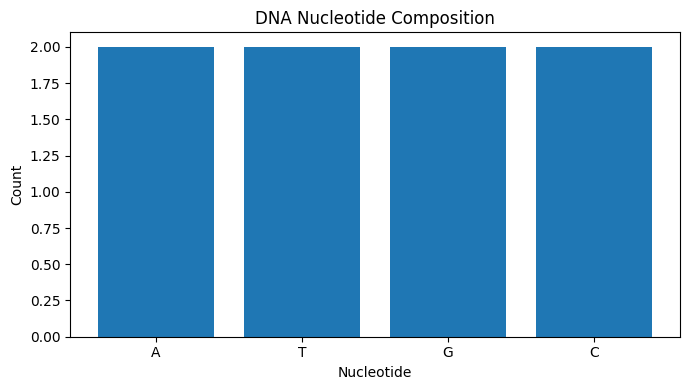

DNA COMPOSITION SUMMARY
-----------------------------------
A: 2 (25.00%)
T: 2 (25.00%)
G: 2 (25.00%)
C: 2 (25.00%)


In [ ]:
test_sequence = "ATGCGCTA"

composition_results = plot_dna_composition(test_sequence)

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

def gc_skew_analysis(sequence, window_size=10, step_size=1):
    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(result)

    sequence = result

    if not isinstance(window_size, int) or isinstance(window_size, bool) or window_size < 1:
        raise ValueError("window_size must be a positive integer.")

    if not isinstance(step_size, int) or isinstance(step_size, bool) or step_size < 1:
        raise ValueError("step_size must be a positive integer.")

    if window_size > len(sequence):
        raise ValueError("window_size cannot exceed sequence length.")

    rows = []

    for start in range(0, len(sequence) - window_size + 1, step_size):
        window = sequence[start:start + window_size]
        g_count = window.count("G")
        c_count = window.count("C")
        denominator = g_count + c_count

        skew = (
            (g_count - c_count) / denominator
            if denominator > 0
            else None
        )

        rows.append({
            "Start Position": start + 1,
            "End Position": start + window_size,
            "G Count": g_count,
            "C Count": c_count,
            "GC Skew": skew
        })

    results = pd.DataFrame(rows)

    print("GC SKEW ANALYSIS")
    print("-" * 40)
    display(results)

    plt.figure(figsize=(9, 4))
    plt.plot(
        results["Start Position"],
        results["GC Skew"],
        marker="o"
    )
    plt.axhline(0, linestyle="--")
    plt.title("GC Skew Across DNA Sequence")
    plt.xlabel("Window Start Position")
    plt.ylabel("(G - C) / (G + C)")
    plt.tight_layout()
    plt.show()

    return results


print("GC Skew Analysis function is ready!")

GC Skew Analysis function is ready!


GC SKEW ANALYSIS
----------------------------------------


,Start Position,End Position,G Count,C Count,GC Skew
0,1,4,1,1,0.0
1,3,6,2,2,0.0
2,5,8,1,1,0.0


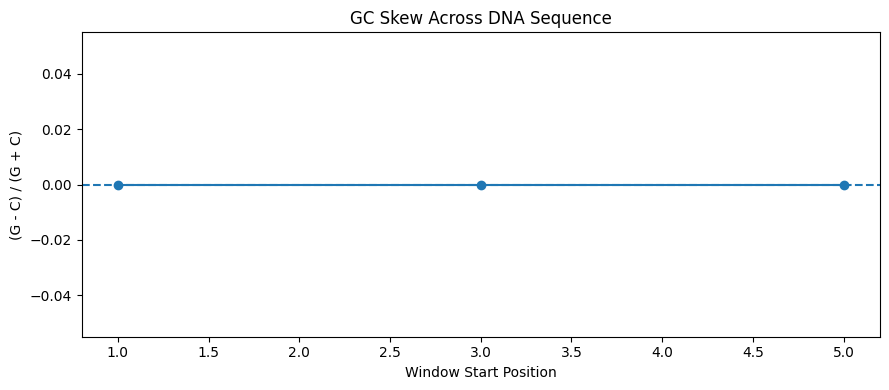

In [ ]:
test_sequence = "ATGCGCTA"

gc_skew_results = gc_skew_analysis(
    test_sequence,
    window_size=4,
    step_size=2
)

In [ ]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

def dna_pattern_frequency(sequence, pattern_length=2, top_n=10):
    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(result)

    sequence = result

    if not isinstance(pattern_length, int) or isinstance(pattern_length, bool) or pattern_length < 1:
        raise ValueError("pattern_length must be a positive integer.")

    if pattern_length > len(sequence):
        raise ValueError("pattern_length cannot exceed sequence length.")

    if not isinstance(top_n, int) or isinstance(top_n, bool) or top_n < 1:
        raise ValueError("top_n must be a positive integer.")

    # Count overlapping patterns
    patterns = [
        sequence[i:i + pattern_length]
        for i in range(len(sequence) - pattern_length + 1)
    ]

    counts = Counter(patterns)
    total = len(patterns)

    results = pd.DataFrame(
        [
            {
                "Pattern": pattern,
                "Count": count,
                "Frequency (%)": round(count / total * 100, 2)
            }
            for pattern, count in counts.most_common()
        ]
    )

    print("DNA PATTERN FREQUENCY ANALYSIS")
    print("-" * 45)
    print("Sequence length:", len(sequence))
    print("Pattern length:", pattern_length)
    print("Total overlapping patterns:", total)
    print("Distinct patterns found:", len(counts))

    display(results.head(top_n))

    # Plot the most frequent patterns
    plot_data = results.head(top_n)

    plt.figure(figsize=(10, 4))
    plt.bar(plot_data["Pattern"], plot_data["Count"])
    plt.title(f"Most Frequent DNA Patterns (Length {pattern_length})")
    plt.xlabel("DNA Pattern")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

    return results


print("DNA Pattern Frequency Analysis function is ready!")

DNA Pattern Frequency Analysis function is ready!


DNA PATTERN FREQUENCY ANALYSIS
---------------------------------------------
Sequence length: 8
Pattern length: 2
Total overlapping patterns: 7
Distinct patterns found: 6


,Pattern,Count,Frequency (%)
0,GC,2,28.57
1,AT,1,14.29
2,TG,1,14.29
3,CG,1,14.29
4,CT,1,14.29
5,TA,1,14.29


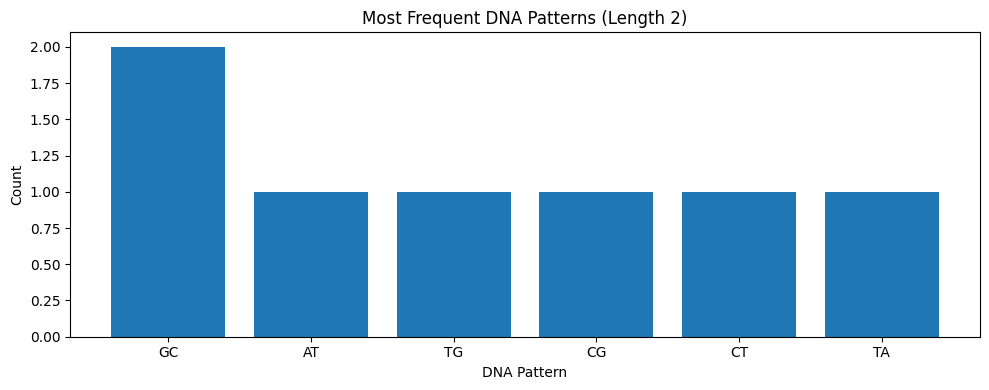

In [ ]:
test_sequence = "ATGCGCTA"

pattern_results = dna_pattern_frequency(
    test_sequence,
    pattern_length=2,
    top_n=10
)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def dna_similarity_heatmap(sequences, labels=None):
    if not sequences:
        raise ValueError("Please provide at least one DNA sequence.")

    cleaned_sequences = []

    for sequence in sequences:
        valid, result = validate_dna(sequence)

        if not valid:
            raise ValueError(result)

        cleaned_sequences.append(result)

    n = len(cleaned_sequences)

    if labels is None:
        labels = [f"Sequence {i + 1}" for i in range(n)]

    if len(labels) != n:
        raise ValueError("Number of labels must match number of sequences.")

    # Compare sequences position by position.
    # For unequal lengths, compare the shared prefix only.
    similarity = np.zeros((n, n))

    for i in range(n):
        for j in range(n):
            if i == j:
                similarity[i, j] = 100.0
            else:
                a = cleaned_sequences[i]
                b = cleaned_sequences[j]
                shared_length = min(len(a), len(b))

                if shared_length == 0:
                    similarity[i, j] = 0.0
                else:
                    matches = sum(
                        x == y for x, y in zip(a[:shared_length], b[:shared_length])
                    )
                    similarity[i, j] = matches / shared_length * 100

    similarity_df = pd.DataFrame(
        similarity,
        index=labels,
        columns=labels
    )

    print("DNA SEQUENCE SIMILARITY")
    print("-" * 40)
    print("Number of sequences:", n)
    display(similarity_df.round(2))

    plt.figure(figsize=(7, 5))
    plt.imshow(similarity, vmin=0, vmax=100, aspect="auto")
    plt.colorbar(label="Similarity (%)")
    plt.xticks(range(n), labels, rotation=45, ha="right")
    plt.yticks(range(n), labels)
    plt.title("DNA Sequence Similarity Heatmap")
    plt.tight_layout()
    plt.show()

    return similarity_df


print("DNA Similarity Heatmap function is ready!")

DNA Similarity Heatmap function is ready!


DNA SEQUENCE SIMILARITY
----------------------------------------
Number of sequences: 3


,Sequence A,Sequence B,Sequence C
Sequence A,100.0,87.5,25.0
Sequence B,87.5,100.0,12.5
Sequence C,25.0,12.5,100.0


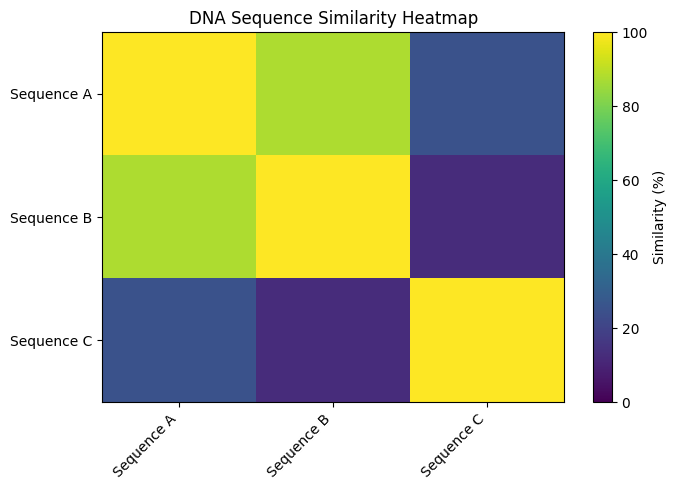

In [ ]:
test_sequences = [
    "ATGCGCTA",
    "ATGCACTA",
    "TTTTGGGG"
]

test_labels = [
    "Sequence A",
    "Sequence B",
    "Sequence C"
]

similarity_results = dna_similarity_heatmap(
    test_sequences,
    test_labels
)

In [ ]:
import pandas as pd

def dna_quality_report(sequence):
    if not isinstance(sequence, str):
        raise ValueError("DNA sequence must be a string.")

    cleaned = "".join(sequence.split()).upper()

    if not cleaned:
        raise ValueError("DNA sequence is empty.")

    allowed = set("ATGCN")
    invalid = sorted(set(cleaned) - allowed)

    if invalid:
        raise ValueError(
            f"Unsupported characters found: {', '.join(invalid)}"
        )

    length = len(cleaned)
    counts = {base: cleaned.count(base) for base in "ATGCN"}
    gc_count = counts["G"] + counts["C"]
    at_count = counts["A"] + counts["T"]
    ambiguous_count = counts["N"]

    gc_percent = gc_count / length * 100
    at_percent = at_count / length * 100
    ambiguous_percent = ambiguous_count / length * 100

    report = pd.DataFrame([
        {"Metric": "Sequence Length", "Value": length},
        {"Metric": "A Count", "Value": counts["A"]},
        {"Metric": "T Count", "Value": counts["T"]},
        {"Metric": "G Count", "Value": counts["G"]},
        {"Metric": "C Count", "Value": counts["C"]},
        {"Metric": "Ambiguous N Count", "Value": counts["N"]},
        {"Metric": "GC Content (%)", "Value": round(gc_percent, 2)},
        {"Metric": "AT Content (%)", "Value": round(at_percent, 2)},
        {
            "Metric": "Ambiguous Bases (%)",
            "Value": round(ambiguous_percent, 2)
        }
    ])

    print("DNA SEQUENCE QUALITY REPORT")
    print("=" * 40)
    print("Sequence accepted: Yes")
    print("Note: N represents an unknown or ambiguous nucleotide.")
    display(report)

    return report


print("DNA Quality Report function is ready!")

DNA Quality Report function is ready!


In [ ]:
test_sequence = "ATGCNNATGC"

quality_report = dna_quality_report(test_sequence)

DNA SEQUENCE QUALITY REPORT
Sequence accepted: Yes
Note: N represents an unknown or ambiguous nucleotide.


,Metric,Value
0,Sequence Length,10.0
1,A Count,2.0
2,T Count,2.0
3,G Count,2.0
4,C Count,2.0
5,Ambiguous N Count,2.0
6,GC Content (%),40.0
7,AT Content (%),40.0
8,Ambiguous Bases (%),20.0


In [ ]:
def transcribe_dna(sequence):
    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(result)

    dna = result
    rna = dna.replace("T", "U")

    print("DNA TO RNA TRANSCRIPTION")
    print("-" * 40)
    print("DNA Sequence:", dna)
    print("RNA Sequence:", rna)
    print("DNA Length:", len(dna))
    print("RNA Length:", len(rna))

    return rna


print("DNA Transcription function is ready!")

DNA Transcription function is ready!


In [ ]:
test_sequence = "ATGCGCTA"

rna_result = transcribe_dna(test_sequence)

DNA TO RNA TRANSCRIPTION
----------------------------------------
DNA Sequence: ATGCGCTA
RNA Sequence: AUGCGCUA
DNA Length: 8
RNA Length: 8


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

def analyze_rna(sequence):
    if not isinstance(sequence, str):
        raise ValueError("RNA sequence must be a string.")

    rna = "".join(sequence.split()).upper()

    if not rna:
        raise ValueError("RNA sequence cannot be empty.")

    invalid = sorted(set(rna) - set("AUGC"))

    if invalid:
        raise ValueError(
            f"Invalid RNA characters: {', '.join(invalid)}. "
            "Only A, U, G, and C are accepted."
        )

    length = len(rna)
    counts = {base: rna.count(base) for base in "AUGC"}

    gc_count = counts["G"] + counts["C"]
    gc_percent = (gc_count / length) * 100

    results = pd.DataFrame([
        {
            "Nucleotide": base,
            "Count": counts[base],
            "Percentage (%)": round(counts[base] / length * 100, 2)
        }
        for base in "AUGC"
    ])

    print("RNA SEQUENCE ANALYSIS")
    print("-" * 40)
    print("RNA Sequence:", rna)
    print("Sequence Length:", length)
    print("GC Content:", round(gc_percent, 2), "%")

    display(results)

    plt.figure(figsize=(7, 4))
    plt.bar(results["Nucleotide"], results["Count"])
    plt.title("RNA Nucleotide Composition")
    plt.xlabel("Nucleotide")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

    return results


print("RNA Analysis function is ready!")

RNA Analysis function is ready!


RNA SEQUENCE ANALYSIS
----------------------------------------
RNA Sequence: AUGCGCUA
Sequence Length: 8
GC Content: 50.0 %


,Nucleotide,Count,Percentage (%)
0,A,2,25.0
1,U,2,25.0
2,G,2,25.0
3,C,2,25.0


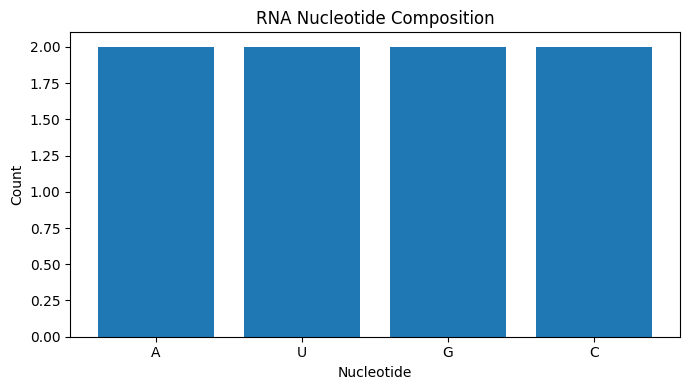

In [ ]:
test_rna = "AUGCGCUA"

rna_results = analyze_rna(test_rna)

In [ ]:
import pandas as pd

def analyze_rna_codons(sequence):
    if not isinstance(sequence, str):
        raise ValueError("RNA sequence must be a string.")

    rna = "".join(sequence.split()).upper()

    if not rna:
        raise ValueError("RNA sequence cannot be empty.")

    invalid = sorted(set(rna) - set("AUGC"))

    if invalid:
        raise ValueError(
            f"Invalid RNA characters: {', '.join(invalid)}. "
            "Only A, U, G, and C are accepted."
        )

    codons = [
        rna[i:i + 3]
        for i in range(0, len(rna) - 2, 3)
    ]

    leftover = rna[len(codons) * 3:]

    results = pd.DataFrame({
        "Position": [i * 3 + 1 for i in range(len(codons))],
        "Codon": codons
    })

    print("RNA CODON ANALYSIS")
    print("-" * 40)
    print("RNA Sequence:", rna)
    print("Total nucleotides:", len(rna))
    print("Complete codons:", len(codons))
    print("Unused nucleotides at end:", leftover if leftover else "None")

    if not results.empty:
        display(results)
    else:
        print("No complete codons found.")

    return results


print("RNA Codon Analysis function is ready!")

RNA Codon Analysis function is ready!


In [ ]:
test_rna = "AUGGCCUUUUGA"

codon_results = analyze_rna_codons(test_rna)

RNA CODON ANALYSIS
----------------------------------------
RNA Sequence: AUGGCCUUUUGA
Total nucleotides: 12
Complete codons: 4
Unused nucleotides at end: None


,Position,Codon
0,1,AUG
1,4,GCC
2,7,UUU
3,10,UGA


In [ ]:
from Bio.Seq import Seq

def translate_rna_to_protein(sequence):
    if not isinstance(sequence, str):
        raise ValueError("RNA sequence must be a string.")

    rna = "".join(sequence.split()).upper()

    if not rna:
        raise ValueError("RNA sequence cannot be empty.")

    invalid = sorted(set(rna) - set("AUGC"))

    if invalid:
        raise ValueError(
            f"Invalid RNA characters: {', '.join(invalid)}. "
            "Only A, U, G, and C are accepted."
        )

    # Translate only complete codons
    complete_length = (len(rna) // 3) * 3
    complete_rna = rna[:complete_length]
    leftover = rna[complete_length:]

    protein = str(Seq(complete_rna).translate(to_stop=False))

    print("RNA TO PROTEIN TRANSLATION")
    print("-" * 40)
    print("RNA Sequence:", rna)
    print("Protein Sequence:", protein)
    print("RNA Length:", len(rna))
    print("Complete Codons:", complete_length // 3)
    print("Unused trailing bases:", leftover if leftover else "None")

    return protein


print("RNA Translation function is ready!")

RNA Translation function is ready!


In [ ]:
test_rna = "AUGGCCUUUUGA"

protein_result = translate_rna_to_protein(test_rna)

RNA TO PROTEIN TRANSLATION
----------------------------------------
RNA Sequence: AUGGCCUUUUGA
Protein Sequence: MAF*
RNA Length: 12
Complete Codons: 4
Unused trailing bases: None


In [ ]:
from pathlib import Path
import pandas as pd

def export_dna_files(sequence, filename="dna_sequence", sequence_id="BioSeqAI_Sequence"):
    if not isinstance(sequence, str):
        raise ValueError("DNA sequence must be a string.")

    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(result)

    sequence = result

    # Make a safe filename
    safe_name = "".join(
        ch if ch.isalnum() or ch in "_-" else "_"
        for ch in filename
    ).strip("_")

    if not safe_name:
        safe_name = "dna_sequence"

    safe_id = "".join(
        ch if ch.isalnum() or ch in "_.-" else "_"
        for ch in sequence_id
    )

    # Save FASTA file
    fasta_path = Path(f"{safe_name}.fasta")
    with open(fasta_path, "w", encoding="utf-8") as file:
        file.write(f">{safe_id}\n")
        for i in range(0, len(sequence), 60):
            file.write(sequence[i:i + 60] + "\n")

    # Save nucleotide composition CSV
    counts = {base: sequence.count(base) for base in "ATGC"}
    length = len(sequence)

    composition_df = pd.DataFrame([
        {
            "Nucleotide": base,
            "Count": counts[base],
            "Percentage": round(counts[base] / length * 100, 2)
        }
        for base in "ATGC"
    ])

    csv_path = Path(f"{safe_name}_composition.csv")
    composition_df.to_csv(csv_path, index=False)

    print("DNA EXPORT COMPLETED")
    print("-" * 40)
    print("FASTA file:", fasta_path.resolve())
    print("CSV file:", csv_path.resolve())
    print("Sequence length:", length)

    return str(fasta_path), str(csv_path)


print("DNA Export function is ready!")

DNA Export function is ready!


In [ ]:
test_sequence = "ATGCGCTA"

fasta_file, csv_file = export_dna_files(
    test_sequence,
    filename="my_dna",
    sequence_id="Test_Sequence"
)

DNA EXPORT COMPLETED
----------------------------------------
FASTA file: /content/my_dna.fasta
CSV file: /content/my_dna_composition.csv
Sequence length: 8


In [ ]:
from google.colab import files

files.download(fasta_file)
files.download(csv_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
from google.colab import files

def read_fasta_file(file_path):
    """
    Read a FASTA file and extract its DNA sequence.
    Supports one DNA sequence per FASTA file.
    """

    file_path = Path(file_path)

    if not file_path.exists():
        raise FileNotFoundError(f"File not found: {file_path}")

    sequence_parts = []
    sequence_id = None

    with open(file_path, "r", encoding="utf-8") as file:
        for line in file:
            line = line.strip()

            if not line:
                continue

            if line.startswith(">"):
                if sequence_id is not None:
                    raise ValueError(
                        "Multiple FASTA records found. "
                        "Please upload a file containing one sequence."
                    )

                sequence_id = line[1:].strip()

                if not sequence_id:
                    raise ValueError("FASTA header is empty.")

            else:
                if sequence_id is None:
                    raise ValueError(
                        "Invalid FASTA format: header must start with >."
                    )

                sequence_parts.append(line)

    if sequence_id is None:
        raise ValueError("No FASTA header found.")

    sequence = "".join(sequence_parts).upper()

    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(f"Invalid DNA sequence: {result}")

    print("✅ FASTA FILE IMPORTED SUCCESSFULLY")
    print("-" * 40)
    print("Sequence ID:", sequence_id)
    print("Sequence length:", len(result), "bp")
    print("DNA sequence:", result)

    return sequence_id, result


print("FASTA import function is ready!")

FASTA import function is ready!


In [ ]:
from pathlib import Path

test_fasta = Path("test_sequence.fasta")

test_fasta.write_text(
    ">Test_DNA_Sequence\n"
    "ATGCGCTA\n"
    "GCTAGCTA\n",
    encoding="utf-8"
)

sequence_id, imported_sequence = read_fasta_file(test_fasta)

print("\nTest result:", imported_sequence == "ATGCGCTAGCTAGCTA")

✅ FASTA FILE IMPORTED SUCCESSFULLY
----------------------------------------
Sequence ID: Test_DNA_Sequence
Sequence length: 16 bp
DNA sequence: ATGCGCTAGCTAGCTA

Test result: True


In [ ]:
uploaded = files.upload()

for filename in uploaded:
    sequence_id, imported_sequence = read_fasta_file(filename)

Saving my_dna.fasta to my_dna (1).fasta
✅ FASTA FILE IMPORTED SUCCESSFULLY
----------------------------------------
Sequence ID: Test_Sequence
Sequence length: 8 bp
DNA sequence: ATGCGCTA


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

def compare_gc_content(sequences):
    """
    Compare GC content across multiple DNA sequences.

    Input format:
    {
        "Sequence 1": "ATGC",
        "Sequence 2": "GGCC"
    }
    """

    if not isinstance(sequences, dict) or len(sequences) == 0:
        raise ValueError("Please provide a non-empty dictionary of sequences.")

    results = []

    for name, sequence in sequences.items():

        if not isinstance(sequence, str):
            raise ValueError(f"{name}: sequence must be a string.")

        valid, cleaned_sequence = validate_dna(sequence)

        if not valid:
            raise ValueError(f"{name}: {cleaned_sequence}")

        length = len(cleaned_sequence)
        gc_count = cleaned_sequence.count("G") + cleaned_sequence.count("C")
        gc_percent = (gc_count / length) * 100

        results.append({
            "Sequence Name": name,
            "Length (bp)": length,
            "GC Count": gc_count,
            "GC Content (%)": round(gc_percent, 2)
        })

    results_df = pd.DataFrame(results)

    display(results_df)

    plt.figure(figsize=(9, 5))
    plt.bar(
        results_df["Sequence Name"],
        results_df["GC Content (%)"]
    )
    plt.xlabel("DNA Sequences")
    plt.ylabel("GC Content (%)")
    plt.title("DNA GC Content Comparison")
    plt.ylim(0, 100)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

    return results_df


print("GC comparison function is ready!")

GC comparison function is ready!


,Sequence Name,Length (bp),GC Count,GC Content (%)
0,Sequence A,8,4,50.0
1,Sequence B,8,8,100.0
2,Sequence C,8,0,0.0
3,Sequence D,8,8,100.0


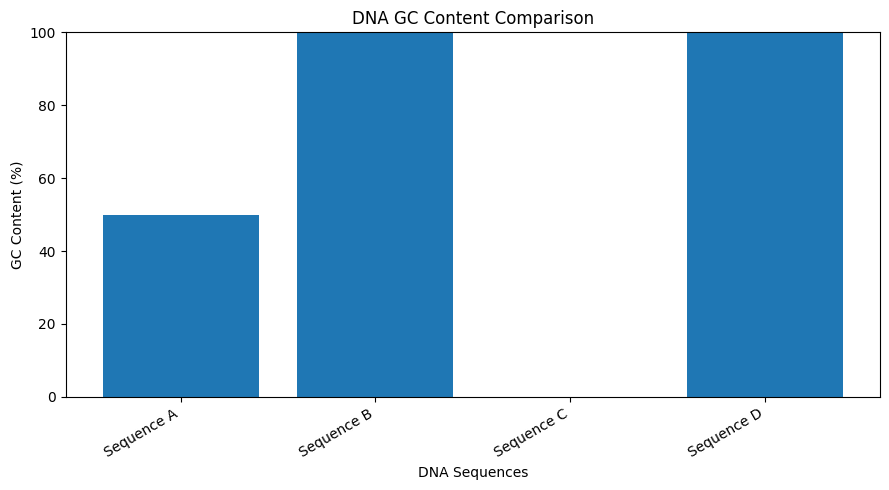

In [ ]:
sample_sequences = {
    "Sequence A": "ATGCATGC",
    "Sequence B": "GGCCGGCC",
    "Sequence C": "ATATATAT",
    "Sequence D": "GCGCGCGC"
}

gc_comparison = compare_gc_content(sample_sequences)

In [ ]:
import pandas as pd
from Bio.Align import PairwiseAligner

def detect_dna_mutations(reference, query):
    """
    Compare reference and query DNA sequences.
    Reports differences in one global alignment.

    This is an educational comparison, not a clinical variant caller.
    """

    valid_ref, reference = validate_dna(reference)
    valid_query, query = validate_dna(query)

    if not valid_ref:
        raise ValueError(f"Invalid reference DNA: {reference}")

    if not valid_query:
        raise ValueError(f"Invalid query DNA: {query}")

    if not reference or not query:
        raise ValueError("Both DNA sequences must be non-empty.")

    aligner = PairwiseAligner()
    aligner.mode = "global"
    aligner.match_score = 2
    aligner.mismatch_score = -1
    aligner.open_gap_score = -3
    aligner.extend_gap_score = -0.5

    alignment = aligner.align(reference, query)[0]

    ref_aligned, query_aligned = str(alignment).split("\n")[::2]

    # Remove alignment labels/coordinates if Biopython displays them.
    # Build aligned strings directly from the alignment coordinates.
    ref_parts = []
    query_parts = []

    for (ref_start, ref_end), (query_start, query_end) in zip(
        alignment.aligned[0], alignment.aligned[1]
    ):
        pass

    # Construct aligned sequences using the alignment's coordinate blocks.
    coordinates = alignment.coordinates
    for i in range(coordinates.shape[1] - 1):
        r1, r2 = coordinates[0, i], coordinates[0, i + 1]
        q1, q2 = coordinates[1, i], coordinates[1, i + 1]

        r_len = r2 - r1
        q_len = q2 - q1

        if r_len and q_len:
            ref_parts.append(reference[r1:r2])
            query_parts.append(query[q1:q2])
        elif r_len:
            ref_parts.append(reference[r1:r2])
            query_parts.append("-" * r_len)
        elif q_len:
            ref_parts.append("-" * q_len)
            query_parts.append(query[q1:q2])

    ref_aligned = "".join(ref_parts)
    query_aligned = "".join(query_parts)

    mutations = []
    ref_position = 0
    query_position = 0

    i = 0
    while i < len(ref_aligned):
        r = ref_aligned[i]
        q = query_aligned[i]

        if r == q:
            if r != "-":
                ref_position += 1
                query_position += 1
            i += 1
            continue

        if r != "-" and q != "-":
            mutations.append({
                "Type": "Substitution",
                "Reference Position": ref_position + 1,
                "Query Position": query_position + 1,
                "Reference Base": r,
                "Query Base": q,
                "Change": f"{r}>{q}"
            })
            ref_position += 1
            query_position += 1
            i += 1

        elif r == "-":
            inserted = []
            start_query = query_position + 1

            while i < len(ref_aligned) and ref_aligned[i] == "-":
                inserted.append(query_aligned[i])
                query_position += 1
                i += 1

            mutations.append({
                "Type": "Insertion",
                "Reference Position": ref_position,
                "Query Position": start_query,
                "Reference Base": "-",
                "Query Base": "".join(inserted),
                "Change": f"insert {''.join(inserted)}"
            })

        else:
            deleted = []
            start_ref = ref_position + 1

            while i < len(ref_aligned) and query_aligned[i] == "-":
                deleted.append(ref_aligned[i])
                ref_position += 1
                i += 1

            mutations.append({
                "Type": "Deletion",
                "Reference Position": start_ref,
                "Query Position": query_position,
                "Reference Base": "".join(deleted),
                "Query Base": "-",
                "Change": f"delete {''.join(deleted)}"
            })

    print("DNA MUTATION COMPARISON")
    print("-" * 40)
    print("Reference length:", len(reference), "bp")
    print("Query length:", len(query), "bp")
    print("Alignment score:", alignment.score)
    print("\nAligned reference:", ref_aligned)
    print("Aligned query:   ", query_aligned)

    if mutations:
        mutation_df = pd.DataFrame(mutations)
        print("\nDifferences found:", len(mutations))
        display(mutation_df)
    else:
        mutation_df = pd.DataFrame(columns=[
            "Type", "Reference Position", "Query Position",
            "Reference Base", "Query Base", "Change"
        ])
        print("\nNo differences found in the selected alignment.")

    return mutation_df


print("DNA mutation detection function is ready!")

DNA mutation detection function is ready!


In [ ]:
reference_dna = "ATGCGCTA"
query_dna = "ATGCACTA"

mutation_results = detect_dna_mutations(
    reference_dna,
    query_dna
)

DNA MUTATION COMPARISON
----------------------------------------
Reference length: 8 bp
Query length: 8 bp
Alignment score: 13.0

Aligned reference: ATGCGCTA
Aligned query:    ATGCACTA

Differences found: 1


,Type,Reference Position,Query Position,Reference Base,Query Base,Change
0,Substitution,5,5,G,A,G>A


In [ ]:
print("TEST 2: INSERTION")
detect_dna_mutations("ATGCGCTA", "ATGACGCTA")

print("\nTEST 3: DELETION")
detect_dna_mutations("ATGACGCTA", "ATGCGCTA")

TEST 2: INSERTION
DNA MUTATION COMPARISON
----------------------------------------
Reference length: 8 bp
Query length: 9 bp
Alignment score: 13.0

Aligned reference: ATG-CGCTA
Aligned query:    ATGACGCTA

Differences found: 1


,Type,Reference Position,Query Position,Reference Base,Query Base,Change
0,Insertion,3,4,-,A,insert A



TEST 3: DELETION
DNA MUTATION COMPARISON
----------------------------------------
Reference length: 9 bp
Query length: 8 bp
Alignment score: 13.0

Aligned reference: ATGACGCTA
Aligned query:    ATG-CGCTA

Differences found: 1


,Type,Reference Position,Query Position,Reference Base,Query Base,Change
0,Deletion,4,3,A,-,delete A


,Type,Reference Position,Query Position,Reference Base,Query Base,Change
0,Deletion,4,3,A,-,delete A


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import math

def dna_statistics_dashboard(sequence):
    """
    Display a combined DNA statistics dashboard.
    Educational analysis only.
    """

    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(result)

    sequence = result
    length = len(sequence)

    if length == 0:
        raise ValueError("DNA sequence cannot be empty.")

    counts = {
        base: sequence.count(base)
        for base in "ATGC"
    }

    percentages = {
        base: round(counts[base] / length * 100, 2)
        for base in "ATGC"
    }

    gc_count = counts["G"] + counts["C"]
    at_count = counts["A"] + counts["T"]

    gc_content = gc_count / length * 100
    at_content = at_count / length * 100

    gc_at_ratio = (
        round(gc_count / at_count, 3)
        if at_count > 0 else None
    )

    entropy = -sum(
        (count / length) * math.log2(count / length)
        for count in counts.values()
        if count > 0
    )

    print("=" * 45)
    print("       BIOSEQ AI DNA STATISTICS")
    print("=" * 45)

    print(f"Sequence Length : {length} bp")
    print(f"GC Content      : {gc_content:.2f}%")
    print(f"AT Content      : {at_content:.2f}%")
    print(f"GC/AT Ratio     : {gc_at_ratio}")
    print(f"Shannon Entropy : {entropy:.3f} bits")
    print("-" * 45)

    composition_df = pd.DataFrame({
        "Nucleotide": list("ATGC"),
        "Count": [counts[b] for b in "ATGC"],
        "Percentage": [percentages[b] for b in "ATGC"]
    })

    display(composition_df)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].bar(
        composition_df["Nucleotide"],
        composition_df["Count"]
    )
    axes[0].set_title("Nucleotide Counts")
    axes[0].set_xlabel("Nucleotide")
    axes[0].set_ylabel("Count")

    axes[1].pie(
        composition_df["Count"],
        labels=composition_df["Nucleotide"],
        autopct="%1.1f%%"
    )
    axes[1].set_title("Nucleotide Composition")

    plt.tight_layout()
    plt.show()

    return {
        "length": length,
        "counts": counts,
        "gc_content": round(gc_content, 2),
        "at_content": round(at_content, 2),
        "gc_at_ratio": gc_at_ratio,
        "shannon_entropy": round(entropy, 3),
        "composition_table": composition_df
    }


print("DNA Statistics Dashboard is ready!")

DNA Statistics Dashboard is ready!


       BIOSEQ AI DNA STATISTICS
Sequence Length : 12 bp
GC Content      : 50.00%
AT Content      : 50.00%
GC/AT Ratio     : 1.0
Shannon Entropy : 2.000 bits
---------------------------------------------


,Nucleotide,Count,Percentage
0,A,3,25.0
1,T,3,25.0
2,G,3,25.0
3,C,3,25.0


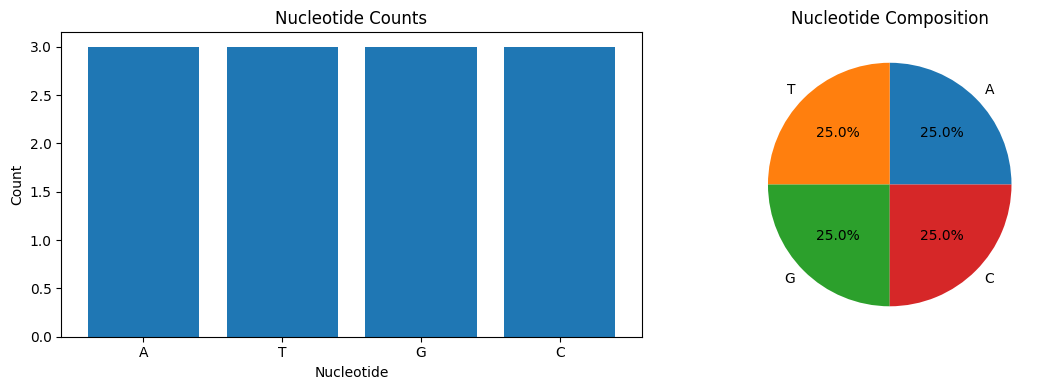

In [ ]:
sample_dna = "ATGCGCTAATGC"

dashboard_results = dna_statistics_dashboard(sample_dna)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

def dna_motif_dashboard(sequence, motifs):
    """
    Search multiple DNA motifs and visualize their occurrence.

    Positions are 1-based.
    Overlapping matches are included.
    """

    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(f"Invalid DNA sequence: {result}")

    sequence = result

    if not sequence:
        raise ValueError("DNA sequence cannot be empty.")

    if isinstance(motifs, str):
        motifs = [motifs]

    if not motifs:
        raise ValueError("Please provide at least one motif.")

    rows = []

    for motif in motifs:
        if not isinstance(motif, str):
            raise ValueError("Every motif must be a DNA string.")

        motif = motif.strip().upper()

        if not motif:
            raise ValueError("Motifs cannot be empty.")

        if any(base not in "ATGC" for base in motif):
            raise ValueError(
                f"Invalid motif '{motif}'. Use only A, T, G and C."
            )

        positions = []
        start = 0

        while True:
            index = sequence.find(motif, start)

            if index == -1:
                break

            positions.append(index + 1)
            start = index + 1

        rows.append({
            "Motif": motif,
            "Motif Length": len(motif),
            "Occurrences": len(positions),
            "Positions (1-based)": positions
        })

    results_df = pd.DataFrame(rows)

    print("DNA MOTIF ANALYSIS")
    print("=" * 45)
    print("Sequence length:", len(sequence), "bp")

    display(results_df)

    plt.figure(figsize=(9, 5))
    plt.bar(
        results_df["Motif"],
        results_df["Occurrences"]
    )
    plt.xlabel("DNA Motif")
    plt.ylabel("Number of Occurrences")
    plt.title("DNA Motif Frequency Comparison")
    plt.tight_layout()
    plt.show()

    return results_df


print("DNA Motif Dashboard is ready!")

DNA Motif Dashboard is ready!


DNA MOTIF ANALYSIS
Sequence length: 16 bp


,Motif,Motif Length,Occurrences,Positions (1-based)
0,ATG,3,2,"[1, 9]"
1,CGC,3,2,"[4, 12]"
2,CTA,3,2,"[6, 14]"
3,TTT,3,0,[]


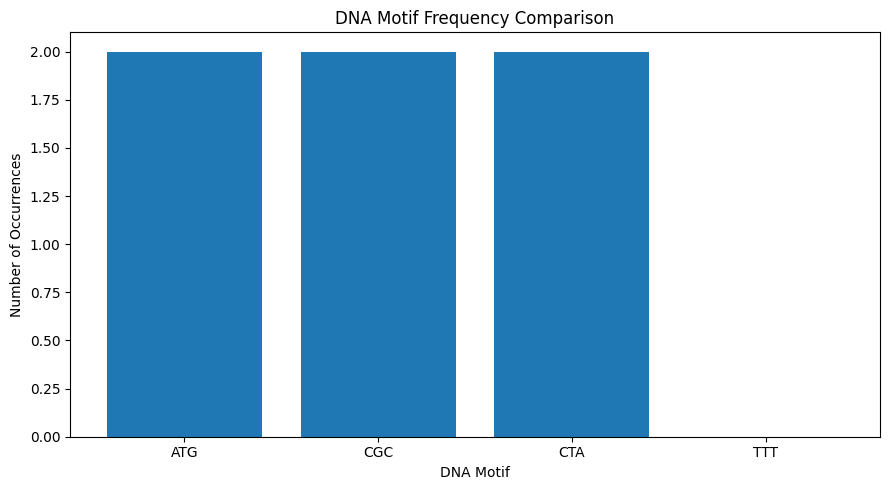

In [ ]:
sample_dna = "ATGCGCTAATGCGCTA"

motif_results = dna_motif_dashboard(
    sample_dna,
    ["ATG", "CGC", "CTA", "TTT"]
)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

def reverse_complement_dashboard(sequence):
    """
    Display DNA sequence, complement and reverse complement.
    """

    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(result)

    sequence = result

    if not sequence:
        raise ValueError("DNA sequence cannot be empty.")

    complement_map = str.maketrans({
        "A": "T",
        "T": "A",
        "G": "C",
        "C": "G"
    })

    complement = sequence.translate(complement_map)
    reverse_complement = complement[::-1]

    print("=" * 45)
    print("   DNA REVERSE COMPLEMENT DASHBOARD")
    print("=" * 45)

    print("Original DNA       :", sequence)
    print("Complement         :", complement)
    print("Reverse Complement :", reverse_complement)
    print("Sequence Length    :", len(sequence), "bp")

    results_df = pd.DataFrame({
        "Position": range(1, len(sequence) + 1),
        "Original Base": list(sequence),
        "Complement Base": list(complement),
        "Reverse Complement Base": list(reverse_complement[::-1])
    })

    display(results_df)

    counts = [sequence.count(base) for base in "ATGC"]

    plt.figure(figsize=(7, 4))
    plt.bar(list("ATGC"), counts)
    plt.xlabel("Nucleotide")
    plt.ylabel("Count")
    plt.title("Original DNA Nucleotide Composition")
    plt.tight_layout()
    plt.show()

    return {
        "original": sequence,
        "complement": complement,
        "reverse_complement": reverse_complement,
        "table": results_df
    }


print("Reverse Complement Dashboard is ready!")

Reverse Complement Dashboard is ready!


   DNA REVERSE COMPLEMENT DASHBOARD
Original DNA       : ATGC
Complement         : TACG
Reverse Complement : GCAT
Sequence Length    : 4 bp


,Position,Original Base,Complement Base,Reverse Complement Base
0,1,A,T,T
1,2,T,A,A
2,3,G,C,C
3,4,C,G,G


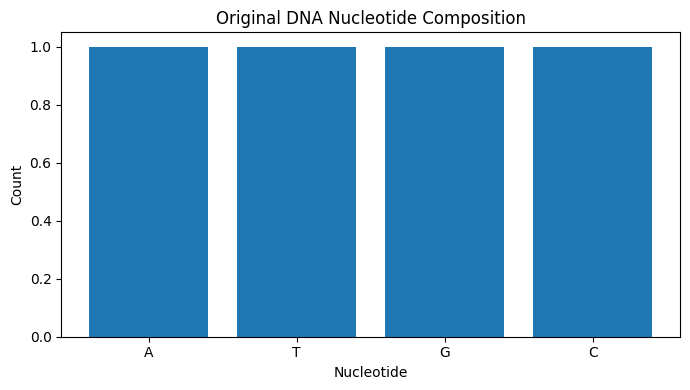


Verification:
Expected reverse complement: GCAT
Actual reverse complement: GCAT
✅ Reverse complement test passed!


In [ ]:
test_dna = "ATGC"

rc_results = reverse_complement_dashboard(test_dna)

print("\nVerification:")
print("Expected reverse complement: GCAT")
print("Actual reverse complement:", rc_results["reverse_complement"])

assert rc_results["reverse_complement"] == "GCAT"

print("✅ Reverse complement test passed!")

In [ ]:
import matplotlib.pyplot as plt
from Bio.Align import PairwiseAligner

def visualize_dna_alignment(reference, query):
    """
    Globally align two DNA sequences and visualize matches
    and mismatches in the selected alignment.
    """

    valid_ref, ref_result = validate_dna(reference)
    valid_query, query_result = validate_dna(query)

    if not valid_ref:
        raise ValueError(f"Invalid reference DNA: {ref_result}")

    if not valid_query:
        raise ValueError(f"Invalid query DNA: {query_result}")

    reference = ref_result
    query = query_result

    if not reference or not query:
        raise ValueError("Both sequences must be non-empty.")

    aligner = PairwiseAligner()
    aligner.mode = "global"
    aligner.match_score = 2
    aligner.mismatch_score = -1
    aligner.open_gap_score = -3
    aligner.extend_gap_score = -0.5

    alignment = aligner.align(reference, query)[0]
    coordinates = alignment.coordinates

    ref_aligned = []
    query_aligned = []

    for i in range(coordinates.shape[1] - 1):
        r1, r2 = coordinates[0, i], coordinates[0, i + 1]
        q1, q2 = coordinates[1, i], coordinates[1, i + 1]

        r_len = r2 - r1
        q_len = q2 - q1

        if r_len and q_len:
            ref_aligned.append(reference[r1:r2])
            query_aligned.append(query[q1:q2])

        elif r_len:
            ref_aligned.append(reference[r1:r2])
            query_aligned.append("-" * r_len)

        elif q_len:
            ref_aligned.append("-" * q_len)
            query_aligned.append(query[q1:q2])

    ref_aligned = "".join(ref_aligned)
    query_aligned = "".join(query_aligned)

    matches = [
        a == b and a != "-"
        for a, b in zip(ref_aligned, query_aligned)
    ]

    comparable = [
        a != "-" and b != "-"
        for a, b in zip(ref_aligned, query_aligned)
    ]

    match_count = sum(matches)
    comparable_count = sum(comparable)

    identity = (
        match_count / comparable_count * 100
        if comparable_count else 0
    )

    print("=" * 50)
    print("       DNA ALIGNMENT VISUALIZATION")
    print("=" * 50)
    print("Reference:", ref_aligned)
    print("           " + "".join(
        "|" if match else " "
        for match in matches
    ))
    print("Query:    ", query_aligned)
    print(f"\nAlignment score: {alignment.score}")
    print(f"Matching positions: {match_count}")
    print(f"Comparable positions: {comparable_count}")
    print(f"Identity among base-to-base positions: {identity:.2f}%")

    # Plot match/mismatch information across alignment columns.
    plt.figure(figsize=(12, 2.5))
    values = [
        1 if match else 0
        for match in matches
    ]

    plt.imshow(
        [values],
        aspect="auto",
        interpolation="nearest"
    )

    plt.yticks([0], ["Alignment"])
    plt.xlabel("Alignment column")
    plt.title("DNA Alignment: Matching vs Non-matching Columns")
    plt.tight_layout()
    plt.show()

    return {
        "alignment": alignment,
        "reference_aligned": ref_aligned,
        "query_aligned": query_aligned,
        "identity_percent": round(identity, 2)
    }


print("DNA Alignment Visualization is ready!")

DNA Alignment Visualization is ready!


       DNA ALIGNMENT VISUALIZATION
Reference: ATGCGCTA
           |||| |||
Query:     ATGCACTA

Alignment score: 13.0
Matching positions: 7
Comparable positions: 8
Identity among base-to-base positions: 87.50%


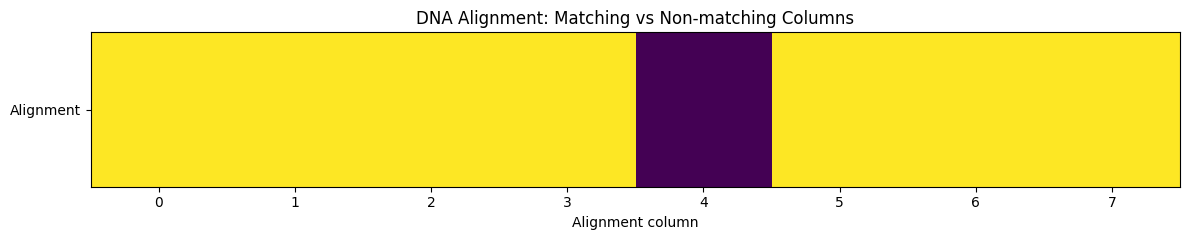


Verification:
Identity: 87.5 %


In [ ]:
reference_dna = "ATGCGCTA"
query_dna = "ATGCACTA"

alignment_results = visualize_dna_alignment(
    reference_dna,
    query_dna
)

print("\nVerification:")
print(
    "Identity:",
    alignment_results["identity_percent"],
    "%"
)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

def gc_region_analysis(sequence, window_size=10, step_size=5):
    """
    Analyze GC content across sliding windows of a DNA sequence.
    Positions are 1-based and inclusive.
    """

    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(f"Invalid DNA sequence: {result}")

    sequence = result

    if not sequence:
        raise ValueError("DNA sequence cannot be empty.")

    if not isinstance(window_size, int) or window_size <= 0:
        raise ValueError("window_size must be a positive integer.")

    if not isinstance(step_size, int) or step_size <= 0:
        raise ValueError("step_size must be a positive integer.")

    if window_size > len(sequence):
        raise ValueError(
            f"window_size ({window_size}) exceeds sequence length "
            f"({len(sequence)})."
        )

    rows = []

    for start in range(0, len(sequence) - window_size + 1, step_size):
        window = sequence[start:start + window_size]

        gc_count = window.count("G") + window.count("C")
        gc_percent = gc_count / len(window) * 100

        rows.append({
            "Start Position": start + 1,
            "End Position": start + window_size,
            "Window Sequence": window,
            "GC Count": gc_count,
            "GC Content (%)": round(gc_percent, 2)
        })

    results_df = pd.DataFrame(rows)

    print("=" * 50)
    print("       DNA GC REGION ANALYSIS")
    print("=" * 50)
    print("Sequence length:", len(sequence), "bp")
    print("Window size:", window_size, "bp")
    print("Step size:", step_size, "bp")

    display(results_df)

    highest = results_df.loc[results_df["GC Content (%)"].idxmax()]
    lowest = results_df.loc[results_df["GC Content (%)"].idxmin()]

    print("\nHighest GC region:")
    print(
        f"Positions {int(highest['Start Position'])}-"
        f"{int(highest['End Position'])}: "
        f"{highest['GC Content (%)']}%"
    )

    print("\nLowest GC region:")
    print(
        f"Positions {int(lowest['Start Position'])}-"
        f"{int(lowest['End Position'])}: "
        f"{lowest['GC Content (%)']}%"
    )

    plt.figure(figsize=(10, 5))
    plt.plot(
        results_df["Start Position"],
        results_df["GC Content (%)"],
        marker="o"
    )

    plt.xlabel("Window Start Position (bp)")
    plt.ylabel("GC Content (%)")
    plt.title("GC Content Across DNA Regions")
    plt.ylim(0, 100)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return results_df


print("GC Region Analysis function is ready!")

GC Region Analysis function is ready!


       DNA GC REGION ANALYSIS
Sequence length: 20 bp
Window size: 5 bp
Step size: 2 bp


,Start Position,End Position,Window Sequence,GC Count,GC Content (%)
0,1,5,ATATG,1,20.0
1,3,7,ATGCG,3,60.0
2,5,9,GCGCG,5,100.0
3,7,11,GCGCG,5,100.0
4,9,13,GCGCG,5,100.0
5,11,15,GCGCG,5,100.0
6,13,17,GCGCA,4,80.0
7,15,19,GCATA,2,40.0



Highest GC region:
Positions 5-9: 100.0%

Lowest GC region:
Positions 1-5: 20.0%


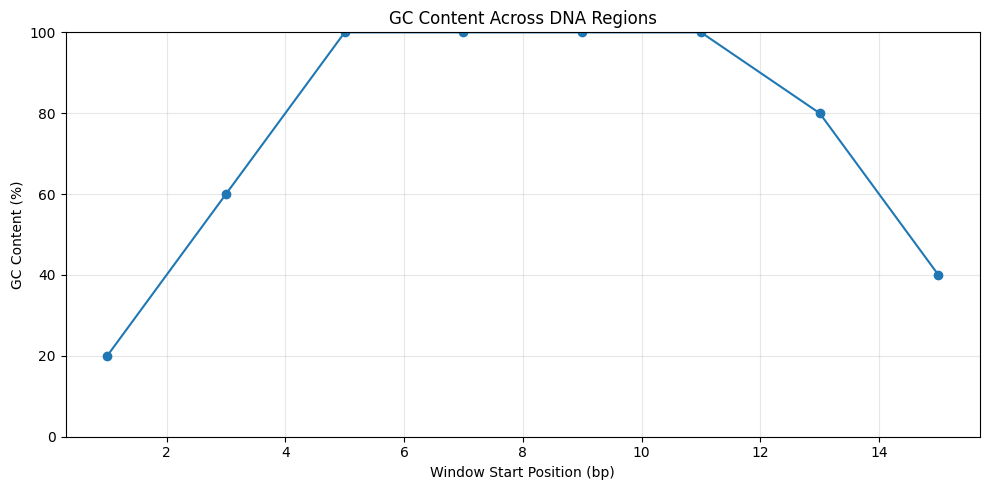

In [ ]:
sample_dna = "ATATGCGCGCGCGCGCATAT"

gc_regions = gc_region_analysis(
    sample_dna,
    window_size=5,
    step_size=2
)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

def gc_at_region_analysis(sequence, window_size=10, step_size=5):
    """
    Compare GC and AT content across sliding DNA windows.
    Positions are 1-based and inclusive.
    """

    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(f"Invalid DNA sequence: {result}")

    sequence = result

    if not sequence:
        raise ValueError("DNA sequence cannot be empty.")

    if not isinstance(window_size, int) or window_size <= 0:
        raise ValueError("window_size must be a positive integer.")

    if not isinstance(step_size, int) or step_size <= 0:
        raise ValueError("step_size must be a positive integer.")

    if window_size > len(sequence):
        raise ValueError("Window size cannot exceed sequence length.")

    rows = []

    for start in range(0, len(sequence) - window_size + 1, step_size):
        window = sequence[start:start + window_size]

        gc_count = window.count("G") + window.count("C")
        at_count = window.count("A") + window.count("T")

        rows.append({
            "Start Position": start + 1,
            "End Position": start + window_size,
            "GC Content (%)": round(gc_count / len(window) * 100, 2),
            "AT Content (%)": round(at_count / len(window) * 100, 2)
        })

    results_df = pd.DataFrame(rows)

    print("=" * 45)
    print("       GC vs AT REGION ANALYSIS")
    print("=" * 45)

    display(results_df)

    plt.figure(figsize=(10, 5))

    plt.plot(
        results_df["Start Position"],
        results_df["GC Content (%)"],
        marker="o",
        label="GC Content"
    )

    plt.plot(
        results_df["Start Position"],
        results_df["AT Content (%)"],
        marker="s",
        label="AT Content"
    )

    plt.xlabel("Window Start Position (bp)")
    plt.ylabel("Content (%)")
    plt.title("GC vs AT Content Across DNA Regions")
    plt.ylim(0, 100)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return results_df


print("GC vs AT Analysis function is ready!")

GC vs AT Analysis function is ready!


       GC vs AT REGION ANALYSIS


,Start Position,End Position,GC Content (%),AT Content (%)
0,1,5,20.0,80.0
1,3,7,60.0,40.0
2,5,9,100.0,0.0
3,7,11,100.0,0.0
4,9,13,100.0,0.0
5,11,15,100.0,0.0
6,13,17,80.0,20.0
7,15,19,40.0,60.0


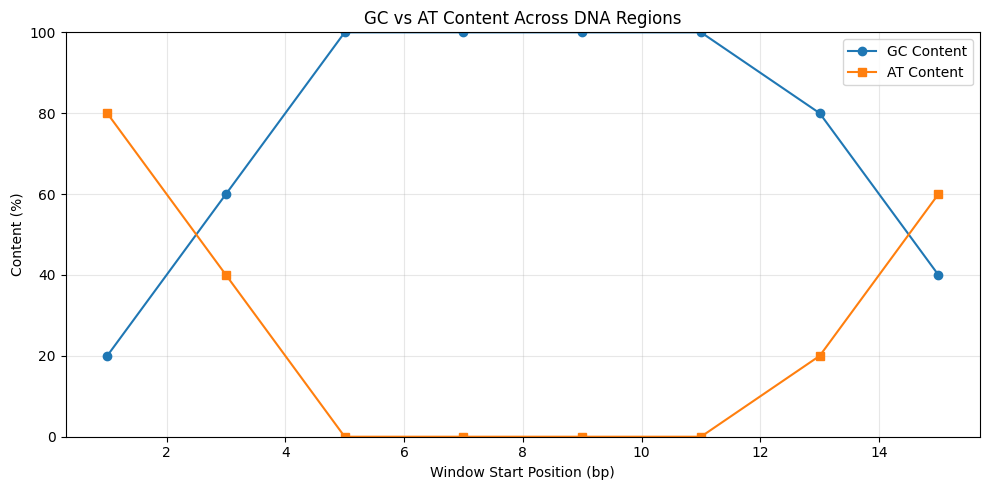

In [ ]:
sample_dna = "ATATGCGCGCGCGCGCATAT"

gc_at_results = gc_at_region_analysis(
    sample_dna,
    window_size=5,
    step_size=2
)

In [ ]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

def kmer_analysis_dashboard(sequence, k=3, top_n=15):
    """
    Analyze overlapping k-mers in a DNA sequence.

    k: length of each nucleotide pattern
    top_n: number of most frequent patterns to display
    """

    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(f"Invalid DNA sequence: {result}")

    sequence = result

    if not sequence:
        raise ValueError("DNA sequence cannot be empty.")

    if not isinstance(k, int) or isinstance(k, bool) or k < 1:
        raise ValueError("k must be a positive integer.")

    if k > len(sequence):
        raise ValueError("k cannot exceed sequence length.")

    if not isinstance(top_n, int) or isinstance(top_n, bool) or top_n < 1:
        raise ValueError("top_n must be a positive integer.")

    kmers = [
        sequence[i:i + k]
        for i in range(len(sequence) - k + 1)
    ]

    counts = Counter(kmers)
    total = len(kmers)

    results_df = pd.DataFrame(
        [
            {
                "K-mer": kmer,
                "Count": count,
                "Frequency (%)": round(count / total * 100, 2)
            }
            for kmer, count in counts.most_common()
        ]
    )

    print("=" * 45)
    print("       DNA K-MER ANALYSIS")
    print("=" * 45)
    print("Sequence length:", len(sequence), "bp")
    print("K-mer size:", k)
    print("Total overlapping k-mers:", total)
    print("Distinct k-mers:", len(counts))

    print("\nMost frequent k-mers:")
    display(results_df.head(top_n))

    plot_df = results_df.head(top_n)

    plt.figure(figsize=(11, 5))
    plt.bar(plot_df["K-mer"], plot_df["Count"])
    plt.xlabel(f"{k}-mer pattern")
    plt.ylabel("Frequency")
    plt.title(f"Top {min(top_n, len(plot_df))} DNA {k}-mers")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return results_df


print("K-mer Analysis Dashboard is ready!")

K-mer Analysis Dashboard is ready!


       DNA K-MER ANALYSIS
Sequence length: 10 bp
K-mer size: 3
Total overlapping k-mers: 8
Distinct k-mers: 4

Most frequent k-mers:


,K-mer,Count,Frequency (%)
0,ATG,3,37.5
1,TGA,2,25.0
2,GAT,2,25.0
3,TGC,1,12.5


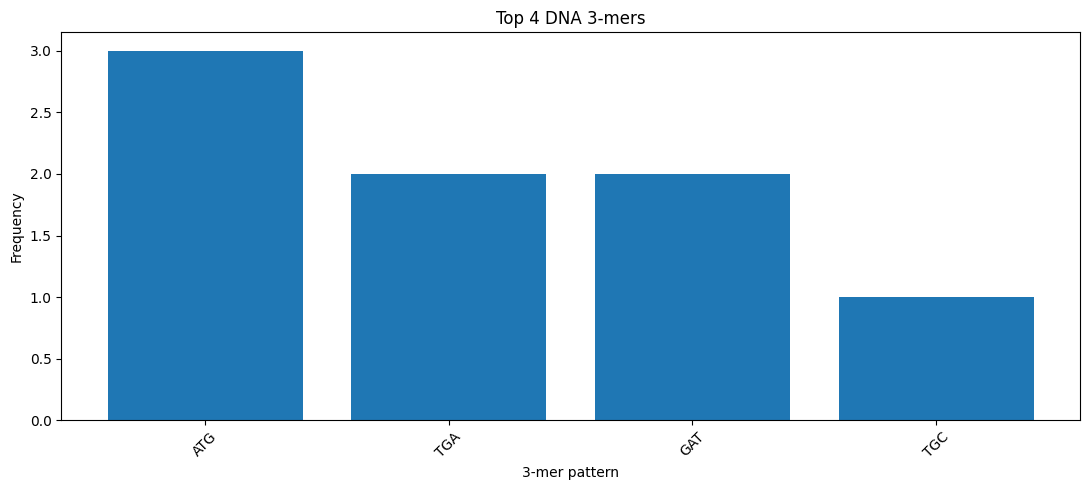

In [ ]:
sample_dna = "ATGATGATGC"

kmer_results = kmer_analysis_dashboard(
    sample_dna,
    k=3,
    top_n=10
)

In [ ]:
from pathlib import Path

def generate_dna_report(sequence, sequence_name="DNA_Sequence"):
    """
    Generate a basic DNA composition report and save it as a text file.
    """

    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(f"Invalid DNA sequence: {result}")

    sequence = result

    if not sequence:
        raise ValueError("DNA sequence cannot be empty.")

    length = len(sequence)

    counts = {
        base: sequence.count(base)
        for base in "ATGC"
    }

    percentages = {
        base: counts[base] / length * 100
        for base in "ATGC"
    }

    gc_content = percentages["G"] + percentages["C"]
    at_content = percentages["A"] + percentages["T"]

    gc_at_ratio = (
        (counts["G"] + counts["C"]) /
        (counts["A"] + counts["T"])
        if (counts["A"] + counts["T"]) > 0
        else None
    )

    report = f"""
========================================
        BIOSEQ AI DNA ANALYSIS REPORT
========================================

Sequence Name: {sequence_name}

1. BASIC INFORMATION
--------------------
Sequence Length: {length} bp

2. NUCLEOTIDE COUNTS
--------------------
Adenine (A):  {counts['A']}
Thymine (T):  {counts['T']}
Guanine (G):  {counts['G']}
Cytosine (C): {counts['C']}

3. NUCLEOTIDE PERCENTAGES
-------------------------
A: {percentages['A']:.2f}%
T: {percentages['T']:.2f}%
G: {percentages['G']:.2f}%
C: {percentages['C']:.2f}%

4. COMPOSITION STATISTICS
-------------------------
GC Content: {gc_content:.2f}%
AT Content: {at_content:.2f}%
GC/AT Ratio: {
    f'{gc_at_ratio:.3f}' if gc_at_ratio is not None else 'Undefined (AT count is zero)'
}

5. SCIENTIFIC NOTE
------------------
This report describes nucleotide composition only.
GC content alone cannot establish gene function,
sequence quality, pathogenicity, or clinical significance.

========================================
Generated by BioSeq AI
========================================
"""

    safe_name = "".join(
        char if char.isalnum() or char in "_-" else "_"
        for char in str(sequence_name)
    ).strip("_") or "DNA_Sequence"

    report_path = Path(f"{safe_name}_report.txt")
    report_path.write_text(report.strip() + "\n", encoding="utf-8")

    print(report)
    print("\nReport saved to:", report_path.resolve())

    return report, str(report_path)


print("DNA Report Generator is ready!")

DNA Report Generator is ready!


In [ ]:
sample_dna = "ATGCGCTAATGC"

report_text, report_file = generate_dna_report(
    sample_dna,
    sequence_name="My_Test_DNA"
)


        BIOSEQ AI DNA ANALYSIS REPORT

Sequence Name: My_Test_DNA

1. BASIC INFORMATION
--------------------
Sequence Length: 12 bp

2. NUCLEOTIDE COUNTS
--------------------
Adenine (A):  3
Thymine (T):  3
Guanine (G):  3
Cytosine (C): 3

3. NUCLEOTIDE PERCENTAGES
-------------------------
A: 25.00%
T: 25.00%
G: 25.00%
C: 25.00%

4. COMPOSITION STATISTICS
-------------------------
GC Content: 50.00%
AT Content: 50.00%
GC/AT Ratio: 1.000

5. SCIENTIFIC NOTE
------------------
This report describes nucleotide composition only.
GC content alone cannot establish gene function,
sequence quality, pathogenicity, or clinical significance.

Generated by BioSeq AI


Report saved to: /content/My_Test_DNA_report.txt


In [ ]:
from google.colab import files

files.download(report_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt

def bioseq_dashboard(sequence, analysis_type):
    if not isinstance(sequence, str) or not sequence.strip():
        return "Please enter a DNA sequence.", None

    valid, result = validate_dna(sequence)

    if not valid:
        return f"Invalid DNA sequence: {result}", None

    sequence = result

    length = len(sequence)
    counts = {base: sequence.count(base) for base in "ATGC"}
    gc_content = (counts["G"] + counts["C"]) / length * 100
    at_content = (counts["A"] + counts["T"]) / length * 100

    report = (
        f"BIOSEQ AI — DNA ANALYSIS\n"
        f"{'=' * 35}\n"
        f"Sequence length: {length} bp\n"
        f"A count: {counts['A']}\n"
        f"T count: {counts['T']}\n"
        f"G count: {counts['G']}\n"
        f"C count: {counts['C']}\n"
        f"GC content: {gc_content:.2f}%\n"
        f"AT content: {at_content:.2f}%\n"
    )

    if analysis_type == "Reverse Complement":
        report += "\nReverse complement:\n" + reverse_complement(sequence)

    elif analysis_type == "Motif Search":
        motif = "ATG"
        positions = []
        start = 0

        while True:
            index = sequence.find(motif, start)
            if index == -1:
                break
            positions.append(index + 1)
            start = index + 1

        report += f"\nMotif searched: {motif}\n"
        report += f"Occurrences: {len(positions)}\n"
        report += f"Positions: {positions}"

    elif analysis_type == "K-mer Frequency":
        from collections import Counter

        kmers = [
            sequence[i:i + 3]
            for i in range(len(sequence) - 2)
        ]

        counts_3mer = Counter(kmers)

        report += "\nTop 3-mers:\n"
        report += str(counts_3mer.most_common(10))

    elif analysis_type == "GC Sliding Window":
        window_size = min(10, length)

        rows = []
        for start in range(0, length - window_size + 1):
            window = sequence[start:start + window_size]
            gc = (window.count("G") + window.count("C")) / len(window) * 100

            rows.append({
                "Start": start + 1,
                "End": start + window_size,
                "GC Content (%)": round(gc, 2)
            })

        df = pd.DataFrame(rows)

        fig, ax = plt.subplots(figsize=(8, 4))
        ax.plot(df["Start"], df["GC Content (%)"], marker="o")
        ax.set_xlabel("Window Start Position")
        ax.set_ylabel("GC Content (%)")
        ax.set_title("GC Content Across DNA Sequence")
        ax.set_ylim(0, 100)
        ax.grid(True, alpha=0.3)
        plt.tight_layout()

        return report, fig

    return report, None


with gr.Blocks(title="BioSeq AI") as bioseq_app:
    gr.Markdown("# 🧬 BioSeq AI")
    gr.Markdown(
        "An educational DNA sequence analysis dashboard. "
        "Results are descriptive and are not clinical diagnoses."
    )

    sequence_input = gr.Textbox(
        label="Enter DNA Sequence",
        placeholder="Example: ATGCGCTAATGC",
        lines=4
    )

    analysis_dropdown = gr.Dropdown(
        choices=[
            "Basic DNA Analysis",
            "Reverse Complement",
            "Motif Search",
            "K-mer Frequency",
            "GC Sliding Window"
        ],
        value="Basic DNA Analysis",
        label="Choose Analysis"
    )

    analyze_button = gr.Button("Analyze DNA", variant="primary")

    report_output = gr.Textbox(
        label="Analysis Results",
        lines=12
    )

    graph_output = gr.Plot(label="Visualization")

    analyze_button.click(
        fn=bioseq_dashboard,
        inputs=[sequence_input, analysis_dropdown],
        outputs=[report_output, graph_output]
    )


print("BioSeq AI interface is ready!")

BioSeq AI interface is ready!


In [ ]:
bioseq_app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://26398c7238f0143be7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import pandas as pd
from Bio import SeqIO
from Bio.SeqUtils import gc_fraction
from google.colab import files

def batch_fasta_analyzer(file_path):
    records = []
    errors = []

    try:
        for record in SeqIO.parse(file_path, "fasta"):
            sequence = str(record.seq).upper().replace(" ", "")

            if not sequence:
                errors.append(f"{record.id}: Empty sequence")
                continue

            invalid_bases = set(sequence) - set("ATGC")

            if invalid_bases:
                errors.append(
                    f"{record.id}: Invalid characters "
                    f"{sorted(invalid_bases)}"
                )
                continue

            length = len(sequence)
            counts = {
                base: sequence.count(base)
                for base in "ATGC"
            }

            gc_content = gc_fraction(sequence) * 100
            at_content = (
                (counts["A"] + counts["T"]) / length
            ) * 100

            records.append({
                "Sequence ID": record.id,
                "Description": record.description,
                "Length (bp)": length,
                "A Count": counts["A"],
                "T Count": counts["T"],
                "G Count": counts["G"],
                "C Count": counts["C"],
                "GC Content (%)": round(gc_content, 2),
                "AT Content (%)": round(at_content, 2)
            })

    except Exception as e:
        print("Error reading FASTA file:", e)
        return None

    if not records:
        print("No valid DNA sequences found.")
        if errors:
            print("\nIssues:")
            for error in errors:
                print("-", error)
        return None

    df = pd.DataFrame(records)

    print("=" * 50)
    print("       BIOSEQ AI — BATCH ANALYSIS")
    print("=" * 50)
    print("Valid sequences:", len(df))
    print("Total bases:", df["Length (bp)"].sum())
    print(
        "Average sequence length:",
        round(df["Length (bp)"].mean(), 2),
        "bp"
    )
    print(
        "Average GC content:",
        round(df["GC Content (%)"].mean(), 2),
        "%"
    )

    display(df)

    if errors:
        print("\nSkipped sequences:")
        for error in errors:
            print("-", error)

    output_file = "BioSeqAI_Batch_Results.csv"
    df.to_csv(output_file, index=False)

    print("\nCSV report created:", output_file)

    return df


print("Multi-FASTA Batch Analyzer is ready!")

Multi-FASTA Batch Analyzer is ready!


In [ ]:

sample_fasta = """>Sequence_1 First sample DNA
ATGCGCTAATGC
>Sequence_2 Second sample DNA
ATATATGCGCGC
>Sequence_3 Third sample DNA
GGCCATATGGCC
"""

with open("sample_sequences.fasta", "w") as f:
    f.write(sample_fasta)

print("Sample FASTA file created successfully!")

Sample FASTA file created successfully!


In [ ]:
results_df = batch_fasta_analyzer("sample_sequences.fasta")

       BIOSEQ AI — BATCH ANALYSIS
Valid sequences: 3
Total bases: 36
Average sequence length: 12.0 bp
Average GC content: 55.56 %


,Sequence ID,Description,Length (bp),A Count,T Count,G Count,C Count,GC Content (%),AT Content (%)
0,Sequence_1,Sequence_1 First sample DNA,12,3,3,3,3,50.00,50.00
1,Sequence_2,Sequence_2 Second sample DNA,12,3,3,3,3,50.00,50.00
2,Sequence_3,Sequence_3 Third sample DNA,12,2,2,4,4,66.67,33.33



CSV report created: BioSeqAI_Batch_Results.csv


In [ ]:
files.download("BioSeqAI_Batch_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
from Bio.Seq import Seq
from Bio.Align import PairwiseAligner

def mutation_impact_explorer(reference, mutated):
    reference = "".join(reference.upper().split())
    mutated = "".join(mutated.upper().split())

    # Validate sequences
    valid_bases = set("ATGC")

    if not reference or not mutated:
        return "Error: Dono DNA sequences enter karo.", None

    if set(reference) - valid_bases:
        return "Error: Reference sequence mein sirf A, T, G, C use karo.", None

    if set(mutated) - valid_bases:
        return "Error: Mutated sequence mein sirf A, T, G, C use karo.", None

    # Align sequences
    aligner = PairwiseAligner()
    aligner.mode = "global"
    aligner.match_score = 2
    aligner.mismatch_score = -1
    aligner.open_gap_score = -3
    aligner.extend_gap_score = -0.5

    alignment = aligner.align(reference, mutated)[0]

    aligned_reference, aligned_mutated = str(alignment).splitlines()[-3::2]

    # Compare translated proteins only if both sequences
    # are complete, equal-length coding sequences.
    protein_comparison = (
        len(reference) == len(mutated)
        and len(reference) % 3 == 0
    )

    rows = []
    substitutions = 0
    insertions = 0
    deletions = 0
    ref_position = 0
    mut_position = 0

    for ref_base, mut_base in zip(aligned_reference, aligned_mutated):
        if ref_base != "-":
            ref_position += 1

        if mut_base != "-":
            mut_position += 1

        if ref_base == mut_base:
            continue

        if ref_base == "-":
            mutation_type = "Insertion"
        elif mut_base == "-":
            mutation_type = "Deletion"
        else:
            mutation_type = "Substitution"

        if mutation_type == "Insertion":
            insertions += 1
        elif mutation_type == "Deletion":
            deletions += 1
        else:
            substitutions += 1

        rows.append({
            "Mutation": mutation_type,
            "Reference Position": ref_position if ref_base != "-" else "-",
            "Reference Base": ref_base,
            "Mutated Position": mut_position if mut_base != "-" else "-",
            "Mutated Base": mut_base
        })

    df = pd.DataFrame(
        rows,
        columns=[
            "Mutation",
            "Reference Position",
            "Reference Base",
            "Mutated Position",
            "Mutated Base"
        ]
    )

    report = (
        "BIOSEQ AI — MUTATION IMPACT EXPLORER\n"
        + "=" * 42 + "\n"
        f"Reference length: {len(reference)} bp\n"
        f"Mutated length: {len(mutated)} bp\n"
        f"Length difference: {len(mutated) - len(reference)} bp\n\n"
        f"Substitutions: {substitutions}\n"
        f"Insertions: {insertions}\n"
        f"Deletions: {deletions}\n"
    )

    if protein_comparison:
        reference_protein = str(Seq(reference).translate())
        mutated_protein = str(Seq(mutated).translate())

        amino_acid_changes = [
            {
                "Position": i + 1,
                "Reference AA": aa1,
                "Mutated AA": aa2
            }
            for i, (aa1, aa2) in enumerate(
                zip(reference_protein, mutated_protein)
            )
            if aa1 != aa2
        ]

        report += "\nPROTEIN TRANSLATION COMPARISON\n"
        report += f"Reference protein: {reference_protein}\n"
        report += f"Mutated protein:  {mutated_protein}\n"
        report += f"Amino acid differences: {len(amino_acid_changes)}\n"

        if amino_acid_changes:
            report += (
                "\nAmino acid differences are listed in the report. "
                "They do not establish whether a mutation is harmful."
            )
        else:
            report += "\nNo amino acid differences detected."

    else:
        report += (
            "\nProtein comparison skipped: both sequences must have "
            "equal lengths divisible by 3 for this simple comparison."
        )

    report += (
        "\n\nScientific note: This is an educational sequence comparison. "
        "Alignment-based positions can depend on the selected alignment. "
        "The results do not establish biological or clinical impact."
    )

    return report, df


print("DNA Mutation Impact Explorer is ready!")

DNA Mutation Impact Explorer is ready!


In [ ]:
reference_dna = "ATGGCTTTT"
mutated_dna  = "ATGGATTTT"

mutation_report, mutation_table = mutation_impact_explorer(
    reference_dna,
    mutated_dna
)

print(mutation_report)
display(mutation_table)

BIOSEQ AI — MUTATION IMPACT EXPLORER
Reference length: 9 bp
Mutated length: 9 bp
Length difference: 0 bp

Substitutions: 7
Insertions: 0
Deletions: 0

PROTEIN TRANSLATION COMPARISON
Reference protein: MAF
Mutated protein:  MDF
Amino acid differences: 1

Amino acid differences are listed in the report. They do not establish whether a mutation is harmful.

Scientific note: This is an educational sequence comparison. Alignment-based positions can depend on the selected alignment. The results do not establish biological or clinical impact.


,Mutation,Reference Position,Reference Base,Mutated Position,Mutated Base
0,Substitution,1,t,1,q
1,Substitution,2,a,2,u
2,Substitution,3,r,3,e
3,Substitution,4,g,4,r
4,Substitution,5,e,5,y
5,Substitution,6,t,6,
6,Substitution,25,C,25,A


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

def explain_promoter_prediction(sequence, model, df=None):
    """
    Educational promoter-classification explanation.
    Assumes the existing model is a fitted scikit-learn pipeline.
    """

    sequence = "".join(str(sequence).upper().split())

    if not sequence:
        return "Error: DNA sequence enter karo.", None

    if set(sequence) - set("ATGC"):
        return "Error: Sequence mein sirf A, T, G, C allowed hain.", None

    if not hasattr(model, "predict"):
        return "Error: Trained model available nahi hai.", None

    prediction = model.predict([sequence])[0]

    report = [
        "BIOSEQ AI — PROMOTER PREDICTION EXPLAINER",
        "=" * 45,
        f"Sequence length: {len(sequence)} bp",
        f"GC content: {(sequence.count('G') + sequence.count('C')) / len(sequence) * 100:.2f}%",
        f"Predicted class: {prediction}",
        "",
        "Interpretation:"
    ]

    if str(prediction) == "+":
        report.append(
            "The model classified this sequence as the positive "
            "class in its training labels."
        )
    else:
        report.append(
            "The model classified this sequence as the negative "
            "class in its training labels."
        )

    # Show probability only if the model supports it.
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba([sequence])[0]
        classes = model.classes_

        report.append("")
        report.append("Model output probabilities:")

        probability_rows = []

        for class_name, probability in zip(classes, probabilities):
            report.append(
                f"Class {class_name}: {probability:.4f}"
            )
            probability_rows.append({
                "Class": str(class_name),
                "Model Probability": round(float(probability), 4)
            })

        probability_df = pd.DataFrame(probability_rows)

    else:
        probability_df = pd.DataFrame(
            columns=["Class", "Model Probability"]
        )
        report.append(
            "This model does not provide predict_proba output."
        )

    report.extend([
        "",
        "Important limitations:",
        "- Probabilities are model outputs, not biological certainty.",
        "- Training data size and representativeness affect reliability.",
        "- This prediction does not prove promoter function.",
        "- Experimental validation may be needed."
    ])

    return "\n".join(report), probability_df


print("Promoter Prediction Explainability is ready!")

Promoter Prediction Explainability is ready!


In [ ]:
test_sequence = "TACTAGCAATACGCTTGCGTTCGGTGGTTAAGTATGTATAATGCGCGGGCTTGT"

prediction_report, probability_table = explain_promoter_prediction(
    test_sequence,
    model,
    df
)

print(prediction_report)
display(probability_table)

BIOSEQ AI — PROMOTER PREDICTION EXPLAINER
Sequence length: 54 bp
GC content: 46.30%
Predicted class: +

Interpretation:
The model classified this sequence as the positive class in its training labels.

Model output probabilities:
Class +: 0.9567
Class -: 0.0433

Important limitations:
- Probabilities are model outputs, not biological certainty.
- Training data size and representativeness affect reliability.
- This prediction does not prove promoter function.
- Experimental validation may be needed.


,Class,Model Probability
0,+,0.9567
1,-,0.0433


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

def plot_promoter_model_features(model, top_n=15):

    if not hasattr(model, "named_steps"):
        print("Error: Expected a fitted scikit-learn pipeline.")
        return None

    steps = model.named_steps

    # Your actual pipeline step names
    if "vectorizer" not in steps or "classifier" not in steps:
        print("Unexpected pipeline steps:", list(steps.keys()))
        return None

    vectorizer = steps["vectorizer"]
    classifier = steps["classifier"]

    if not hasattr(classifier, "coef_"):
        print("Error: Classifier does not expose linear coefficients.")
        return None

    if len(classifier.classes_) != 2:
        print("This visualization supports binary classification only.")
        return None

    feature_names = vectorizer.get_feature_names_out()
    coefficients = classifier.coef_[0]

    feature_df = pd.DataFrame({
        "DNA Pattern": feature_names,
        "Coefficient": coefficients
    })

    top_n = max(1, min(int(top_n), len(feature_df)))

    negative_features = feature_df.nsmallest(
        top_n, "Coefficient"
    )
    positive_features = feature_df.nlargest(
        top_n, "Coefficient"
    )

    selected = pd.concat(
        [negative_features, positive_features]
    ).drop_duplicates()

    print("Model classes:", classifier.classes_)
    print(
        "Positive coefficients favor class:",
        classifier.classes_[1]
    )
    print(
        "Negative coefficients favor class:",
        classifier.classes_[0]
    )

    display(selected.sort_values("Coefficient", ascending=False))

    plt.figure(figsize=(10, max(6, len(selected) * 0.35)))

    plt.barh(
        selected["DNA Pattern"],
        selected["Coefficient"]
    )

    plt.axvline(0, linewidth=1)
    plt.xlabel("Logistic Regression Coefficient")
    plt.ylabel("DNA Pattern")
    plt.title("BioSeq AI — Learned DNA Pattern Coefficients")
    plt.tight_layout()
    plt.show()

    print(
        "\nNote: Coefficients show learned model associations. "
        "They do not prove biological function or causation."
    )

    return selected


print("Fixed function is ready!")

Fixed function is ready!


Model classes: ['+' '-']
Positive coefficients favor class: -
Negative coefficients favor class: +


,DNA Pattern,Coefficient
66,tca,0.764601
54,ggt,0.502211
7,acc,0.497734
43,gag,0.497557
2,aac,0.455475
18,atg,0.431562
40,ga,0.429869
56,gta,0.406321
35,ct,0.373489
39,ctt,0.363995


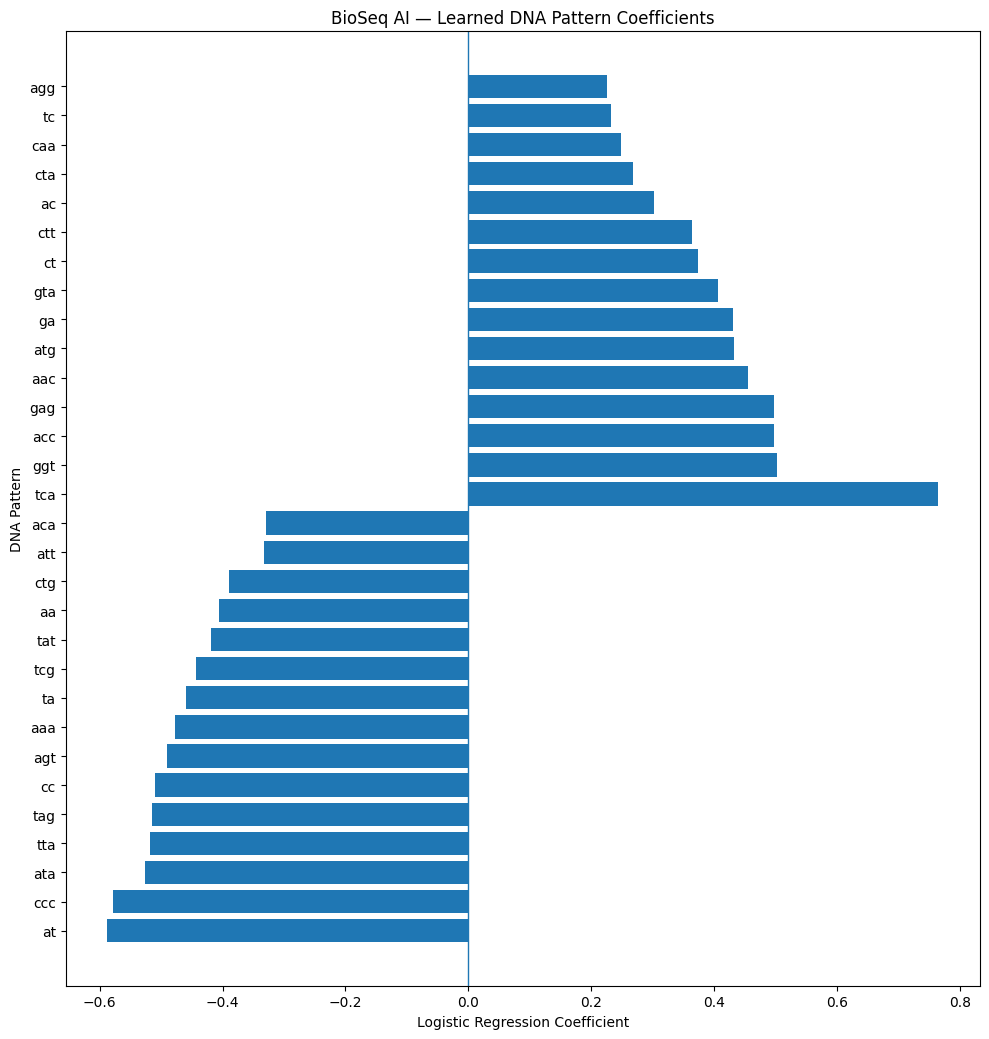


Note: Coefficients show learned model associations. They do not prove biological function or causation.


In [ ]:
feature_results = plot_promoter_model_features(
    model,
    top_n=15
)

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

def multi_sequence_comparison(sequences, labels=None):
    """
    Compare multiple DNA sequences using global alignment.

    Similarity is calculated as:
    identical aligned nucleotide pairs / total alignment columns * 100.

    This is an educational similarity measure, not a phylogenetic analysis.
    """

    from Bio.Align import PairwiseAligner

    if not isinstance(sequences, (list, tuple)) or len(sequences) < 2:
        print("Please provide at least two DNA sequences.")
        return None, None

    cleaned = []

    for i, sequence in enumerate(sequences):
        if not isinstance(sequence, str):
            print(f"Sequence {i + 1} must be text.")
            return None, None

        sequence = "".join(sequence.upper().split())

        if not sequence:
            print(f"Sequence {i + 1} is empty.")
            return None, None

        if set(sequence) - set("ATGC"):
            print(f"Sequence {i + 1} contains invalid DNA characters.")
            return None, None

        cleaned.append(sequence)

    if labels is None:
        labels = [f"Sequence_{i + 1}" for i in range(len(cleaned))]

    if len(labels) != len(cleaned):
        print("The number of labels must match the number of sequences.")
        return None, None

    if len(set(labels)) != len(labels):
        print("Please provide unique labels for each sequence.")
        return None, None

    aligner = PairwiseAligner()
    aligner.mode = "global"
    aligner.match_score = 2
    aligner.mismatch_score = -1
    aligner.open_gap_score = -3
    aligner.extend_gap_score = -0.5

    n = len(cleaned)
    similarity_matrix = [[0.0] * n for _ in range(n)]
    pair_results = []

    for i in range(n):
        similarity_matrix[i][i] = 100.0

    for i, j in combinations(range(n), 2):
        alignment = aligner.align(cleaned[i], cleaned[j])[0]
        coordinates = alignment.coordinates

        identical = 0
        alignment_columns = 0
        gaps = 0

        for k in range(coordinates.shape[1] - 1):
            ref_start, ref_end = coordinates[0, k], coordinates[0, k + 1]
            query_start, query_end = coordinates[1, k], coordinates[1, k + 1]

            ref_len = ref_end - ref_start
            query_len = query_end - query_start

            if ref_len > 0 and query_len > 0:
                segment_length = min(ref_len, query_len)

                ref_segment = cleaned[i][ref_start:ref_start + segment_length]
                query_segment = cleaned[j][query_start:query_start + segment_length]

                identical += sum(
                    a == b for a, b in zip(ref_segment, query_segment)
                )

                alignment_columns += max(ref_len, query_len)
                gaps += abs(ref_len - query_len)

            else:
                gap_length = max(ref_len, query_len)
                alignment_columns += gap_length
                gaps += gap_length

        similarity = (
            identical / alignment_columns * 100
            if alignment_columns else 0.0
        )

        similarity_matrix[i][j] = similarity
        similarity_matrix[j][i] = similarity

        pair_results.append({
            "Sequence 1": labels[i],
            "Sequence 2": labels[j],
            "Length 1 (bp)": len(cleaned[i]),
            "Length 2 (bp)": len(cleaned[j]),
            "Alignment Score": round(float(alignment.score), 2),
            "Identical Bases": identical,
            "Gap Columns": gaps,
            "Similarity (%)": round(similarity, 2)
        })

    similarity_df = pd.DataFrame(
        similarity_matrix,
        index=labels,
        columns=labels
    )

    pair_df = pd.DataFrame(pair_results)

    print("Pairwise Alignment Results")
    display(pair_df)

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        similarity_df,
        annot=True,
        fmt=".1f",
        vmin=0,
        vmax=100,
        cmap="viridis"
    )
    plt.title("DNA Pairwise Similarity Heatmap (%)")
    plt.tight_layout()
    plt.show()

    return pair_df, similarity_df


print("Multi-Sequence Comparison Dashboard is ready!")

Multi-Sequence Comparison Dashboard is ready!


Pairwise Alignment Results


,Sequence 1,Sequence 2,Length 1 (bp),Length 2 (bp),Alignment Score,Identical Bases,Gap Columns,Similarity (%)
0,Reference,Sequence_B,12,12,21.0,11,0,91.67
1,Reference,Sequence_C,12,12,21.0,11,0,91.67
2,Sequence_B,Sequence_C,12,12,18.0,10,0,83.33


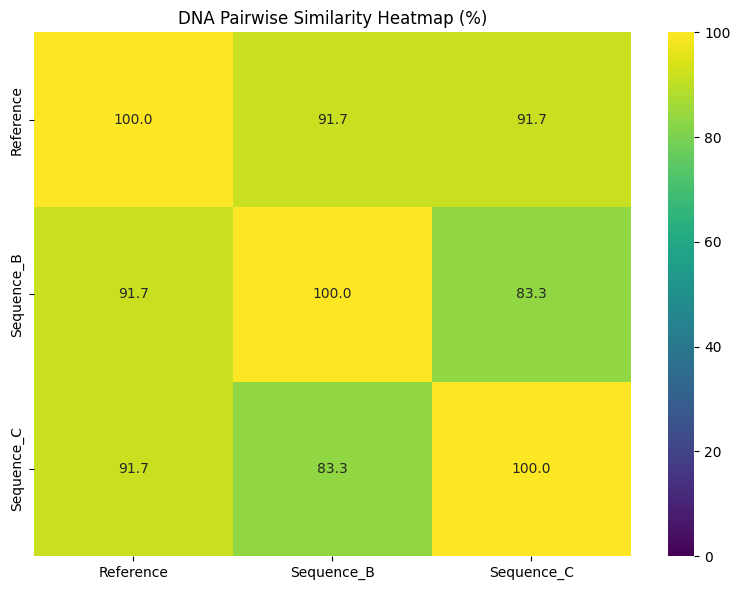

In [ ]:
test_sequences = [
    "ATGCGCTAATGC",
    "ATGCGCTAATGT",
    "ATGCGCAAATGC"
]

test_labels = [
    "Reference",
    "Sequence_B",
    "Sequence_C"
]

pair_results, similarity_matrix = multi_sequence_comparison(
    test_sequences,
    test_labels
)

In [ ]:
pair_results.to_csv(
    "BioSeqAI_MultiSequence_Comparison.csv",
    index=False
)

similarity_matrix.to_csv(
    "BioSeqAI_Similarity_Matrix.csv"
)

print("Both CSV files saved successfully!")

Both CSV files saved successfully!


In [ ]:
from google.colab import files

files.download("BioSeqAI_MultiSequence_Comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from datetime import datetime
from pathlib import Path
from collections import Counter
import pandas as pd

def generate_professional_dna_report(sequence, sequence_name="DNA_Sequence"):
    sequence = "".join(str(sequence).upper().split())

    if not sequence:
        return "Error: DNA sequence enter karo.", None

    if set(sequence) - set("ATGC"):
        return "Error: Sirf A, T, G, C bases allowed hain.", None

    length = len(sequence)
    counts = Counter(sequence)

    gc_count = counts["G"] + counts["C"]
    at_count = counts["A"] + counts["T"]

    gc_percent = gc_count / length * 100
    at_percent = at_count / length * 100

    composition_df = pd.DataFrame([
        {
            "Nucleotide": base,
            "Count": counts[base],
            "Percentage": round(counts[base] / length * 100, 2)
        }
        for base in "ATGC"
    ])

    timestamp = datetime.now().astimezone().isoformat(timespec="seconds")

    report = f"""
BIOSEQ AI — PROFESSIONAL DNA ANALYSIS REPORT
==================================================

Sequence name: {sequence_name}
Generated at: {timestamp}

1. SEQUENCE OVERVIEW
--------------------
Sequence length: {length} base pairs
Total nucleotides: {length}

2. NUCLEOTIDE COMPOSITION
-------------------------
Adenine (A):  {counts["A"]}
Thymine (T):  {counts["T"]}
Guanine (G):  {counts["G"]}
Cytosine (C): {counts["C"]}

3. BASE COMPOSITION
-------------------
GC content: {gc_percent:.2f}%
AT content: {at_percent:.2f}%

4. BASIC VALIDATION
-------------------
Characters checked: A, T, G, C
Invalid characters: 0
Sequence contains only accepted DNA bases.

5. SCIENTIFIC LIMITATIONS
-------------------------
This report describes sequence composition only.
It does not establish gene function, biological activity,
disease association, or clinical significance.

GC content alone cannot determine whether a sequence
is a promoter or whether a sequence is biologically active.

==================================================
Generated by BioSeq AI — Educational Bioinformatics Tool
"""

    safe_name = "".join(
        char if char.isalnum() or char in "-_" else "_"
        for char in str(sequence_name)
    ).strip("_")

    if not safe_name:
        safe_name = "DNA_Sequence"

    txt_path = Path(f"{safe_name}_professional_report.txt")
    csv_path = Path(f"{safe_name}_composition.csv")

    txt_path.write_text(report, encoding="utf-8")
    composition_df.to_csv(csv_path, index=False)

    print(report)
    display(composition_df)

    print(f"\nTXT report saved: {txt_path}")
    print(f"CSV composition saved: {csv_path}")

    return report, composition_df


print("Professional DNA Report Generator is ready!")

Professional DNA Report Generator is ready!


In [ ]:
sample_sequence = "ATGCGCTAATGC"

report, composition = generate_professional_dna_report(
    sample_sequence,
    sequence_name="BioSeqAI_Test"
)


BIOSEQ AI — PROFESSIONAL DNA ANALYSIS REPORT

Sequence name: BioSeqAI_Test
Generated at: 2026-10-22T13:02:25+00:00

1. SEQUENCE OVERVIEW
--------------------
Sequence length: 12 base pairs
Total nucleotides: 12

2. NUCLEOTIDE COMPOSITION
-------------------------
Adenine (A):  3
Thymine (T):  3
Guanine (G):  3
Cytosine (C): 3

3. BASE COMPOSITION
-------------------
GC content: 50.00%
AT content: 50.00%

4. BASIC VALIDATION
-------------------
Characters checked: A, T, G, C
Invalid characters: 0
Sequence contains only accepted DNA bases.

5. SCIENTIFIC LIMITATIONS
-------------------------
This report describes sequence composition only.
It does not establish gene function, biological activity,
disease association, or clinical significance.

GC content alone cannot determine whether a sequence
is a promoter or whether a sequence is biologically active.

Generated by BioSeq AI — Educational Bioinformatics Tool



,Nucleotide,Count,Percentage
0,A,3,25.0
1,T,3,25.0
2,G,3,25.0
3,C,3,25.0



TXT report saved: BioSeqAI_Test_professional_report.txt
CSV composition saved: BioSeqAI_Test_composition.csv


In [ ]:
from google.colab import files

files.download("BioSeqAI_Test_professional_report.txt")

In [ ]:
files.download("BioSeqAI_Test_composition.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import gradio as gr
import pandas as pd
from collections import Counter

def run_integrated_analysis(sequence, analysis_type, motif):
    sequence = "".join(str(sequence).upper().split())

    if not sequence:
        return "Please enter a DNA sequence.", pd.DataFrame()

    if set(sequence) - set("ATGC"):
        return (
            "Invalid DNA sequence. Only A, T, G and C are accepted.",
            pd.DataFrame()
        )

    length = len(sequence)
    counts = Counter(sequence)
    gc_percent = (counts["G"] + counts["C"]) / length * 100
    at_percent = (counts["A"] + counts["T"]) / length * 100

    summary = []
    table = pd.DataFrame()

    if analysis_type == "Basic DNA Statistics":
        summary = [
            "BIOSEQ AI — BASIC DNA STATISTICS",
            "=" * 35,
            f"Sequence length: {length} bp",
            f"GC content: {gc_percent:.2f}%",
            f"AT content: {at_percent:.2f}%"
        ]

        table = pd.DataFrame([
            {
                "Nucleotide": base,
                "Count": counts[base],
                "Percentage (%)": round(counts[base] / length * 100, 2)
            }
            for base in "ATGC"
        ])

    elif analysis_type == "Reverse Complement":
        complement = sequence.translate(str.maketrans("ATGC", "TACG"))
        reverse_complement = complement[::-1]

        summary = [
            "BIOSEQ AI — REVERSE COMPLEMENT",
            "=" * 35,
            f"Original: {sequence}",
            f"Complement: {complement}",
            f"Reverse complement: {reverse_complement}"
        ]

    elif analysis_type == "Motif Search":
        motif = "".join(str(motif).upper().split())

        if not motif or set(motif) - set("ATGC"):
            return (
                "Enter a valid motif containing only A, T, G and C.",
                pd.DataFrame()
            )

        positions = []
        start = 0

        while True:
            index = sequence.find(motif, start)
            if index == -1:
                break

            positions.append(index + 1)
            start = index + 1

        summary = [
            "BIOSEQ AI — MOTIF SEARCH",
            "=" * 35,
            f"Motif: {motif}",
            f"Occurrences: {len(positions)}",
            f"1-based start positions: {positions}"
        ]

        table = pd.DataFrame({
            "Occurrence": range(1, len(positions) + 1),
            "Start Position": positions,
            "End Position": [p + len(motif) - 1 for p in positions]
        })

    elif analysis_type == "K-mer Frequency":
        k = 3

        if length < k:
            return (
                "Sequence must contain at least 3 bases for 3-mer analysis.",
                pd.DataFrame()
            )

        kmers = [
            sequence[i:i + k]
            for i in range(length - k + 1)
        ]

        kmer_counts = Counter(kmers)
        total = len(kmers)

        table = pd.DataFrame([
            {
                "K-mer": mer,
                "Count": count,
                "Frequency (%)": round(count / total * 100, 2)
            }
            for mer, count in kmer_counts.most_common()
        ])

        summary = [
            "BIOSEQ AI — 3-MER FREQUENCY",
            "=" * 35,
            f"Total 3-mer windows: {total}",
            f"Distinct 3-mers: {len(kmer_counts)}"
        ]

    elif analysis_type == "GC Window Analysis":
        window_size = min(10, length)
        rows = []

        for i in range(length - window_size + 1):
            window = sequence[i:i + window_size]
            gc = (window.count("G") + window.count("C")) / window_size * 100

            rows.append({
                "Start": i + 1,
                "End": i + window_size,
                "GC Content (%)": round(gc, 2)
            })

        table = pd.DataFrame(rows)

        summary = [
            "BIOSEQ AI — GC WINDOW ANALYSIS",
            "=" * 35,
            f"Window size: {window_size} bp",
            f"Number of windows: {len(table)}",
            f"Average window GC: {table['GC Content (%)'].mean():.2f}%"
        ]

    summary.append("")
    summary.append(
        "Educational analysis only; results do not establish "
        "biological function or clinical significance."
    )

    return "\n".join(summary), table


with gr.Blocks(title="BioSeq AI — Integrated Dashboard") as bioseq_dashboard_app:

    gr.Markdown("# 🧬 BioSeq AI")
    gr.Markdown(
        "Integrated DNA sequence analysis for educational "
        "bioinformatics demonstrations."
    )

    with gr.Row():
        sequence_input = gr.Textbox(
            label="DNA Sequence",
            placeholder="Example: ATGCGCTAATGC",
            lines=4
        )

        analysis_type = gr.Dropdown(
            choices=[
                "Basic DNA Statistics",
                "Reverse Complement",
                "Motif Search",
                "K-mer Frequency",
                "GC Window Analysis"
            ],
            value="Basic DNA Statistics",
            label="Select Analysis"
        )

    motif_input = gr.Textbox(
        label="Motif for Motif Search",
        value="ATG"
    )

    run_button = gr.Button("Run Analysis", variant="primary")

    summary_output = gr.Textbox(
        label="Analysis Summary",
        lines=10
    )

    table_output = gr.Dataframe(
        label="Detailed Results",
        interactive=False
    )

    run_button.click(
        fn=run_integrated_analysis,
        inputs=[sequence_input, analysis_type, motif_input],
        outputs=[summary_output, table_output]
    )

    gr.Examples(
        examples=[
            ["ATGCGCTAATGC", "Basic DNA Statistics", "ATG"],
            ["ATGCGCTAATGC", "Reverse Complement", "ATG"],
            ["ATGATGCCCATG", "Motif Search", "ATG"],
            ["ATGCGCTAATGC", "K-mer Frequency", "ATG"],
            ["ATGCGCTAATGC", "GC Window Analysis", "ATG"]
        ],
        inputs=[sequence_input, analysis_type, motif_input]
    )

print("Integrated BioSeq AI dashboard is ready!")

Integrated BioSeq AI dashboard is ready!


In [ ]:
bioseq_dashboard_app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://abf09519f7139b4cb8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# STEP 39: Add ML Promoter Prediction to BioSeq AI

import pandas as pd
import gradio as gr

def predict_promoter_dashboard(sequence):
    """
    Educational promoter-classification demo.
    Predictions are not experimental or clinical evidence.
    """

    if not isinstance(sequence, str) or not sequence.strip():
        return "Please enter a DNA sequence.", pd.DataFrame()

    sequence = sequence.strip().upper()

    # Validate DNA characters
    valid, result = validate_dna(sequence)

    if not valid:
        return f"Invalid DNA sequence: {result}", pd.DataFrame()

    try:
        # Use the existing trained model
        prediction = model.predict([sequence])[0]

        # Obtain class probabilities if supported
        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba([sequence])[0]
            classes = model.classes_

            probability_table = pd.DataFrame({
                "Class": classes,
                "Model Probability (%)": [
                    round(float(p) * 100, 2)
                    for p in probabilities
                ]
            })
        else:
            probability_table = pd.DataFrame({
                "Class": [str(prediction)],
                "Model Probability (%)": ["Not available"]
            })

        warning = ""

        if len(sequence) != 57:
            warning = (
                "\n⚠️ Note: The training sequences were 57 bp long. "
                "This sequence has a different length, so its prediction "
                "may be less reliable.\n"
            )

        summary = (
            "========== BioSeq AI Promoter Prediction ==========\n"
            f"Sequence length: {len(sequence)} bp\n"
            f"Predicted class: {prediction}\n"
            f"{warning}\n"
            "Important: This is an educational ML prediction, not "
            "proof that a biological promoter is present or functional."
        )

        return summary, probability_table

    except Exception as e:
        return f"Prediction error: {str(e)}", pd.DataFrame()


print("Step 39 function created successfully!")

Step 39 function created successfully!


In [ ]:
test_sequence = (
    "TACTAGCAATACGCTTGCGTT"
    "CGGTGGTTAA"
    "GTATGTATAATGCGCGGGCTT"
    "GTCGT"
)

summary, probabilities = predict_promoter_dashboard(test_sequence)

print(summary)
display(probabilities)

========== BioSeq AI Promoter Prediction ==========
Sequence length: 57 bp
Predicted class: +

Important: This is an educational ML prediction, not proof that a biological promoter is present or functional.


,Class,Model Probability (%)
0,+,96.6
1,-,3.4


In [ ]:
# STEP 40: Integrated BioSeq AI Dashboard with ML Prediction

import gradio as gr
import pandas as pd
from collections import Counter


def run_bioseq_dashboard_v2(sequence, analysis_type, motif):
    if not isinstance(sequence, str) or not sequence.strip():
        return "Please enter a DNA sequence.", pd.DataFrame()

    sequence = sequence.strip().upper()

    valid, result = validate_dna(sequence)

    if not valid:
        return f"Invalid DNA sequence: {result}", pd.DataFrame()

    # 1. Basic DNA Statistics
    if analysis_type == "Basic DNA Statistics":
        counts = Counter(sequence)
        gc = (counts["G"] + counts["C"]) / len(sequence) * 100
        at = (counts["A"] + counts["T"]) / len(sequence) * 100

        table = pd.DataFrame({
            "Base": ["A", "T", "G", "C"],
            "Count": [counts["A"], counts["T"],
                      counts["G"], counts["C"]]
        })

        summary = (
            f"Sequence length: {len(sequence)} bp\n"
            f"GC content: {gc:.2f}%\n"
            f"AT content: {at:.2f}%"
        )

    # 2. Reverse Complement
    elif analysis_type == "Reverse Complement":
        reverse = reverse_complement(sequence)

        summary = f"Original sequence:\n{sequence}\n\nReverse complement:\n{reverse}"
        table = pd.DataFrame({
            "Position": range(1, len(reverse) + 1),
            "Base": list(reverse)
        })

    # 3. Motif Search
    elif analysis_type == "Motif Search":
        motif = (motif or "").strip().upper()

        if not motif or any(base not in "ATGC" for base in motif):
            return "Enter a valid motif containing only A, T, G and C.", pd.DataFrame()

        positions = []
        start = 0

        while True:
            index = sequence.find(motif, start)
            if index == -1:
                break
            positions.append(index + 1)
            start = index + 1

        summary = (
            f"Motif: {motif}\n"
            f"Occurrences: {len(positions)}\n"
            f"Positions (1-based): {positions if positions else 'No matches'}"
        )

        table = pd.DataFrame({
            "Occurrence": range(1, len(positions) + 1),
            "Start Position": positions
        })

    # 4. K-mer Frequency
    elif analysis_type == "K-mer Frequency (k=3)":
        kmers = [
            sequence[i:i + 3]
            for i in range(len(sequence) - 2)
        ]

        frequencies = Counter(kmers)

        table = pd.DataFrame(
            frequencies.most_common(),
            columns=["3-mer", "Frequency"]
        )

        summary = (
            f"Sequence length: {len(sequence)} bp\n"
            f"Distinct 3-mers: {len(frequencies)}"
        )

    # 5. GC Window Analysis
    elif analysis_type == "GC Window Analysis":
        window_size = min(10, len(sequence))
        rows = []

        for i in range(len(sequence) - window_size + 1):
            window = sequence[i:i + window_size]
            gc_percent = (
                (window.count("G") + window.count("C"))
                / window_size * 100
            )

            rows.append({
                "Start": i + 1,
                "End": i + window_size,
                "GC Content (%)": round(gc_percent, 2)
            })

        table = pd.DataFrame(rows)
        summary = f"GC sliding-window analysis; window size: {window_size} bp"

    # 6. ML Promoter Prediction
    elif analysis_type == "Promoter Prediction":
        prediction = model.predict([sequence])[0]

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba([sequence])[0]
            classes = model.classes_

            table = pd.DataFrame({
                "Class": classes,
                "Model Probability (%)": [
                    round(float(p) * 100, 2)
                    for p in probabilities
                ]
            })
        else:
            table = pd.DataFrame({
                "Predicted Class": [str(prediction)]
            })

        warning = ""
        if len(sequence) != 57:
            warning = (
                "\nWarning: The training sequences were 57 bp long. "
                "Predictions for other lengths may be less reliable."
            )

        summary = (
            f"Predicted class: {prediction}\n"
            f"Sequence length: {len(sequence)} bp"
            f"{warning}\n\n"
            "Educational model output only; this does not prove "
            "that a functional biological promoter is present."
        )

    else:
        return "Please select a valid analysis.", pd.DataFrame()

    return summary, table


with gr.Blocks(title="BioSeq AI Dashboard v2") as bioseq_dashboard_app_v2:
    gr.Markdown("# 🧬 BioSeq AI — Integrated Dashboard")
    gr.Markdown(
        "Educational DNA sequence analysis and promoter classification. "
        "Not a clinical or diagnostic tool."
    )

    sequence_input = gr.Textbox(
        label="DNA Sequence",
        placeholder="Enter a sequence using A, T, G and C...",
        lines=4
    )

    analysis_dropdown = gr.Dropdown(
        choices=[
            "Basic DNA Statistics",
            "Reverse Complement",
            "Motif Search",
            "K-mer Frequency (k=3)",
            "GC Window Analysis",
            "Promoter Prediction"
        ],
        value="Basic DNA Statistics",
        label="Choose Analysis"
    )

    motif_input = gr.Textbox(
        label="Motif (used only for Motif Search)",
        value="ATG"
    )

    run_button = gr.Button("Analyze DNA", variant="primary")

    summary_output = gr.Textbox(
        label="Analysis Summary",
        lines=6
    )

    table_output = gr.Dataframe(
        label="Results Table",
        interactive=False
    )

    run_button.click(
        fn=run_bioseq_dashboard_v2,
        inputs=[sequence_input, analysis_dropdown, motif_input],
        outputs=[summary_output, table_output]
    )

    gr.Examples(
        examples=[
            ["ATGCGCTAATGC", "Basic DNA Statistics", "ATG"],
            ["ATGCGCTAATGC", "Reverse Complement", "ATG"],
            ["ATGCGCTAATGC", "Motif Search", "ATG"],
            ["ATGCGCTAATGC", "K-mer Frequency (k=3)", "ATG"],
            ["ATGCGCTAATGC", "GC Window Analysis", "ATG"]
        ],
        inputs=[sequence_input, analysis_dropdown, motif_input]
    )

print("Step 40: Dashboard created successfully!")

Step 40: Dashboard created successfully!


In [ ]:
bioseq_dashboard_app_v2.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5df4090943c61c3360.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# STEP 41.1 — Check BioSeq AI Setup

required_objects = [
    "gr",
    "pd",
    "model",
    "validate_dna",
    "reverse_complement",
    "bioseq_dashboard_app_v2"
]

print("========== BioSeq AI Setup Check ==========")

for name in required_objects:
    exists = name in globals()
    print(f"{'✅ Available' if exists else '❌ Missing'}: {name}")

print("\nSetup check complete.")

========== BioSeq AI Setup Check ==========
✅ Available: gr
✅ Available: pd
✅ Available: model
✅ Available: validate_dna
✅ Available: reverse_complement
✅ Available: bioseq_dashboard_app_v2

Setup check complete.


In [ ]:
# STEP 41.2 — BioSeq AI Modern Interactive Dashboard

import gradio as gr
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt


def bioseq_modern_analysis(sequence, analysis_type, motif):
    # Validate input
    if not isinstance(sequence, str) or not sequence.strip():
        return "⚠️ Please enter a DNA sequence.", pd.DataFrame(), None

    sequence = "".join(sequence.upper().split())

    valid, result = validate_dna(sequence)

    if not valid:
        return f"⚠️ Invalid DNA sequence: {result}", pd.DataFrame(), None

    counts = Counter(sequence)
    gc_percent = (counts["G"] + counts["C"]) / len(sequence) * 100
    at_percent = 100 - gc_percent

    fig = None
    table = pd.DataFrame()

    # 1. Basic Statistics
    if analysis_type == "DNA Statistics":
        table = pd.DataFrame({
            "Nucleotide": ["A", "T", "G", "C"],
            "Count": [counts["A"], counts["T"],
                      counts["G"], counts["C"]],
            "Percentage (%)": [
                round(counts[b] / len(sequence) * 100, 2)
                for b in ["A", "T", "G", "C"]
            ]
        })

        summary = (
            f"🧬 Sequence length: {len(sequence)} bp\n"
            f"📊 GC content: {gc_percent:.2f}%\n"
            f"📊 AT content: {at_percent:.2f}%"
        )

        fig, ax = plt.subplots(figsize=(7, 4))
        ax.bar(["A", "T", "G", "C"],
               [counts["A"], counts["T"], counts["G"], counts["C"]])
        ax.set_title("DNA Nucleotide Composition")
        ax.set_xlabel("Nucleotide")
        ax.set_ylabel("Count")
        ax.grid(axis="y", alpha=0.25)
        fig.tight_layout()

    # 2. Reverse Complement
    elif analysis_type == "Reverse Complement":
        rc = reverse_complement(sequence)

        summary = (
            f"🔁 Reverse complement generated!\n"
            f"Original length: {len(sequence)} bp\n\n"
            f"Reverse complement:\n{rc}"
        )

        table = pd.DataFrame({
            "Position": range(1, len(rc) + 1),
            "Nucleotide": list(rc)
        })

    # 3. Motif Search
    elif analysis_type == "Motif Search":
        motif = (motif or "").strip().upper()

        if not motif or any(base not in "ATGC" for base in motif):
            return (
                "⚠️ Motif must contain only A, T, G and C.",
                pd.DataFrame(),
                None
            )

        positions = []
        start = 0

        while True:
            idx = sequence.find(motif, start)
            if idx == -1:
                break
            positions.append(idx + 1)
            start = idx + 1

        summary = (
            f"🔎 Motif: {motif}\n"
            f"Occurrences: {len(positions)}\n"
            f"Start positions (1-based): "
            f"{positions if positions else 'No matches found'}"
        )

        table = pd.DataFrame({
            "Occurrence": range(1, len(positions) + 1),
            "Start Position": positions
        })

    # 4. K-mer Frequency
    elif analysis_type == "K-mer Frequency":
        k = 3

        if len(sequence) < k:
            return (
                "⚠️ Enter at least 3 nucleotides for 3-mer analysis.",
                pd.DataFrame(),
                None
            )

        kmers = [
            sequence[i:i+k]
            for i in range(len(sequence) - k + 1)
        ]

        frequencies = Counter(kmers)

        table = pd.DataFrame(
            frequencies.most_common(),
            columns=["3-mer", "Frequency"]
        )

        summary = (
            f"🧩 K-mer size: {k}\n"
            f"Total 3-mer windows: {len(kmers)}\n"
            f"Unique 3-mers: {len(frequencies)}"
        )

    # 5. GC Window Analysis
    elif analysis_type == "GC Window Analysis":
        window = min(10, len(sequence))
        rows = []

        for i in range(len(sequence) - window + 1):
            part = sequence[i:i+window]
            gc = (part.count("G") + part.count("C")) / window * 100

            rows.append({
                "Start": i + 1,
                "End": i + window,
                "GC Content (%)": round(gc, 2)
            })

        table = pd.DataFrame(rows)

        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(table["Start"], table["GC Content (%)"], marker="o")
        ax.set_title(f"GC Sliding Window — {window} bp")
        ax.set_xlabel("Window Start Position")
        ax.set_ylabel("GC Content (%)")
        ax.set_ylim(0, 100)
        ax.grid(alpha=0.25)
        fig.tight_layout()

        summary = (
            f"📈 GC sliding-window analysis completed.\n"
            f"Window size: {window} bp\n"
            f"Windows analyzed: {len(rows)}"
        )

    # 6. Promoter Prediction
    elif analysis_type == "Promoter Prediction":
        try:
            prediction = model.predict([sequence])[0]

            if hasattr(model, "predict_proba"):
                probabilities = model.predict_proba([sequence])[0]

                table = pd.DataFrame({
                    "Class": model.classes_,
                    "Model Probability (%)": [
                        round(float(p) * 100, 2)
                        for p in probabilities
                    ]
                })

            summary = (
                f"🤖 Predicted class: {prediction}\n"
                f"Sequence length: {len(sequence)} bp\n\n"
                "⚠️ Educational ML output only. This prediction does "
                "not establish that a functional promoter is present."
            )

            if len(sequence) != 57:
                summary += (
                    "\nNote: Training sequences were 57 bp long; "
                    "predictions for other lengths may be less reliable."
                )

        except Exception as e:
            summary = f"Prediction error: {e}"

    else:
        summary = "Please select a valid analysis."

    return summary, table, fig


# Build the modern interface
with gr.Blocks(
    title="BioSeq AI | DNA Analysis Studio",
    theme=gr.themes.Soft()
) as bioseq_modern_app:

    gr.Markdown("""
    # 🧬 BioSeq AI
    ### DNA Analysis Studio
    Explore DNA composition, discover sequence patterns and experiment
    with machine-learning classification.

    **Educational prototype — not a clinical or diagnostic tool.**
    """)

    with gr.Row():
        with gr.Column(scale=3):
            sequence_input = gr.Textbox(
                label="🧬 DNA Sequence",
                placeholder="Paste your A, T, G, C sequence here...",
                lines=5
            )

            example_btn = gr.Button("✨ Load Example Sequence")

            analysis_choice = gr.Radio(
                choices=[
                    "DNA Statistics",
                    "Reverse Complement",
                    "Motif Search",
                    "K-mer Frequency",
                    "GC Window Analysis",
                    "Promoter Prediction"
                ],
                value="DNA Statistics",
                label="Choose an Analysis"
            )

            motif_input = gr.Textbox(
                label="🔎 Motif (for Motif Search)",
                value="ATG"
            )

            run_btn = gr.Button(
                "🚀 Analyze DNA",
                variant="primary"
            )

        with gr.Column(scale=2):
            summary_output = gr.Textbox(
                label="📋 Analysis Summary",
                lines=8,
                interactive=False
            )

    gr.Markdown("## 📊 Visual Results")

    plot_output = gr.Plot(label="DNA Visualization")

    table_output = gr.Dataframe(
        label="Detailed Results",
        interactive=False
    )

    example_btn.click(
        fn=lambda: "ATGCGCTAATGC",
        outputs=sequence_input
    )

    run_btn.click(
        fn=bioseq_modern_analysis,
        inputs=[
            sequence_input,
            analysis_choice,
            motif_input
        ],
        outputs=[
            summary_output,
            table_output,
            plot_output
        ]
    )

print("✅ Modern BioSeq AI dashboard created!")

/tmp/ipykernel_416/1919742898.py:203: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


✅ Modern BioSeq AI dashboard created!


In [ ]:
bioseq_modern_app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1433fd5757b5a63a22.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# STEP 42.1 — BioSeq AI Visual Analysis + Downloadable Reports

import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path
from datetime import datetime


def create_bioseq_report(sequence, analysis_type="DNA Statistics"):
    """Generate a DNA summary, results table, chart and downloadable reports."""

    if not isinstance(sequence, str) or not sequence.strip():
        raise ValueError("Please enter a DNA sequence.")

    sequence = "".join(sequence.upper().split())

    valid, result = validate_dna(sequence)

    if not valid:
        raise ValueError(f"Invalid DNA sequence: {result}")

    counts = Counter(sequence)
    length = len(sequence)

    gc_percent = (counts["G"] + counts["C"]) / length * 100
    at_percent = (counts["A"] + counts["T"]) / length * 100

    table = pd.DataFrame({
        "Nucleotide": ["A", "T", "G", "C"],
        "Count": [counts["A"], counts["T"], counts["G"], counts["C"]],
        "Percentage (%)": [
            round(counts[b] / length * 100, 2)
            for b in ["A", "T", "G", "C"]
        ]
    })

    summary = (
        "========== BioSeq AI Report ==========\n"
        f"Analysis: {analysis_type}\n"
        f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n"
        f"Sequence length: {length} bp\n"
        f"GC content: {gc_percent:.2f}%\n"
        f"AT content: {at_percent:.2f}%\n"
        f"A count: {counts['A']}\n"
        f"T count: {counts['T']}\n"
        f"G count: {counts['G']}\n"
        f"C count: {counts['C']}\n\n"
        "Educational analysis only; not a clinical diagnostic report."
    )

    # Create a chart
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(
        ["A", "T", "G", "C"],
        [counts["A"], counts["T"], counts["G"], counts["C"]]
    )
    ax.set_title("DNA Nucleotide Composition")
    ax.set_xlabel("Nucleotide")
    ax.set_ylabel("Count")
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()

    # Create report files
    output_dir = Path("/content/bioseq_ai_reports")
    output_dir.mkdir(parents=True, exist_ok=True)

    csv_path = output_dir / "BioSeqAI_Nucleotide_Composition.csv"
    txt_path = output_dir / "BioSeqAI_Analysis_Report.txt"

    table.to_csv(csv_path, index=False)
    txt_path.write_text(summary, encoding="utf-8")

    return summary, table, fig, str(csv_path), str(txt_path)


print("✅ Step 42.1 functions created successfully!")

✅ Step 42.1 functions created successfully!


========== BioSeq AI Report ==========
Analysis: DNA Statistics
Generated: 2026-10-22 13:04:21
Sequence length: 12 bp
GC content: 50.00%
AT content: 50.00%
A count: 3
T count: 3
G count: 3
C count: 3

Educational analysis only; not a clinical diagnostic report.


,Nucleotide,Count,Percentage (%)
0,A,3,25.0
1,T,3,25.0
2,G,3,25.0
3,C,3,25.0


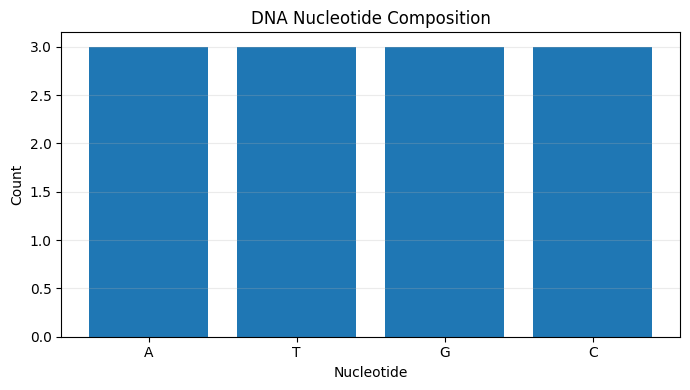


CSV file: /content/bioseq_ai_reports/BioSeqAI_Nucleotide_Composition.csv
TXT report: /content/bioseq_ai_reports/BioSeqAI_Analysis_Report.txt


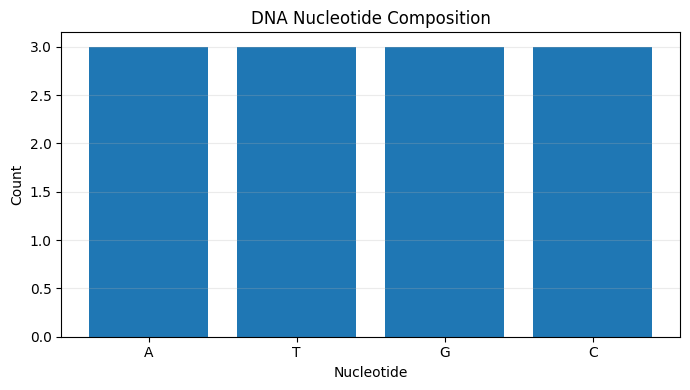

In [ ]:
test_sequence = "ATGCGCTAATGC"

summary, table, fig, csv_file, txt_file = create_bioseq_report(
    test_sequence
)

print(summary)
display(table)
display(fig)

print("\nCSV file:", csv_file)
print("TXT report:", txt_file)

In [ ]:
from google.colab import files

files.download(csv_file)
files.download(txt_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# STEP 43 — BioSeq AI Dashboard with Download Buttons

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path
from datetime import datetime


def analyze_and_export(sequence):
    if not isinstance(sequence, str) or not sequence.strip():
        return (
            "⚠️ Please enter a DNA sequence.",
            pd.DataFrame(),
            None,
            None,
            None
        )

    sequence = "".join(sequence.upper().split())

    valid, result = validate_dna(sequence)

    if not valid:
        return (
            f"⚠️ Invalid DNA sequence: {result}",
            pd.DataFrame(),
            None,
            None,
            None
        )

    counts = Counter(sequence)
    length = len(sequence)

    gc_percent = (
        (counts["G"] + counts["C"]) / length
    ) * 100

    at_percent = 100 - gc_percent

    table = pd.DataFrame({
        "Nucleotide": ["A", "T", "G", "C"],
        "Count": [
            counts["A"], counts["T"],
            counts["G"], counts["C"]
        ],
        "Percentage (%)": [
            round(counts[b] / length * 100, 2)
            for b in ["A", "T", "G", "C"]
        ]
    })

    timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

    summary = (
        "🧬 BioSeq AI — DNA Analysis Report\n"
        "====================================\n"
        f"Generated: {timestamp}\n"
        f"Sequence length: {length} bp\n"
        f"GC content: {gc_percent:.2f}%\n"
        f"AT content: {at_percent:.2f}%\n\n"
        f"A count: {counts['A']}\n"
        f"T count: {counts['T']}\n"
        f"G count: {counts['G']}\n"
        f"C count: {counts['C']}\n\n"
        "Educational analysis only; not a clinical diagnostic report."
    )

    output_dir = Path("/content/bioseq_ai_reports")
    output_dir.mkdir(parents=True, exist_ok=True)

    csv_path = output_dir / "BioSeqAI_Composition.csv"
    txt_path = output_dir / "BioSeqAI_Report.txt"

    table.to_csv(csv_path, index=False)
    txt_path.write_text(summary, encoding="utf-8")

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(
        ["A", "T", "G", "C"],
        [counts["A"], counts["T"], counts["G"], counts["C"]]
    )
    ax.set_title("DNA Nucleotide Composition")
    ax.set_ylabel("Count")
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()

    return summary, table, fig, str(csv_path), str(txt_path)


with gr.Blocks(
    title="BioSeq AI — Report Studio",
    theme=gr.themes.Soft()
) as bioseq_report_app:

    gr.Markdown("""
    # 🧬 BioSeq AI — Report Studio
    Analyze a DNA sequence, visualize its nucleotide composition,
    and export your results.

    *Educational prototype; not a clinical diagnostic tool.*
    """)

    sequence_input = gr.Textbox(
        label="DNA Sequence",
        placeholder="Example: ATGCGCTAATGC",
        lines=4
    )

    with gr.Row():
        analyze_button = gr.Button(
            "🚀 Analyze & Generate Reports",
            variant="primary"
        )
        example_button = gr.Button("✨ Load Example")

    summary_output = gr.Textbox(
        label="Analysis Summary",
        lines=9,
        interactive=False
    )

    table_output = gr.Dataframe(
        label="Nucleotide Composition",
        interactive=False
    )

    plot_output = gr.Plot(label="Composition Chart")

    gr.Markdown("## 📥 Download Your Reports")

    with gr.Row():
        csv_output = gr.File(label="Download CSV")
        txt_output = gr.File(label="Download TXT Report")

    analyze_button.click(
        fn=analyze_and_export,
        inputs=[sequence_input],
        outputs=[
            summary_output,
            table_output,
            plot_output,
            csv_output,
            txt_output
        ]
    )

    example_button.click(
        fn=lambda: "ATGCGCTAATGC",
        inputs=[],
        outputs=[sequence_input]
    )

print("✅ Step 43 dashboard created successfully!")

/tmp/ipykernel_416/2259645468.py:93: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


✅ Step 43 dashboard created successfully!


In [ ]:
bioseq_report_app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0bcc2d31c78c31c397.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# STEP 44 — Interactive DNA Visualization

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter


def interactive_dna_visualizer(sequence):
    # Check empty input
    if not isinstance(sequence, str) or not sequence.strip():
        return "⚠️ Please enter a DNA sequence.", pd.DataFrame(), None

    # Clean sequence
    sequence = "".join(sequence.upper().split())

    # Validate DNA
    valid, result = validate_dna(sequence)

    if not valid:
        return f"⚠️ Invalid sequence: {result}", pd.DataFrame(), None

    length = len(sequence)
    counts = Counter(sequence)

    gc_count = counts["G"] + counts["C"]
    at_count = counts["A"] + counts["T"]

    gc_percent = gc_count / length * 100
    at_percent = at_count / length * 100

    summary = f"""
## 🧬 DNA Sequence Analysis

- **Sequence length:** {length} bp
- **GC content:** {gc_percent:.2f}%
- **AT content:** {at_percent:.2f}%
- **GC count:** {gc_count}
- **AT count:** {at_count}

*Educational analysis only. GC content alone does not determine gene function.*
"""

    # Create table
    table = pd.DataFrame({
        "Nucleotide": ["A", "T", "G", "C"],
        "Count": [counts["A"], counts["T"], counts["G"], counts["C"]],
        "Percentage (%)": [
            round(counts[b] / length * 100, 2)
            for b in ["A", "T", "G", "C"]
        ]
    })

    # Create visualization
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].bar(
        ["A", "T", "G", "C"],
        [counts["A"], counts["T"], counts["G"], counts["C"]]
    )
    axes[0].set_title("Nucleotide Counts")
    axes[0].set_ylabel("Count")

    axes[1].pie(
        [counts["A"], counts["T"], counts["G"], counts["C"]],
        labels=["A", "T", "G", "C"],
        autopct="%1.1f%%"
    )
    axes[1].set_title("Nucleotide Distribution")

    fig.tight_layout()

    return summary, table, fig


with gr.Blocks(
    title="BioSeq AI — DNA Visualizer",
    theme=gr.themes.Soft()
) as bioseq_visualizer_app:

    gr.Markdown("""
    # 🧬 BioSeq AI — DNA Visualizer
    ### Explore your sequence through data and charts
    """)

    sequence_box = gr.Textbox(
        label="Enter DNA Sequence",
        placeholder="Example: ATGCGCTAATGC",
        lines=4
    )

    with gr.Row():
        analyze_btn = gr.Button(
            "📊 Visualize DNA",
            variant="primary"
        )
        example_btn = gr.Button("✨ Load Example")

    summary_box = gr.Markdown(label="Analysis Summary")
    table_box = gr.Dataframe(
        label="Nucleotide Statistics",
        interactive=False
    )
    plot_box = gr.Plot(label="DNA Visualizations")

    analyze_btn.click(
        fn=interactive_dna_visualizer,
        inputs=[sequence_box],
        outputs=[summary_box, table_box, plot_box]
    )

    example_btn.click(
        fn=lambda: "ATGCGCTAATGC",
        inputs=[],
        outputs=[sequence_box]
    )

print("✅ Step 44 dashboard created!")

/tmp/ipykernel_416/2859921215.py:76: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


✅ Step 44 dashboard created!


In [ ]:
bioseq_visualizer_app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://83d55f8d171fa83837.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# STEP 45 — FASTA Upload and Batch DNA Analysis

import gradio as gr
import pandas as pd
from Bio import SeqIO
from pathlib import Path
from collections import Counter
import tempfile


def analyze_fasta_batch(file_path):

    if not file_path:
        return (
            "⚠️ Please upload a FASTA file.",
            pd.DataFrame(),
            None
        )

    records = []
    errors = []

    try:
        for record in SeqIO.parse(file_path, "fasta"):

            sequence = "".join(str(record.seq).upper().split())

            if not sequence:
                errors.append(f"{record.id}: Empty sequence.")
                continue

            # FASTA DNA sequences may contain ambiguous bases.
            # Report them rather than silently treating them as A/T/G/C.
            valid_bases = set("ATGCN")

            if not set(sequence).issubset(valid_bases):
                errors.append(
                    f"{record.id}: Contains unsupported characters."
                )
                continue

            length = len(sequence)
            counts = Counter(sequence)

            gc_count = counts["G"] + counts["C"]
            atgc_count = sum(counts[b] for b in "ATGC")

            gc_percent = (
                gc_count / atgc_count * 100
                if atgc_count else None
            )

            records.append({
                "Sequence ID": record.id,
                "Description": record.description,
                "Length (bp)": length,
                "A Count": counts["A"],
                "T Count": counts["T"],
                "G Count": counts["G"],
                "C Count": counts["C"],
                "N Count": counts["N"],
                "GC Content (%)": (
                    round(gc_percent, 2)
                    if gc_percent is not None else None
                )
            })

    except Exception as exc:
        return (
            f"⚠️ Could not read the FASTA file: {exc}",
            pd.DataFrame(),
            None
        )

    if not records:
        message = "⚠️ No valid DNA sequences were found."

        if errors:
            message += "\n\nSkipped records:\n" + "\n".join(errors)

        return message, pd.DataFrame(), None

    df_results = pd.DataFrame(records)

    # Create a downloadable CSV report
    output_dir = Path(tempfile.mkdtemp(prefix="bioseq_batch_"))
    csv_path = output_dir / "BioSeqAI_Batch_Results.csv"

    df_results.to_csv(csv_path, index=False)

    message = (
        "✅ Batch analysis completed!\n\n"
        f"Sequences analyzed: {len(records)}\n"
        f"Total bases: {df_results['Length (bp)'].sum()}\n"
        f"CSV report: {csv_path.name}\n"
        "\nGC content is calculated over A, T, G and C bases only. "
        "Ambiguous N bases are excluded from that denominator."
    )

    if errors:
        message += (
            "\n\n⚠️ Skipped records:\n"
            + "\n".join(errors)
        )

    return message, df_results, str(csv_path)


with gr.Blocks(
    title="BioSeq AI — Batch FASTA Analyzer",
    theme=gr.themes.Soft()
) as bioseq_batch_app:

    gr.Markdown("""
    # 🧬 BioSeq AI — Batch FASTA Analyzer

    Upload a FASTA file containing one or more DNA sequences.
    Analyze sequence lengths, nucleotide counts and GC content.

    **Note:** This tool performs basic sequence statistics only.
    It does not establish biological function or clinical significance.
    """)

    fasta_input = gr.File(
        label="Upload FASTA file",
        file_types=[".fasta", ".fa", ".fna"],
        type="filepath"
    )

    analyze_button = gr.Button(
        "🚀 Analyze All Sequences",
        variant="primary"
    )

    summary_output = gr.Textbox(
        label="Batch Analysis Summary",
        lines=8,
        interactive=False
    )

    table_output = gr.Dataframe(
        label="Sequence Results",
        interactive=False
    )

    csv_output = gr.File(label="Download CSV Results")

    analyze_button.click(
        fn=analyze_fasta_batch,
        inputs=[fasta_input],
        outputs=[
            summary_output,
            table_output,
            csv_output
        ]
    )

print("✅ Step 45 dashboard created successfully!")

/tmp/ipykernel_416/3439102771.py:109: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


✅ Step 45 dashboard created successfully!


In [ ]:
bioseq_batch_app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7921560641e8abdddc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
sample_fasta = """>Sequence_1
ATGCGCTAATGC
>Sequence_2
ATATGCGCGCTA
>Sequence_3
GGCCATAT
"""

sample_path = "/content/sample_bioseq.fasta"

with open(sample_path, "w") as f:
    f.write(sample_fasta)

print("✅ Sample FASTA created:", sample_path)

✅ Sample FASTA created: /content/sample_bioseq.fasta


In [ ]:
# STEP 46 — FASTA Comparison Dashboard with Reports

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from Bio import SeqIO
from pathlib import Path
from collections import Counter
import tempfile
from datetime import datetime


def analyze_fasta_comparison(file_path):

    if not file_path:
        return (
            "⚠️ Please upload a FASTA file.",
            pd.DataFrame(),
            None,
            None,
            None
        )

    records = []
    skipped = []

    try:
        for record in SeqIO.parse(file_path, "fasta"):

            sequence = "".join(str(record.seq).upper().split())

            if not sequence:
                skipped.append(f"{record.id}: Empty sequence")
                continue

            # Allow standard DNA bases and ambiguous N
            if not set(sequence).issubset(set("ATGCN")):
                skipped.append(
                    f"{record.id}: Unsupported characters"
                )
                continue

            counts = Counter(sequence)
            length = len(sequence)
            atgc_count = sum(counts[b] for b in "ATGC")

            gc_percent = (
                (counts["G"] + counts["C"]) / atgc_count * 100
                if atgc_count > 0 else None
            )

            records.append({
                "Sequence ID": record.id,
                "Length (bp)": length,
                "A Count": counts["A"],
                "T Count": counts["T"],
                "G Count": counts["G"],
                "C Count": counts["C"],
                "N Count": counts["N"],
                "GC Content (%)": (
                    round(gc_percent, 2)
                    if gc_percent is not None else None
                )
            })

    except Exception as exc:
        return (
            f"⚠️ FASTA reading error: {exc}",
            pd.DataFrame(),
            None,
            None,
            None
        )

    if not records:
        message = "⚠️ No valid DNA sequences were found."

        if skipped:
            message += "\n\nSkipped:\n" + "\n".join(skipped)

        return message, pd.DataFrame(), None, None, None

    results = pd.DataFrame(records)

    # Create separate output folder for this analysis
    output_dir = Path(tempfile.mkdtemp(prefix="bioseq_comparison_"))

    csv_path = output_dir / "BioSeqAI_GC_Comparison.csv"
    txt_path = output_dir / "BioSeqAI_GC_Report.txt"

    # Export CSV
    results.to_csv(csv_path, index=False)

    # Generate comparison chart
    plot_data = results.dropna(subset=["GC Content (%)"])

    fig = None

    if not plot_data.empty:
        fig, ax = plt.subplots(figsize=(10, 5))

        ax.bar(
            plot_data["Sequence ID"],
            plot_data["GC Content (%)"]
        )

        ax.set_title("GC Content Comparison")
        ax.set_xlabel("DNA Sequence")
        ax.set_ylabel("GC Content (%)")
        ax.set_ylim(0, 100)
        ax.tick_params(axis="x", rotation=35)
        ax.grid(axis="y", alpha=0.25)

        fig.tight_layout()

    # Build report
    average_gc = (
        plot_data["GC Content (%)"].mean()
        if not plot_data.empty else None
    )

    report_lines = [
        "BioSeq AI — FASTA Comparison Report",
        "=" * 40,
        f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
        f"Sequences analyzed: {len(results)}",
        f"Total bases: {results['Length (bp)'].sum()}",
    ]

    if average_gc is not None:
        report_lines.append(
            f"Average sequence GC content: {average_gc:.2f}%"
        )
    else:
        report_lines.append(
            "Average GC content: unavailable"
        )

    report_lines.extend([
        "",
        "Individual sequence results:",
        results.to_string(index=False),
        "",
        "GC content is calculated using A, T, G and C bases only.",
        "Ambiguous N bases are excluded from the GC denominator.",
        "This report describes sequence composition, not gene function."
    ])

    if skipped:
        report_lines.extend([
            "",
            "Skipped records:",
            *skipped
        ])

    txt_path.write_text(
        "\n".join(report_lines),
        encoding="utf-8"
    )

    summary = (
        "✅ FASTA comparison completed!\n\n"
        f"Sequences analyzed: {len(results)}\n"
        f"Total bases: {results['Length (bp)'].sum()}\n"
        f"Average GC content: "
        f"{average_gc:.2f}%\n"
        if average_gc is not None
        else
        "✅ FASTA comparison completed!\n\n"
        f"Sequences analyzed: {len(results)}\n"
        f"Total bases: {results['Length (bp)'].sum()}\n"
        "Average GC content: unavailable\n"
    )

    if skipped:
        summary += "\n⚠️ Skipped records:\n" + "\n".join(skipped)

    return (
        summary,
        results,
        fig,
        str(csv_path),
        str(txt_path)
    )


with gr.Blocks(
    title="BioSeq AI — FASTA Comparison",
    theme=gr.themes.Soft()
) as bioseq_comparison_app:

    gr.Markdown("""
    # 🧬 BioSeq AI — FASTA Comparison Studio

    Upload a FASTA file to compare sequence lengths and GC content.

    - 📊 GC content comparison chart
    - 📋 Sequence statistics table
    - 📥 Downloadable CSV and TXT reports

    **Educational prototype:** GC content alone cannot establish
    biological function or clinical significance.
    """)

    fasta_file = gr.File(
        label="Upload FASTA file",
        file_types=[".fasta", ".fa", ".fna"],
        type="filepath"
    )

    run_button = gr.Button(
        "🚀 Analyze & Compare",
        variant="primary"
    )

    summary_output = gr.Textbox(
        label="Analysis Summary",
        lines=8,
        interactive=False
    )

    table_output = gr.Dataframe(
        label="Sequence Statistics",
        interactive=False
    )

    chart_output = gr.Plot(
        label="GC Content Comparison"
    )

    with gr.Row():
        csv_download = gr.File(label="📥 Download CSV")
        txt_download = gr.File(label="📥 Download TXT Report")

    run_button.click(
        fn=analyze_fasta_comparison,
        inputs=[fasta_file],
        outputs=[
            summary_output,
            table_output,
            chart_output,
            csv_download,
            txt_download
        ]
    )

print("✅ Step 46 dashboard created successfully!")

/tmp/ipykernel_416/2607349419.py:187: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


✅ Step 46 dashboard created successfully!


In [ ]:
bioseq_comparison_app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c2e5b1a5d253276e6b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# STEP 47 — DNA Sequence Similarity Comparison Dashboard

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from Bio.Align import PairwiseAligner
from pathlib import Path
import tempfile
from datetime import datetime


def compare_dna_dashboard(reference, query):

    # Validate input
    if not reference or not query:
        return (
            "⚠️ Please enter both DNA sequences.",
            pd.DataFrame(),
            None,
            None,
            None
        )

    reference = "".join(reference.upper().split())
    query = "".join(query.upper().split())

    valid_bases = set("ATGC")

    if not reference or not query:
        return (
            "⚠️ Both sequences must contain DNA bases.",
            pd.DataFrame(),
            None,
            None,
            None
        )

    if not set(reference).issubset(valid_bases):
        return (
            "⚠️ Reference sequence must contain only A, T, G and C.",
            pd.DataFrame(),
            None,
            None,
            None
        )

    if not set(query).issubset(valid_bases):
        return (
            "⚠️ Query sequence must contain only A, T, G and C.",
            pd.DataFrame(),
            None,
            None,
            None
        )

    # Configure global pairwise alignment
    aligner = PairwiseAligner()
    aligner.mode = "global"
    aligner.match_score = 2
    aligner.mismatch_score = -1
    aligner.open_gap_score = -2
    aligner.extend_gap_score = -0.5

    alignment = aligner.align(reference, query)[0]

    # Compare aligned positions using alignment coordinates
    coordinates = alignment.coordinates

    matches = 0
    mismatches = 0
    insertions = 0
    deletions = 0
    aligned_columns = 0
    comparison_rows = []

    for i in range(coordinates.shape[1] - 1):

        r0 = int(coordinates[0, i])
        r1 = int(coordinates[0, i + 1])
        q0 = int(coordinates[1, i])
        q1 = int(coordinates[1, i + 1])

        r_len = r1 - r0
        q_len = q1 - q0

        if r_len > 0 and q_len > 0:
            # Aligned bases
            for j in range(min(r_len, q_len)):
                ref_base = reference[r0 + j]
                query_base = query[q0 + j]

                aligned_columns += 1

                if ref_base == query_base:
                    matches += 1
                    status = "Match"
                else:
                    mismatches += 1
                    status = "Substitution"

                comparison_rows.append({
                    "Reference Position": r0 + j + 1,
                    "Reference Base": ref_base,
                    "Query Position": q0 + j + 1,
                    "Query Base": query_base,
                    "Status": status
                })

        elif r_len > 0:
            # Bases present in reference but absent from query
            deletions += r_len

            for j in range(r_len):
                comparison_rows.append({
                    "Reference Position": r0 + j + 1,
                    "Reference Base": reference[r0 + j],
                    "Query Position": None,
                    "Query Base": "-",
                    "Status": "Deletion in query"
                })

        elif q_len > 0:
            # Bases present in query but absent from reference
            insertions += q_len

            for j in range(q_len):
                comparison_rows.append({
                    "Reference Position": None,
                    "Reference Base": "-",
                    "Query Position": q0 + j + 1,
                    "Query Base": query[q0 + j],
                    "Status": "Insertion in query"
                })

    total_alignment_columns = matches + mismatches + insertions + deletions

    identity = (
        matches / total_alignment_columns * 100
        if total_alignment_columns else 0
    )

    results = pd.DataFrame(comparison_rows)

    # Summary
    summary = f"""
DNA SEQUENCE COMPARISON
=======================

Reference length: {len(reference)} bp
Query length: {len(query)} bp

Matching bases: {matches}
Mismatches: {mismatches}
Insertions in query: {insertions}
Deletions in query: {deletions}

Alignment columns: {total_alignment_columns}
Alignment identity: {identity:.2f}%

Method: Global pairwise alignment
Match score: +2
Mismatch score: -1
Gap opening score: -2
Gap extension score: -0.5

Note: Alignment identity depends on the alignment method and scoring
parameters. It does not establish biological function or clinical significance.
"""

    # Plot event counts
    labels = [
        "Matches",
        "Mismatches",
        "Insertions",
        "Deletions"
    ]

    values = [
        matches,
        mismatches,
        insertions,
        deletions
    ]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(labels, values)
    ax.set_title("DNA Alignment Comparison")
    ax.set_ylabel("Number of bases")
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()

    # Export reports
    output_dir = Path(tempfile.mkdtemp(prefix="bioseq_alignment_"))

    csv_path = output_dir / "BioSeqAI_Alignment_Details.csv"
    txt_path = output_dir / "BioSeqAI_Alignment_Report.txt"

    results.to_csv(csv_path, index=False)

    txt_path.write_text(
        summary + "\n\nPOSITION-BY-POSITION DETAILS\n"
        + results.to_string(index=False),
        encoding="utf-8"
    )

    return (
        summary,
        results,
        fig,
        str(csv_path),
        str(txt_path)
    )


with gr.Blocks(
    title="BioSeq AI — DNA Comparison",
    theme=gr.themes.Soft()
) as bioseq_alignment_app:

    gr.Markdown("""
    # 🧬 BioSeq AI — DNA Sequence Comparison

    Compare two DNA sequences using global pairwise alignment.

    - 🔬 Identify matching and differing aligned bases
    - 📊 Visualize alignment event counts
    - 📥 Download detailed CSV and TXT reports

    **Educational tool only:** results depend on alignment settings and
    do not prove biological or clinical significance.
    """)

    with gr.Row():
        reference_input = gr.Textbox(
            label="Reference DNA Sequence",
            placeholder="Example: ATGCGCTA",
            lines=4
        )

        query_input = gr.Textbox(
            label="Query DNA Sequence",
            placeholder="Example: ATGAGCTA",
            lines=4
        )

    with gr.Row():
        compare_button = gr.Button(
            "🔍 Compare Sequences",
            variant="primary"
        )

        example_button = gr.Button("✨ Load Example")

    summary_output = gr.Textbox(
        label="Comparison Summary",
        lines=16,
        interactive=False
    )

    details_output = gr.Dataframe(
        label="Alignment Details",
        interactive=False
    )

    plot_output = gr.Plot(label="Comparison Chart")

    with gr.Row():
        csv_output = gr.File(label="Download CSV")
        txt_output = gr.File(label="Download TXT Report")

    compare_button.click(
        fn=compare_dna_dashboard,
        inputs=[reference_input, query_input],
        outputs=[
            summary_output,
            details_output,
            plot_output,
            csv_output,
            txt_output
        ]
    )

    example_button.click(
        fn=lambda: ("ATGCGCTA", "ATGAGCTA"),
        inputs=[],
        outputs=[reference_input, query_input]
    )

print("✅ Step 47 dashboard created successfully!")

/tmp/ipykernel_416/482727164.py:215: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


✅ Step 47 dashboard created successfully!


In [ ]:
bioseq_alignment_app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e8f7cd841a7c63943e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# STEP 48 — DNA Mutation Analysis Dashboard

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from Bio.Align import PairwiseAligner
from pathlib import Path
import tempfile
from datetime import datetime


def mutation_analysis_dashboard(reference, mutated):

    # 1. Validate inputs
    if not reference or not mutated:
        return (
            "⚠️ Enter both reference and mutated DNA sequences.",
            pd.DataFrame(),
            None,
            None,
            None
        )

    reference = "".join(reference.upper().split())
    mutated = "".join(mutated.upper().split())

    valid_bases = set("ATGC")

    if not reference or not mutated:
        return (
            "⚠️ Both sequences must contain DNA bases.",
            pd.DataFrame(),
            None,
            None,
            None
        )

    if not set(reference).issubset(valid_bases):
        return (
            "⚠️ Reference must contain only A, T, G and C.",
            pd.DataFrame(),
            None,
            None,
            None
        )

    if not set(mutated).issubset(valid_bases):
        return (
            "⚠️ Mutated sequence must contain only A, T, G and C.",
            pd.DataFrame(),
            None,
            None,
            None
        )

    # 2. Configure global alignment
    aligner = PairwiseAligner()
    aligner.mode = "global"
    aligner.match_score = 2
    aligner.mismatch_score = -1
    aligner.open_gap_score = -2
    aligner.extend_gap_score = -0.5

    alignment = aligner.align(reference, mutated)[0]
    coordinates = alignment.coordinates

    mutations = []

    substitutions = 0
    insertions = 0
    deletions = 0

    # 3. Extract alignment events
    for i in range(coordinates.shape[1] - 1):

        r0 = int(coordinates[0, i])
        r1 = int(coordinates[0, i + 1])
        m0 = int(coordinates[1, i])
        m1 = int(coordinates[1, i + 1])

        r_len = r1 - r0
        m_len = m1 - m0

        if r_len > 0 and m_len > 0:

            for j in range(min(r_len, m_len)):

                ref_base = reference[r0 + j]
                mut_base = mutated[m0 + j]

                if ref_base != mut_base:
                    substitutions += 1

                    mutations.append({
                        "Mutation Type": "Substitution",
                        "Reference Position": r0 + j + 1,
                        "Reference Base": ref_base,
                        "Mutated Position": m0 + j + 1,
                        "Mutated Base": mut_base
                    })

        elif r_len > 0:

            for j in range(r_len):
                deletions += 1

                mutations.append({
                    "Mutation Type": "Deletion",
                    "Reference Position": r0 + j + 1,
                    "Reference Base": reference[r0 + j],
                    "Mutated Position": None,
                    "Mutated Base": "-"
                })

        elif m_len > 0:

            for j in range(m_len):
                insertions += 1

                mutations.append({
                    "Mutation Type": "Insertion",
                    "Reference Position": None,
                    "Reference Base": "-",
                    "Mutated Position": m0 + j + 1,
                    "Mutated Base": mutated[m0 + j]
                })

    # 4. Build results table
    columns = [
        "Mutation Type",
        "Reference Position",
        "Reference Base",
        "Mutated Position",
        "Mutated Base"
    ]

    results = pd.DataFrame(mutations, columns=columns)

    if results.empty:
        results = pd.DataFrame(
            columns=columns
        )

    # 5. Summary
    total_events = substitutions + insertions + deletions

    summary = f"""
🧬 DNA MUTATION ANALYSIS
================================

Reference length: {len(reference)} bp
Mutated sequence length: {len(mutated)} bp

Substitutions: {substitutions}
Inserted bases: {insertions}
Deleted bases: {deletions}

Total alignment events: {total_events}

Method: Global pairwise alignment
Match score: +2
Mismatch score: -1
Gap opening score: -2
Gap extension score: -0.5

Important:
These are alignment-based candidate differences.
Repeated sequences can produce multiple equally good alignments,
so exact event positions may depend on alignment settings.
This analysis alone does not establish biological or clinical impact.
"""

    # 6. Plot
    labels = ["Substitutions", "Insertions", "Deletions"]
    values = [substitutions, insertions, deletions]

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(labels, values)
    ax.set_title("DNA Alignment Differences")
    ax.set_ylabel("Number of bases")
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()

    # 7. Export files
    output_dir = Path(tempfile.mkdtemp(prefix="bioseq_mutations_"))

    csv_path = output_dir / "BioSeqAI_Mutation_Details.csv"
    txt_path = output_dir / "BioSeqAI_Mutation_Report.txt"

    results.to_csv(csv_path, index=False)

    report = (
        summary
        + "\n\nMUTATION DETAILS\n"
        + results.to_string(index=False)
    )

    txt_path.write_text(report, encoding="utf-8")

    return (
        summary,
        results,
        fig,
        str(csv_path),
        str(txt_path)
    )


# 8. Create Gradio interface
with gr.Blocks(
    title="BioSeq AI — Mutation Analysis",
    theme=gr.themes.Soft()
) as bioseq_mutation_app:

    gr.Markdown("""
    # 🧬 BioSeq AI — Mutation Analysis Studio

    Compare reference and mutated DNA sequences.

    - 🔍 Identify alignment-based sequence differences
    - 📊 Visualize substitutions, insertions and deletions
    - 📥 Download CSV and TXT reports

    **Educational prototype, not a clinical diagnostic tool.**
    """)

    with gr.Row():
        reference_input = gr.Textbox(
            label="Reference DNA",
            placeholder="ATGCGCTA",
            lines=4
        )

        mutated_input = gr.Textbox(
            label="Mutated DNA",
            placeholder="ATGAGCTA",
            lines=4
        )

    with gr.Row():
        analyze_button = gr.Button(
            "🔬 Analyze Differences",
            variant="primary"
        )

        example_button = gr.Button("✨ Load Example")

    summary_output = gr.Textbox(
        label="Mutation Summary",
        lines=17,
        interactive=False
    )

    table_output = gr.Dataframe(
        label="Detected Differences",
        interactive=False
    )

    chart_output = gr.Plot(
        label="Mutation Event Chart"
    )

    with gr.Row():
        csv_output = gr.File(label="Download CSV")
        txt_output = gr.File(label="Download TXT Report")

    analyze_button.click(
        fn=mutation_analysis_dashboard,
        inputs=[reference_input, mutated_input],
        outputs=[
            summary_output,
            table_output,
            chart_output,
            csv_output,
            txt_output
        ]
    )

    example_button.click(
        fn=lambda: ("ATGCGCTA", "ATGAGCTA"),
        inputs=[],
        outputs=[reference_input, mutated_input]
    )

print("✅ Step 48 dashboard created successfully!")

/tmp/ipykernel_416/454878968.py:210: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


✅ Step 48 dashboard created successfully!


In [ ]:
bioseq_mutation_app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://42340a39e3b5e669dc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# STEP 49 — ORF Analysis Dashboard

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from Bio.Seq import Seq
from pathlib import Path
import tempfile


def analyze_orfs_dashboard(sequence, min_protein_length):

    # Validate input
    if not sequence or not sequence.strip():
        return (
            "⚠️ Please enter a DNA sequence.",
            pd.DataFrame(),
            None,
            None
        )

    sequence = "".join(sequence.upper().split())

    if not set(sequence).issubset(set("ATGC")):
        return (
            "⚠️ Use only A, T, G and C. Ambiguous bases are not supported.",
            pd.DataFrame(),
            None,
            None
        )

    if len(sequence) < 3:
        return (
            "⚠️ Please enter a sequence of at least 3 bases.",
            pd.DataFrame(),
            None,
            None
        )

    min_protein_length = int(min_protein_length)
    if min_protein_length < 1:
        min_protein_length = 1

    stop_codons = {"TAA", "TAG", "TGA"}
    start_codon = "ATG"

    results = []

    # Scan the three forward and three reverse reading frames
    strands = [
        ("+", sequence),
        ("-", str(Seq(sequence).reverse_complement()))
    ]

    for strand, strand_sequence in strands:

        for frame in range(3):

            start_positions = []

            for pos in range(frame, len(strand_sequence) - 2, 3):

                codon = strand_sequence[pos:pos + 3]

                if codon == start_codon:
                    start_positions.append(pos)

                elif codon in stop_codons and start_positions:

                    # Record candidate ORFs from each pending start
                    for start_pos in start_positions:

                        nucleotide_length = pos + 3 - start_pos
                        protein_length = nucleotide_length // 3 - 1

                        if protein_length < min_protein_length:
                            continue

                        if strand == "+":
                            genomic_start = start_pos + 1
                            genomic_end = pos + 3
                        else:
                            genomic_start = (
                                len(sequence) - (pos + 3) + 1
                            )
                            genomic_end = len(sequence) - start_pos

                        orf_dna = strand_sequence[start_pos:pos + 3]
                        protein = str(Seq(orf_dna).translate())

                        results.append({
                            "Strand": strand,
                            "Frame": frame + 1,
                            "Start (1-based)": genomic_start,
                            "End (1-based)": genomic_end,
                            "Length (bp)": nucleotide_length,
                            "Protein Length (aa)": protein_length,
                            "Start Codon": "ATG",
                            "Stop Codon": codon,
                            "Protein Sequence": protein
                        })

                    # A stop codon closes all currently open starts
                    start_positions = []

    columns = [
        "Strand",
        "Frame",
        "Start (1-based)",
        "End (1-based)",
        "Length (bp)",
        "Protein Length (aa)",
        "Start Codon",
        "Stop Codon",
        "Protein Sequence"
    ]

    df_results = pd.DataFrame(results, columns=columns)

    if df_results.empty:
        summary = (
            "No ORFs matching the selected minimum protein length "
            "were detected.\n\n"
            "This does not prove that the sequence contains no genes."
        )
        return summary, df_results, None, None

    # Summary
    summary = (
        "✅ ORF scan completed!\n\n"
        f"Sequence length: {len(sequence)} bp\n"
        f"Candidate ORFs detected: {len(df_results)}\n"
        f"Minimum protein length: {min_protein_length} amino acids\n"
        f"Forward-strand candidates: {(df_results['Strand'] == '+').sum()}\n"
        f"Reverse-strand candidates: {(df_results['Strand'] == '-').sum()}\n\n"
        "ORFs are computational candidates, not proof of functional genes "
        "or proteins. This simple scanner uses ATG start codons and the "
        "standard genetic code."
    )

    # Plot ORF lengths
    fig, ax = plt.subplots(figsize=(8, 4))

    ax.bar(
        range(1, len(df_results) + 1),
        df_results["Length (bp)"]
    )

    ax.set_title("Candidate ORF Lengths")
    ax.set_xlabel("ORF number")
    ax.set_ylabel("Length (bp)")
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()

    # Export CSV
    output_dir = Path(tempfile.mkdtemp(prefix="bioseq_orfs_"))
    csv_path = output_dir / "BioSeqAI_ORF_Results.csv"

    df_results.to_csv(csv_path, index=False)

    return summary, df_results, fig, str(csv_path)


with gr.Blocks(
    title="BioSeq AI — ORF Analyzer",
    theme=gr.themes.Soft()
) as bioseq_orf_app:

    gr.Markdown("""
    # 🧬 BioSeq AI — ORF Analyzer

    Scan DNA sequences in all six reading frames for candidate ORFs.

    - Forward and reverse strands
    - Candidate start and stop positions
    - ORF lengths and translated sequences
    - CSV export

    **Educational prototype:** candidate ORFs do not necessarily
    represent functional genes or proteins.
    """)

    sequence_input = gr.Textbox(
        label="DNA Sequence",
        placeholder="Example: ATGAAATAA",
        lines=4
    )

    min_length_input = gr.Slider(
        minimum=1,
        maximum=100,
        value=1,
        step=1,
        label="Minimum protein length (amino acids)"
    )

    with gr.Row():
        analyze_button = gr.Button(
            "🔬 Scan ORFs",
            variant="primary"
        )
        example_button = gr.Button("✨ Load Example")

    summary_output = gr.Textbox(
        label="ORF Analysis Summary",
        lines=8,
        interactive=False
    )

    results_output = gr.Dataframe(
        label="Candidate ORFs",
        interactive=False
    )

    chart_output = gr.Plot(label="ORF Length Chart")

    csv_output = gr.File(label="Download ORF Results")

    analyze_button.click(
        fn=analyze_orfs_dashboard,
        inputs=[sequence_input, min_length_input],
        outputs=[
            summary_output,
            results_output,
            chart_output,
            csv_output
        ]
    )

    example_button.click(
        fn=lambda: "ATGAAATAA",
        inputs=[],
        outputs=[sequence_input]
    )

print("✅ Step 49 dashboard created successfully!")

/tmp/ipykernel_416/3632827916.py:165: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


✅ Step 49 dashboard created successfully!


In [ ]:
bioseq_orf_app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e1a46ec54e6e798b61.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# STEP 50 — Protein Sequence Analysis Dashboard (Corrected)

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from Bio.SeqUtils.ProtParam import ProteinAnalysis
from pathlib import Path
import tempfile


def analyze_protein_dashboard(protein_sequence):

    # Validate input
    if not protein_sequence or not protein_sequence.strip():
        return (
            "⚠️ Please enter a protein sequence.",
            pd.DataFrame(),
            None,
            None,
            None
        )

    protein_sequence = "".join(
        protein_sequence.upper().split()
    )

    # Standard amino acids supported by this analysis
    valid_amino_acids = set("ACDEFGHIKLMNPQRSTVWY")

    if not protein_sequence:
        return (
            "⚠️ Protein sequence cannot be empty.",
            pd.DataFrame(),
            None,
            None,
            None
        )

    invalid = set(protein_sequence) - valid_amino_acids

    if invalid:
        return (
            "⚠️ Unsupported amino acid symbols: "
            + ", ".join(sorted(invalid))
            + "\nUse the 20 standard one-letter amino acid codes. "
              "Remove stop symbols (*) before analysis.",
            pd.DataFrame(),
            None,
            None,
            None
        )

    # Analyze protein
    protein = ProteinAnalysis(protein_sequence)

    length = len(protein_sequence)
    molecular_weight = protein.molecular_weight()
    isoelectric_point = protein.isoelectric_point()
    gravy = protein.gravy()
    aromaticity = protein.aromaticity()

    amino_acid_counts = {
        aa: protein_sequence.count(aa)
        for aa in sorted(valid_amino_acids)
    }

    # Create amino acid composition table
    composition = pd.DataFrame({
        "Amino Acid": list(amino_acid_counts.keys()),
        "Count": list(amino_acid_counts.values())
    })

    composition["Percentage (%)"] = (
        composition["Count"] / length * 100
    ).round(2)

    # Display only amino acids present in the sequence
    composition = composition[
        composition["Count"] > 0
    ].reset_index(drop=True)

    summary = f"""
🧬 PROTEIN ANALYSIS REPORT
==========================

Sequence length: {length} amino acids
Molecular weight: {molecular_weight:.2f} Da
Predicted isoelectric point (pI): {isoelectric_point:.2f}
GRAVY score: {gravy:.3f}
Aromaticity: {aromaticity:.3f}

GRAVY is a sequence-based hydropathy estimate.
These calculations do not determine protein structure,
biological activity, or clinical significance.
"""

    # Plot amino acid counts
    fig, ax = plt.subplots(figsize=(9, 4))

    ax.bar(
        composition["Amino Acid"],
        composition["Count"]
    )

    ax.set_title("Protein Amino Acid Composition")
    ax.set_xlabel("Amino Acid")
    ax.set_ylabel("Count")
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()

    # Export results
    output_dir = Path(
        tempfile.mkdtemp(prefix="bioseq_protein_")
    )

    csv_path = output_dir / "BioSeqAI_Protein_Composition.csv"
    txt_path = output_dir / "BioSeqAI_Protein_Report.txt"

    composition.to_csv(csv_path, index=False)

    txt_path.write_text(
        summary
        + "\nAMINO ACID COMPOSITION\n"
        + composition.to_string(index=False),
        encoding="utf-8"
    )

    return summary, composition, fig, str(csv_path), str(txt_path)


with gr.Blocks(
    title="BioSeq AI — Protein Analyzer",
    theme=gr.themes.Soft()
) as bioseq_protein_app:

    gr.Markdown("""
    # 🧬 BioSeq AI — Protein Analyzer

    Analyze a protein sequence using Biopython.

    - 🧪 Sequence length and estimated molecular weight
    - ⚖️ Predicted isoelectric point
    - 📊 Amino acid composition and visualization
    - 📥 CSV and TXT report downloads

    **Educational prototype:** these calculations are not a
    substitute for experimental protein characterization.
    """)

    protein_input = gr.Textbox(
        label="Protein Sequence",
        placeholder="Example: MKT",
        lines=4
    )

    with gr.Row():
        analyze_button = gr.Button(
            "🔬 Analyze Protein",
            variant="primary"
        )

        example_button = gr.Button("✨ Load Example")

    summary_output = gr.Textbox(
        label="Protein Analysis Summary",
        lines=12,
        interactive=False
    )

    table_output = gr.Dataframe(
        label="Amino Acid Composition",
        interactive=False
    )

    chart_output = gr.Plot(
        label="Amino Acid Chart"
    )

    with gr.Row():
        csv_output = gr.File(label="Download CSV")
        txt_output = gr.File(label="Download TXT Report")

    analyze_button.click(
        fn=analyze_protein_dashboard,
        inputs=[protein_input],
        outputs=[
            summary_output,
            table_output,
            chart_output,
            csv_output,
            txt_output
        ]
    )

    example_button.click(
        fn=lambda: "MKT",
        inputs=[],
        outputs=[protein_input]
    )

print("✅ Step 50 dashboard created successfully!")

# Launch the dashboard
bioseq_protein_app.launch(share=True)

/tmp/ipykernel_416/3022424723.py:132: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


✅ Step 50 dashboard created successfully!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f402bea5d267288af9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
bioseq_protein_app.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f402bea5d267288af9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# STEP 51 — BioSeq AI Unified Dashboard

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# ---------------------------------
# 1. DNA VALIDATION
# ---------------------------------

def validate_dna_input(sequence):
    if not sequence or not sequence.strip():
        return None, "Please enter a DNA sequence."

    sequence = "".join(sequence.upper().split())

    invalid = set(sequence) - set("ATGC")

    if invalid:
        return None, (
            "Invalid DNA characters: "
            + ", ".join(sorted(invalid))
            + ". Use only A, T, G and C."
        )

    return sequence, None


# ---------------------------------
# 2. DNA STATISTICS
# ---------------------------------

def unified_dna_statistics(sequence):
    sequence, error = validate_dna_input(sequence)

    if error:
        return error, pd.DataFrame(), None

    length = len(sequence)

    counts = Counter(sequence)

    gc_percent = (
        (counts["G"] + counts["C"]) / length
    ) * 100

    at_percent = (
        (counts["A"] + counts["T"]) / length
    ) * 100

    summary = f"""
🧬 DNA ANALYSIS REPORT

Sequence length: {length} bp

Adenine (A): {counts['A']}
Thymine (T): {counts['T']}
Guanine (G): {counts['G']}
Cytosine (C): {counts['C']}

GC content: {gc_percent:.2f}%
AT content: {at_percent:.2f}%

Note: Composition statistics alone do not determine
the biological function of a DNA sequence.
"""

    table = pd.DataFrame({
        "Nucleotide": ["A", "T", "G", "C"],
        "Count": [
            counts["A"],
            counts["T"],
            counts["G"],
            counts["C"]
        ]
    })

    fig, ax = plt.subplots(figsize=(7, 4))

    ax.bar(table["Nucleotide"], table["Count"])
    ax.set_title("DNA Nucleotide Composition")
    ax.set_xlabel("Nucleotide")
    ax.set_ylabel("Count")
    ax.grid(axis="y", alpha=0.25)

    fig.tight_layout()

    return summary, table, fig


# ---------------------------------
# 3. REVERSE COMPLEMENT
# ---------------------------------

def unified_reverse_complement(sequence):
    sequence, error = validate_dna_input(sequence)

    if error:
        return error

    complement = str.maketrans("ATGC", "TACG")

    result = sequence.translate(complement)[::-1]

    return (
        f"Original DNA:\n{sequence}\n\n"
        f"Reverse Complement:\n{result}"
    )


# ---------------------------------
# 4. MOTIF SEARCH
# ---------------------------------

def unified_motif_search(sequence, motif):
    sequence, error = validate_dna_input(sequence)

    if error:
        return error, pd.DataFrame()

    motif, motif_error = validate_dna_input(motif)

    if motif_error:
        return "Please enter a valid DNA motif.", pd.DataFrame()

    results = []
    start = 0

    # Allow overlapping matches
    while True:
        position = sequence.find(motif, start)

        if position == -1:
            break

        results.append({
            "Motif": motif,
            "Start Position (1-based)": position + 1,
            "End Position (1-based)": position + len(motif)
        })

        start = position + 1

    if not results:
        return (
            f"Motif '{motif}' was not found.",
            pd.DataFrame(
                columns=[
                    "Motif",
                    "Start Position (1-based)",
                    "End Position (1-based)"
                ]
            )
        )

    return (
        f"Found {len(results)} occurrence(s) of motif '{motif}'.",
        pd.DataFrame(results)
    )


# ---------------------------------
# 5. K-MER FREQUENCY
# ---------------------------------

def unified_kmer_analysis(sequence, k):
    sequence, error = validate_dna_input(sequence)

    if error:
        return error, pd.DataFrame(), None

    try:
        k = int(k)
    except (ValueError, TypeError):
        return "Please enter a valid integer for k.", pd.DataFrame(), None

    if k < 1:
        return "k must be at least 1.", pd.DataFrame(), None

    if k > len(sequence):
        return "k cannot exceed the sequence length.", pd.DataFrame(), None

    kmers = [
        sequence[i:i + k]
        for i in range(len(sequence) - k + 1)
    ]

    counts = Counter(kmers)

    table = pd.DataFrame(
        counts.most_common(),
        columns=["K-mer", "Frequency"]
    )

    fig, a

In [ ]:
# STEP 51 — BioSeq AI Unified Dashboard

In [ ]:
print("Dashboard created:", "bioseq_unified_app" in globals())

Dashboard created: True


In [ ]:
print("Gradio installed:", "gr" in globals())
print("Pandas loaded:", "pd" in globals())
print("Matplotlib loaded:", "plt" in globals())
print("Dashboard exists:", "bioseq_unified_app" in globals())

Gradio installed: True
Pandas loaded: True
Matplotlib loaded: True
Dashboard exists: True


In [ ]:

import gradio as gr

with gr.Blocks(
    title="BioSeq AI — Dashboard Test",
    theme=gr.themes.Soft()
) as bioseq_unified_app:

    gr.Markdown("# 🧬 BioSeq AI — Unified Dashboard")
    gr.Markdown("Dashboard successfully created!")

    sequence = gr.Textbox(
        label="Enter DNA Sequence",
        placeholder="ATGCGCTAATGC"
    )

    output = gr.Textbox(label="Result")

    def analyze(sequence):
        if not sequence or not sequence.strip():
            return "Please enter a DNA sequence."

        sequence = "".join(sequence.upper().split())

        if set(sequence) - set("ATGC"):
            return "Invalid input. Use only A, T, G and C."

        return (
            f"Sequence length: {len(sequence)} bp\n"
            f"GC content: "
            f"{(sequence.count('G') + sequence.count('C')) / len(sequence) * 100:.2f}%"
        )

    button = gr.Button("Analyze DNA", variant="primary")
    button.click(analyze, inputs=sequence, outputs=output)

print("Dashboard created:", "bioseq_unified_app" in globals())

bioseq_unified_app.launch(share=True)

/tmp/ipykernel_416/280085279.py:3: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Dashboard created: True
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://94738dd2ec36c28681.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# STEP 52 — BioSeq AI Multi-Tool Dashboard

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# --------------------------------------
# DNA VALIDATION
# --------------------------------------

def validate_dna(sequence):
    if not sequence or not sequence.strip():
        return None, "Please enter a DNA sequence."

    sequence = "".join(sequence.upper().split())

    invalid = set(sequence) - set("ATGC")

    if invalid:
        return None, (
            "Invalid characters: "
            + ", ".join(sorted(invalid))
            + ". Use only A, T, G and C."
        )

    return sequence, None


# --------------------------------------
# 1. DNA STATISTICS
# --------------------------------------

def dna_statistics(sequence):
    sequence, error = validate_dna(sequence)

    if error:
        return error, pd.DataFrame(), None

    counts = Counter(sequence)
    length = len(sequence)

    gc = (counts["G"] + counts["C"]) / length * 100
    at = (counts["A"] + counts["T"]) / length * 100

    summary = (
        f"Sequence length: {length} bp\n"
        f"A: {counts['A']}\n"
        f"T: {counts['T']}\n"
        f"G: {counts['G']}\n"
        f"C: {counts['C']}\n"
        f"GC content: {gc:.2f}%\n"
        f"AT content: {at:.2f}%"
    )

    table = pd.DataFrame({
        "Nucleotide": ["A", "T", "G", "C"],
        "Count": [
            counts["A"], counts["T"],
            counts["G"], counts["C"]
        ]
    })

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(table["Nucleotide"], table["Count"])
    ax.set_title("DNA Nucleotide Composition")
    ax.set_ylabel("Count")
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()

    return summary, table, fig


# --------------------------------------
# 2. REVERSE COMPLEMENT
# --------------------------------------

def reverse_complement_tool(sequence):
    sequence, error = validate_dna(sequence)

    if error:
        return error

    complement = str.maketrans("ATGC", "TACG")
    result = sequence.translate(complement)[::-1]

    return (
        f"Original sequence:\n{sequence}\n\n"
        f"Reverse complement:\n{result}"
    )


# --------------------------------------
# 3. MOTIF SEARCH
# --------------------------------------

def motif_search_tool(sequence, motif):
    sequence, error = validate_dna(sequence)

    if error:
        return error, pd.DataFrame(
            columns=["Motif", "Start", "End"]
        )

    motif, error = validate_dna(motif)

    if error:
        return "Enter a valid DNA motif.", pd.DataFrame(
            columns=["Motif", "Start", "End"]
        )

    results = []
    start = 0

    while True:
        position = sequence.find(motif, start)

        if position == -1:
            break

        results.append({
            "Motif": motif,
            "Start": position + 1,
            "End": position + len(motif)
        })

        # Advance by one to include overlapping matches
        start = position + 1

    if not results:
        return (
            f"Motif '{motif}' was not found.",
            pd.DataFrame(columns=["Motif", "Start", "End"])
        )

    return (
        f"Found {len(results)} match(es). Positions are 1-based.",
        pd.DataFrame(results)
    )


# --------------------------------------
# 4. K-MER FREQUENCY
# --------------------------------------

def kmer_analysis_tool(sequence, k):
    sequence, error = validate_dna(sequence)

    if error:
        return error, pd.DataFrame(), None

    try:
        k = int(k)
    except (TypeError, ValueError, OverflowError):
        return "Enter a valid integer for k.", pd.DataFrame(), None

    if k < 1:
        return "k must be at least 1.", pd.DataFrame(), None

    if k > len(sequence):
        return (
            "k cannot be greater than the sequence length.",
            pd.DataFrame(),
            None
        )

    kmers = [
        sequence[i:i+k]
        for i in range(len(sequence) - k + 1)
    ]

    counts = Counter(kmers)

    table = pd.DataFrame(
        counts.most_common(),
        columns=["K-mer", "Frequency"]
    )

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(table["K-mer"], table["Frequency"])
    ax.set_title(f"{k}-mer Frequency")
    ax.set_xlabel("K-mer")
    ax.set_ylabel("Frequency")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()

    return (
        f"Total overlapping k-mers: {len(kmers)}",
        table,
        fig
    )


# --------------------------------------
# UNIFIED DASHBOARD UI
# --------------------------------------

with gr.Blocks(
    title="BioSeq AI — Unified Dashboard",
    theme=gr.themes.Soft()
) as bioseq_unified_app:

    gr.Markdown("""
    # 🧬 BioSeq AI — Unified Dashboard

    **DNA analysis tools in one place**

    Explore nucleotide composition, reverse complements,
    motif positions and k-mer frequency.

    *Educational prototype. Results alone do not establish
    biological function or clinical significance.*
    """)

    with gr.Tab("🧬 DNA Statistics"):
        stats_input = gr.Textbox(
            label="DNA Sequence",
            placeholder="ATGCGCTAATGC",
            lines=3
        )

        stats_button = gr.Button(
            "Analyze DNA",
            variant="primary"
        )

        stats_summary = gr.Textbox(
            label="Analysis Report",
            lines=7
        )

        stats_table = gr.Dataframe(
            label="Nucleotide Counts"
        )

        stats_plot = gr.Plot(label="Composition Chart")

        stats_button.click(
            dna_statistics,
            inputs=stats_input,
            outputs=[stats_summary, stats_table, stats_plot]
        )

    with gr.Tab("🔄 Reverse Complement"):
        reverse_input = gr.Textbox(
            label="DNA Sequence",
            placeholder="ATGC"
        )

        reverse_button = gr.Button("Generate Reverse Complement")
        reverse_output = gr.Textbox(label="Result", lines=4)

        reverse_button.click(
            reverse_complement_tool,
            inputs=reverse_input,
            outputs=reverse_output
        )

    with gr.Tab("🔎 Motif Search"):
        motif_sequence = gr.Textbox(
            label="DNA Sequence",
            placeholder="ATGATGATG"
        )

        motif_input = gr.Textbox(
            label="Motif",
            placeholder="ATG"
        )

        motif_button = gr.Button("Search Motif")
        motif_summary = gr.Textbox(label="Search Result")
        motif_table = gr.Dataframe(label="Motif Positions")

        motif_button.click(
            motif_search_tool,
            inputs=[motif_sequence, motif_input],
            outputs=[motif_summary, motif_table]
        )

    with gr.Tab("📊 K-mer Analysis"):
        kmer_sequence = gr.Textbox(
            label="DNA Sequence",
            placeholder="ATATAT"
        )

        kmer_size = gr.Number(
            label="K-mer Size (k)",
            value=2,
            precision=0
        )

        kmer_button = gr.Button("Analyze K-mers")
        kmer_summary = gr.Textbox(label="K-mer Summary")
        kmer_table = gr.Dataframe(label="K-mer Frequencies")
        kmer_plot = gr.Plot(label="K-mer Chart")

        kmer_button.click(
            kmer_analysis_tool,
            inputs=[kmer_sequence, kmer_size],
            outputs=[kmer_summary, kmer_table, kmer_plot]
        )

print("✅ Step 52 dashboard created successfully!")

bioseq_unified_app.launch(share=True)

/tmp/ipykernel_416/2254655665.py:199: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


✅ Step 52 dashboard created successfully!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://aa73d29d7ff5f05407.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# STEP 53 — FASTA Upload + Downloadable Reports

import gradio as gr
import pandas as pd
from Bio import SeqIO
from pathlib import Path
from collections import Counter
import tempfile


def analyze_fasta_file(file_path):

    if file_path is None:
        return (
            "⚠️ Please upload a FASTA file.",
            pd.DataFrame(),
            None,
            None
        )

    records = []
    errors = []

    try:
        for record in SeqIO.parse(file_path, "fasta"):

            sequence = "".join(
                str(record.seq).upper().split()
            )

            if not sequence:
                errors.append(
                    f"{record.id}: Empty sequence skipped."
                )
                continue

            invalid = set(sequence) - set("ATGCN")

            if invalid:
                errors.append(
                    f"{record.id}: Invalid characters "
                    f"{', '.join(sorted(invalid))}; skipped."
                )
                continue

            counts = Counter(sequence)
            length = len(sequence)

            # GC% is calculated using only unambiguous A/T/G/C bases.
            unambiguous_length = (
                counts["A"] + counts["T"] +
                counts["G"] + counts["C"]
            )

            gc_percent = (
                (counts["G"] + counts["C"])
                / unambiguous_length * 100
                if unambiguous_length else None
            )

            records.append({
                "Sequence ID": record.id,
                "Description": record.description,
                "Length (bp)": length,
                "A": counts["A"],
                "T": counts["T"],
                "G": counts["G"],
                "C": counts["C"],
                "N": counts["N"],
                "GC Content (%)": (
                    round(gc_percent, 2)
                    if gc_percent is not None else None
                )
            })

    except Exception as exc:
        return (
            f"❌ Could not read FASTA file: {exc}",
            pd.DataFrame(),
            None,
            None
        )

    if not records:
        error_text = "\n".join(errors)

        return (
            "❌ No valid DNA sequences were found.\n" + error_text,
            pd.DataFrame(),
            None,
            None
        )

    df = pd.DataFrame(records)

    output_dir = Path(
        tempfile.mkdtemp(prefix="bioseq_fasta_report_")
    )

    csv_path = output_dir / "BioSeqAI_FASTA_Analysis.csv"
    txt_path = output_dir / "BioSeqAI_FASTA_Report.txt"

    df.to_csv(csv_path, index=False)

    summary = (
        "🧬 FASTA ANALYSIS REPORT\n"
        "=======================\n\n"
        f"Valid sequences: {len(df)}\n"
        f"Total bases: {df['Length (bp)'].sum()}\n"
        f"Average sequence length: "
        f"{df['Length (bp)'].mean():.2f} bp\n"
    )

    valid_gc = df["GC Content (%)"].dropna()

    if not valid_gc.empty:
        summary += (
            f"Average GC content: {valid_gc.mean():.2f}%\n"
        )

    if errors:
        summary += "\nWarnings:\n" + "\n".join(errors)

    summary += (
        "\n\nGC content excludes ambiguous N bases. "
        "These statistics alone do not establish biological function."
    )

    txt_path.write_text(
        summary + "\n\nSEQUENCE DETAILS\n\n"
        + df.to_string(index=False),
        encoding="utf-8"
    )

    return summary, df, str(csv_path), str(txt_path)


with gr.Blocks(
    title="BioSeq AI — FASTA Analyzer",
    theme=gr.themes.Soft()
) as bioseq_fasta_app:

    gr.Markdown("""
    # 🧬 BioSeq AI — FASTA Analyzer

    Upload a FASTA file to analyze multiple DNA sequences.

    **Supported symbols:** A, T, G, C and N.
    Sequences containing other symbols are skipped and reported.
    """)

    fasta_input = gr.File(
        label="Upload FASTA File",
        file_types=[".fasta", ".fa", ".fna", ".txt"],
        type="filepath"
    )

    analyze_button = gr.Button(
        "🔬 Analyze FASTA",
        variant="primary"
    )

    summary_output = gr.Textbox(
        label="Analysis Summary",
        lines=12
    )

    table_output = gr.Dataframe(
        label="Sequence Analysis Results"
    )

    with gr.Row():
        csv_output = gr.File(label="Download CSV Report")
        txt_output = gr.File(label="Download TXT Report")

    analyze_button.click(
        fn=analyze_fasta_file,
        inputs=[fasta_input],
        outputs=[
            summary_output,
            table_output,
            csv_output,
            txt_output
        ]
    )

print("✅ Step 53 FASTA Analyzer created!")

bioseq_fasta_app.launch(share=True)


/tmp/ipykernel_416/258013617.py:138: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


✅ Step 53 FASTA Analyzer created!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://320a44f90d2150f3b6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
sample_fasta = """>Sequence_1
ATGCGCTAATGC
>Sequence_2
ATATGCGCGCTA
>Sequence_3
GGCCATAT
"""

with open("/content/sample_bioseq.fasta", "w") as f:
    f.write(sample_fasta)

print("Sample FASTA created successfully!")

Sample FASTA created successfully!


In [ ]:
from google.colab import files
files.download("/content/sample_bioseq.fasta")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# STEP 54 — BioSeq AI Promoter Prediction Tool

import gradio as gr
import pandas as pd

# -----------------------------------------
# PROMOTER PREDICTION FUNCTION
# -----------------------------------------

def promoter_prediction_tool(sequence):

    # Validate input
    if not sequence or not sequence.strip():
        return (
            "⚠️ Please enter a DNA sequence.",
            pd.DataFrame()
        )

    sequence = "".join(sequence.upper().split())

    invalid = set(sequence) - set("ATGC")

    if invalid:
        return (
            "⚠️ Invalid DNA characters: "
            + ", ".join(sorted(invalid))
            + "\nUse only A, T, G and C.",
            pd.DataFrame()
        )

    # Check whether the trained model exists
    if "model" not in globals():
        return (
            "⚠️ Trained model not found.\n"
            "Run your model-training cells before using this tool.",
            pd.DataFrame()
        )

    try:
        # Predict the class
        prediction = model.predict([sequence])[0]

        # Prepare results
        rows = [{
            "Property": "Sequence Length",
            "Result": f"{len(sequence)} bp"
        }, {
            "Property": "Predicted Class",
            "Result": str(prediction)
        }]

        # Add model scores when supported
        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba([sequence])[0]

            for label, probability in zip(
                model.classes_,
                probabilities
            ):
                rows.append({
                    "Property": f"Model score for class {label}",
                    "Result": f"{probability:.4f}"
                })

        table = pd.DataFrame(rows)

        interpretation = (
            "Positive (+)"
            if str(prediction) == "+"
            else (
                "Negative (-)"
                if str(prediction) == "-"
                else str(prediction)
            )
        )

        report = f"""
🧬 PROMOTER PREDICTION REPORT
=============================

Sequence length: {len(sequence)} bp

Predicted class: {prediction}
Interpretation: {interpretation}

"""

        if len(sequence) != 57:
            report += (
                "⚠️ Length warning: the training dataset uses "
                "57-base sequences. This input has a different length.\n\n"
            )

        report += (
            "IMPORTANT:\n"
            "This is a machine-learning prediction, not experimental "
            "confirmation of promoter activity. Model scores are not "
            "necessarily calibrated biological probabilities. "
            "Performance on a small test set may not generalize "
            "to other sequences."
        )

        return report, table

    except Exception as exc:
        return (
            f"❌ Prediction failed: {type(exc).__name__}: {exc}",
            pd.DataFrame()
        )


# -----------------------------------------
# BUILD GRADIO INTERFACE
# -----------------------------------------

with gr.Blocks(
    title="BioSeq AI — Promoter Predictor",
    theme=gr.themes.Soft()
) as bioseq_promoter_app:

    gr.Markdown("""
    # 🧬 BioSeq AI — Promoter Predictor

    Predict whether a DNA sequence belongs to the positive
    or negative class learned by the trained classification model.

    **Dataset:** UCI promoter dataset used by this project.

    **Educational prototype:** Predictions are not experimental
    confirmation or medical conclusions.
    """)

    sequence_input = gr.Textbox(
        label="DNA Sequence",
        placeholder="Paste a DNA sequence using A, T, G and C",
        lines=4
    )

    with gr.Row():
        predict_button = gr.Button(
            "🔬 Predict Promoter Class",
            variant="primary"
        )

        example_button = gr.Button("✨ Load Example")

    report_output = gr.Textbox(
        label="Prediction Report",
        lines=12
    )

    table_output = gr.Dataframe(
        label="Prediction Details",
        interactive=False
    )

    predict_button.click(
        fn=promoter_prediction_tool,
        inputs=[sequence_input],
        outputs=[report_output, table_output]
    )

    example_button.click(
        fn=lambda: (
            "TACTAGCAATACGCTTGCGTTCGGTGGTT"
            "AAGTATGTATAATGCGCGGGCTTGT"
        ),
        inputs=[],
        outputs=[sequence_input]
    )

print("✅ Step 54 Promoter Predictor created!")

bioseq_promoter_app.launch(share=True)

/tmp/ipykernel_416/401399841.py:116: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


✅ Step 54 Promoter Predictor created!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e72e3f5a304d1aa0fd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================
# STEP 55: BioSeq AI Model Evaluation Dashboard
# ============================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# --------------------------------------------
# 1. Check required variables
# --------------------------------------------

if "df" not in globals():
    raise NameError(
        "Dataset 'df' nahi mila. Pehle dataset loading wala cell run karo."
    )

if "model" not in globals():
    raise NameError(
        "Trained pipeline 'model' nahi mila. Pehle model creation wala cell run karo."
    )

required_columns = {"Sequence", "Class"}

if not required_columns.issubset(df.columns):
    raise ValueError(
        f"Dataset mein {required_columns} columns hone chahiye. "
        f"Available columns: {list(df.columns)}"
    )

# --------------------------------------------
# 2. Prepare data
# --------------------------------------------

evaluation_df = df[["Sequence", "Class"]].dropna().copy()

evaluation_df["Sequence"] = (
    evaluation_df["Sequence"].astype(str).str.upper().str.strip()
)

evaluation_df["Class"] = (
    evaluation_df["Class"].astype(str).str.strip()
)

# Keep only valid DNA sequences and expected labels
evaluation_df = evaluation_df[
    evaluation_df["Sequence"].str.fullmatch(r"[ATGC]+")
    & evaluation_df["Class"].isin(["+", "-"])
].copy()

if evaluation_df["Class"].nunique() != 2:
    raise ValueError(
        "Evaluation ke liye dataset mein '+' aur '-' dono classes honi chahiye."
    )

if evaluation_df["Class"].value_counts().min() < 2:
    raise ValueError(
        "Har class mein kam se kam 2 examples hone chahiye."
    )

X = evaluation_df["Sequence"]
y = evaluation_df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# --------------------------------------------
# 3. Train a fresh copy of the pipeline
# --------------------------------------------

# Clone avoids accidentally evaluating the already-fitted
# model on the same data it was trained on.
evaluation_model = clone(model)

evaluation_model.fit(X_train, y_train)

y_pred = evaluation_model.predict(X_test)

# --------------------------------------------
# 4. Calculate metrics
# --------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label="+", zero_division=0
)

recall = recall_score(
    y_test, y_pred, pos_label="+", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, pos_label="+", zero_division=0
)

report = classification_report(
    y_test,
    y_pred,
    labels=["-", "+"],
    target_names=["Negative (-)", "Positive (+)"],
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose().round(3)

# Confusion matrix: rows = actual, columns = predicted
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["-", "+"]
)

cm_df = pd.DataFrame(
    cm,
    index=["Actual Negative (-)", "Actual Positive (+)"],
    columns=["Predicted Negative (-)", "Predicted Positive (+)"]
)

# --------------------------------------------
# 5. Build confusion matrix plot
# --------------------------------------------

def make_confusion_plot():
    fig, ax = plt.subplots(figsize=(6, 4))

    image = ax.imshow(cm, interpolation="nearest")
    fig.colorbar(image, ax=ax)

    ax.set(
        xticks=[0, 1],
        yticks=[0, 1],
        xticklabels=["Negative (-)", "Positive (+)"],
        yticklabels=["Negative (-)", "Positive (+)"],
        xlabel="Predicted label",
        ylabel="Actual label",
        title="Promoter Model — Confusion Matrix"
    )

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center",
                va="center"
            )

    fig.tight_layout()
    return fig

# --------------------------------------------
# 6. Dashboard output
# --------------------------------------------

summary = f"""
# 🧬 BioSeq AI — Model Evaluation

### Dataset summary
- Total valid sequences: **{len(evaluation_df)}**
- Training examples: **{len(X_train)}**
- Testing examples: **{len(X_test)}**
- Positive examples (+) in test set: **{sum(y_test == '+')}**
- Negative examples (-) in test set: **{sum(y_test == '-')}**

### Evaluation metrics
- **Accuracy:** {accuracy:.2%}
- **Precision (+):** {precision:.2%}
- **Recall (+):** {recall:.2%}
- **F1-score (+):** {f1:.2%}

### What do these metrics mean?
- **Accuracy:** Total predictions mein se kitni correct thi.
- **Precision:** Model ne jitni positive predictions ki, unmein kitni correct thi.
- **Recall:** Actual positive examples mein se model ne kitne identify kiye.
- **F1-score:** Precision aur recall ka harmonic mean.
"""

def show_evaluation():
    return (
        summary,
        cm_df,
        make_confusion_plot(),
        report_df
    )

# --------------------------------------------
# 7. Create Gradio application
# --------------------------------------------

with gr.Blocks(title="BioSeq AI Model Evaluation") as bioseq_model_evaluation_app:

    gr.Markdown(
        """
        # 🧬 BioSeq AI
        ## Machine Learning Evaluation Dashboard

        Evaluate the promoter classifier on a held-out test split.
        """
    )

    evaluate_button = gr.Button(
        "📊 Show Evaluation Results",
        variant="primary"
    )

    summary_output = gr.Markdown()

    with gr.Row():
        confusion_table = gr.Dataframe(
            label="Confusion Matrix",
            interactive=False
        )

        confusion_plot = gr.Plot(
            label="Confusion Matrix Visualization"
        )

    report_table = gr.Dataframe(
        label="Classification Report",
        interactive=False
    )

    evaluate_button.click(
        fn=show_evaluation,
        inputs=[],
        outputs=[
            summary_output,
            confusion_table,
            confusion_plot,
            report_table
        ]
    )

    gr.Markdown(
        """
        ---
        **Scientific note:** This is an educational model evaluation,
        not a clinical or diagnostic tool. Results depend on the dataset
        and train/test split. A high score does not establish biological
        function or guarantee performance on new datasets.
        """
    )

print("✅ Step 55: Model evaluation dashboard created successfully!")

bioseq_model_evaluation_app.launch(share=True)

✅ Step 55: Model evaluation dashboard created successfully!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://caa21032e742c4e60f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import gradio as gr
import pandas as pd
from Bio import Align
from io import StringIO


def clean_dna(sequence):
    sequence = "".join(sequence.upper().split())

    if not sequence:
        raise ValueError("DNA sequence empty hai.")

    invalid = sorted(set(sequence) - set("ATGC"))

    if invalid:
        raise ValueError(
            f"Invalid DNA characters: {', '.join(invalid)}"
        )

    return sequence


def compare_dna_dashboard(reference, query):
    try:
        reference = clean_dna(reference)
        query = clean_dna(query)

        aligner = Align.PairwiseAligner()
        aligner.mode = "global"
        aligner.match_score = 2
        aligner.mismatch_score = -1
        aligner.open_gap_score = -2
        aligner.extend_gap_score = -0.5

        alignment = aligner.align(reference, query)[0]

        aligned_ref = str(alignment[0])
        aligned_query = str(alignment[1])

        matches = 0
        substitutions = 0
        insertions = 0
        deletions = 0

        ref_pos = 0
        query_pos = 0
        rows = []

        for i, (r, q) in enumerate(
            zip(aligned_ref, aligned_query), start=1
        ):
            if r != "-":
                ref_pos += 1

            if q != "-":
                query_pos += 1

            if r == q:
                status = "Match"
                matches += 1

            elif r == "-":
                status = "Insertion in query"
                insertions += 1

            elif q == "-":
                status = "Deletion from reference"
                deletions += 1

            else:
                status = "Substitution"
                substitutions += 1

            rows.append({
                "Alignment Position": i,
                "Reference Position": ref_pos if r != "-" else "-",
                "Query Position": query_pos if q != "-" else "-",
                "Reference Base": r,
                "Query Base": q,
                "Status": status
            })

        alignment_length = len(aligned_ref)

        identity = (
            matches / alignment_length * 100
            if alignment_length else 0
        )

        details_df = pd.DataFrame(rows)

        summary = (
            "# 🧬 DNA Sequence Comparison\n\n"
            f"- **Reference length:** {len(reference)} bp\n"
            f"- **Query length:** {len(query)} bp\n"
            f"- **Alignment length:** {alignment_length}\n"
            f"- **Matching bases:** {matches}\n"
            f"- **Substitutions:** {substitutions}\n"
            f"- **Insertions in query:** {insertions}\n"
            f"- **Deletions from reference:** {deletions}\n"
            f"- **Alignment identity:** {identity:.2f}%\n\n"
            "### Alignment\n\n"
            "**Reference**\n\n"
            f"`{aligned_ref}`\n\n"
            "**Query**\n\n"
            f"`{aligned_query}`"
        )

        csv_file = "/tmp/dna_comparison_report.csv"
        details_df.to_csv(csv_file, index=False)

        return summary, details_df, csv_file

    except Exception as e:
        return f"❌ Error: {e}", pd.DataFrame(), None


with gr.Blocks(title="BioSeq AI - DNA Comparison") as bioseq_dna_comparison_app:

    gr.Markdown(
        "# 🧬 BioSeq AI\n"
        "## DNA Sequence Comparison Tool\n"
        "Compare two DNA sequences using global alignment."
    )

    with gr.Row():
        reference_input = gr.Textbox(
            label="Reference DNA",
            placeholder="ATGCGTAC",
            lines=3
        )

        query_input = gr.Textbox(
            label="Query DNA",
            placeholder="ATGCTTAC",
            lines=3
        )

    with gr.Row():
        example_button = gr.Button("Load Example")
        compare_button = gr.Button(
            "Compare Sequences",
            variant="primary"
        )

    summary_output = gr.Markdown()

    details_output = gr.Dataframe(
        label="Base-by-Base Comparison",
        interactive=False
    )

    csv_output = gr.File(label="Download CSV Report")

    example_button.click(
        fn=lambda: ("ATGCGTAC", "ATGCTTAC"),
        inputs=[],
        outputs=[reference_input, query_input]
    )

    compare_button.click(
        fn=compare_dna_dashboard,
        inputs=[reference_input, query_input],
        outputs=[
            summary_output,
            details_output,
            csv_output
        ]
    )

    gr.Markdown(
        "**Note:** Sequence differences alone do not establish "
        "disease, harmful mutations, or biological function."
    )


print("✅ Step 56: DNA Comparison Dashboard created successfully!")

bioseq_dna_comparison_app.launch(share=True)

✅ Step 56: DNA Comparison Dashboard created successfully!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://258b93ea0ada111285.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================
# STEP 57: DNA GC Content Analyzer
# ============================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO


# --------------------------------------------
# 1. Validate DNA
# --------------------------------------------

def validate_dna_sequence(sequence):
    sequence = "".join(sequence.upper().split())

    if not sequence:
        raise ValueError("Please enter a DNA sequence.")

    invalid = sorted(set(sequence) - set("ATGC"))

    if invalid:
        raise ValueError(
            "Invalid characters found: " + ", ".join(invalid)
            + ". Only A, T, G and C are allowed."
        )

    return sequence


# --------------------------------------------
# 2. Calculate overall GC content
# --------------------------------------------

def calculate_gc(sequence):
    gc_count = sequence.count("G") + sequence.count("C")
    return (gc_count / len(sequence)) * 100


# --------------------------------------------
# 3. Analyze sliding windows
# --------------------------------------------

def analyze_gc_content(sequence, window_size, step_size):

    try:
        sequence = validate_dna_sequence(sequence)

        window_size = int(window_size)
        step_size = int(step_size)

        if window_size < 1 or step_size < 1:
            raise ValueError(
                "Window size aur step size 1 ya usse zyada hone chahiye."
            )

        if window_size > len(sequence):
            raise ValueError(
                f"Window size sequence length ({len(sequence)}) "
                "se zyada nahi ho sakta."
            )

        overall_gc = calculate_gc(sequence)
        rows = []

        for start in range(
            0,
            len(sequence) - window_size + 1,
            step_size
        ):
            fragment = sequence[start:start + window_size]

            rows.append({
                "Start Position": start + 1,
                "End Position": start + window_size,
                "Window Length": len(fragment),
                "GC Content (%)": round(
                    calculate_gc(fragment), 2
                )
            })

        results_df = pd.DataFrame(rows)

        # Create graph
        fig, ax = plt.subplots(figsize=(9, 4))

        ax.plot(
            results_df["Start Position"],
            results_df["GC Content (%)"],
            marker="o"
        )

        ax.axhline(
            overall_gc,
            linestyle="--",
            label=f"Overall GC: {overall_gc:.2f}%"
        )

        ax.set_title("DNA Sliding-Window GC Content")
        ax.set_xlabel("Window Start Position (bp)")
        ax.set_ylabel("GC Content (%)")
        ax.set_ylim(0, 100)
        ax.grid(True, alpha=0.3)
        ax.legend()
        fig.tight_layout()

        summary = (
            "# 🧬 GC Content Analysis\n\n"
            f"- **Sequence length:** {len(sequence)} bp\n"
            f"- **G bases:** {sequence.count('G')}\n"
            f"- **C bases:** {sequence.count('C')}\n"
            f"- **Total GC bases:** "
            f"{sequence.count('G') + sequence.count('C')}\n"
            f"- **Overall GC content:** {overall_gc:.2f}%\n"
            f"- **Window size:** {window_size} bp\n"
            f"- **Step size:** {step_size} bp\n"
            f"- **Windows analyzed:** {len(results_df)}\n\n"
            "**Note:** GC content alone does not establish "
            "gene function or biological significance."
        )

        csv_path = "/tmp/bioseq_gc_analysis.csv"
        results_df.to_csv(csv_path, index=False)

        return summary, results_df, fig, csv_path

    except Exception as error:
        return (
            f"❌ Error: {error}",
            pd.DataFrame(),
            None,
            None
        )


# --------------------------------------------
# 4. Build interactive dashboard
# --------------------------------------------

with gr.Blocks(
    title="BioSeq AI - GC Content Analyzer"
) as bioseq_gc_dashboard:

    gr.Markdown(
        """
        # 🧬 BioSeq AI
        ## GC Content Analyzer

        Analyze the GC percentage of a DNA sequence
        and visualize changes across sliding windows.
        """
    )

    sequence_input = gr.Textbox(
        label="Enter DNA Sequence",
        placeholder="Example: ATGCGCGCATATATGC",
        lines=4
    )

    with gr.Row():
        window_input = gr.Number(
            label="Window Size (bp)",
            value=6,
            precision=0
        )

        step_input = gr.Number(
            label="Step Size (bp)",
            value=3,
            precision=0
        )

    with gr.Row():
        example_button = gr.Button("Load Example")
        analyze_button = gr.Button(
            "Analyze GC Content",
            variant="primary"
        )

    summary_output = gr.Markdown()

    graph_output = gr.Plot(
        label="GC Content Graph"
    )

    table_output = gr.Dataframe(
        label="Sliding-Window Results",
        interactive=False
    )

    file_output = gr.File(
        label="Download GC Analysis CSV"
    )

    example_button.click(
        fn=lambda: (
            "ATGCGCGCATATATGC",
            6,
            3
        ),
        inputs=[],
        outputs=[
            sequence_input,
            window_input,
            step_input
        ]
    )

    analyze_button.click(
        fn=analyze_gc_content,
        inputs=[
            sequence_input,
            window_input,
            step_input
        ],
        outputs=[
            summary_output,
            table_output,
            graph_output,
            file_output
        ]
    )

    gr.Markdown(
        """
        ---
        **Scientific disclaimer:** This tool is for educational
        sequence analysis. GC content varies across DNA regions,
        and a GC percentage alone cannot identify a functional gene.
        """
    )


print("✅ Step 57: GC Content Dashboard created successfully!")

bioseq_gc_dashboard.launch(share=True)

✅ Step 57: GC Content Dashboard created successfully!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c311eb7920b804873c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================
# STEP 58: DNA Motif Finder Dashboard
# ============================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt


# --------------------------------------------
# 1. Validate DNA and motif
# --------------------------------------------

def validate_sequence(sequence, name="DNA sequence"):
    sequence = "".join(sequence.upper().split())

    if not sequence:
        raise ValueError(f"{name} empty hai.")

    invalid = sorted(set(sequence) - set("ATGC"))

    if invalid:
        raise ValueError(
            f"{name} mein invalid characters hain: "
            + ", ".join(invalid)
            + ". Sirf A, T, G, C allowed hain."
        )

    return sequence


# --------------------------------------------
# 2. Find motif occurrences
# --------------------------------------------

def find_dna_motif(sequence, motif):

    sequence = validate_sequence(sequence, "DNA sequence")
    motif = validate_sequence(motif, "Motif")

    positions = []
    start = 0

    # Overlapping matches bhi count honge
    while True:
        index = sequence.find(motif, start)

        if index == -1:
            break

        # Biological sequence positions: 1-based
        positions.append(index + 1)

        start = index + 1

    return sequence, motif, positions


# --------------------------------------------
# 3. Analyze and visualize results
# --------------------------------------------

def analyze_motif(sequence, motif):

    try:
        sequence, motif, positions = find_dna_motif(
            sequence, motif
        )

        rows = []

        for position in positions:
            rows.append({
                "Motif": motif,
                "Start Position": position,
                "End Position": position + len(motif) - 1
            })

        results_df = pd.DataFrame(
            rows,
            columns=["Motif", "Start Position", "End Position"]
        )

        # Plot motif locations
        fig, ax = plt.subplots(figsize=(10, 3))

        if positions:
            ax.scatter(
                positions,
                [1] * len(positions),
                s=100,
                marker="|"
            )

            for position in positions:
                ax.annotate(
                    str(position),
                    (position, 1),
                    xytext=(0, 10),
                    textcoords="offset points",
                    ha="center"
                )

            ax.set_xlim(0, len(sequence) + 1)
            ax.set_ylim(0.7, 1.4)

        else:
            ax.text(
                0.5, 0.5,
                "No motif occurrences found",
                ha="center",
                va="center",
                transform=ax.transAxes
            )

        ax.set_title(f"Locations of motif: {motif}")
        ax.set_xlabel("Position in DNA sequence (bp)")
        ax.set_yticks([])
        ax.grid(axis="x", alpha=0.3)
        fig.tight_layout()

        if positions:
            position_text = ", ".join(map(str, positions))
        else:
            position_text = "None"

        summary = (
            "# 🧬 DNA Motif Analysis\n\n"
            f"- **Sequence length:** {len(sequence)} bp\n"
            f"- **Motif:** `{motif}`\n"
            f"- **Motif length:** {len(motif)} bp\n"
            f"- **Total occurrences:** {len(positions)}\n"
            f"- **Start positions (1-based):** {position_text}\n\n"
            "**Note:** A motif match alone does not establish "
            "biological function."
        )

        csv_path = "/tmp/bioseq_motif_results.csv"
        results_df.to_csv(csv_path, index=False)

        return summary, results_df, fig, csv_path

    except Exception as error:
        return (
            f"❌ Error: {error}",
            pd.DataFrame(
                columns=["Motif", "Start Position", "End Position"]
            ),
            None,
            None
        )


# --------------------------------------------
# 4. Build Gradio dashboard
# --------------------------------------------

with gr.Blocks(title="BioSeq AI - Motif Finder") as bioseq_motif_finder_app:

    gr.Markdown(
        """
        # 🧬 BioSeq AI
        ## DNA Motif Finder

        Search for a short DNA pattern and visualize
        where it occurs in your sequence.
        """
    )

    sequence_input = gr.Textbox(
        label="DNA Sequence",
        placeholder="Example: ATGATGATG",
        lines=3
    )

    motif_input = gr.Textbox(
        label="Motif to Search",
        placeholder="Example: ATG",
        value="ATG"
    )

    with gr.Row():
        example_button = gr.Button("Load Example")
        search_button = gr.Button(
            "🔎 Search Motif",
            variant="primary"
        )

    summary_output = gr.Markdown()

    plot_output = gr.Plot(
        label="Motif Location Visualization"
    )

    table_output = gr.Dataframe(
        label="Motif Occurrences",
        interactive=False
    )

    file_output = gr.File(
        label="Download Motif Results CSV"
    )

    example_button.click(
        fn=lambda: ("ATGATGATG", "ATG"),
        inputs=[],
        outputs=[sequence_input, motif_input]
    )

    search_button.click(
        fn=analyze_motif,
        inputs=[sequence_input, motif_input],
        outputs=[
            summary_output,
            table_output,
            plot_output,
            file_output
        ]
    )

    gr.Markdown(
        """
        ---
        **Scientific disclaimer:** This tool finds exact sequence
        matches only. It does not confirm that a motif is a functional
        promoter, gene, or regulatory element.
        """
    )


print("✅ Step 58: DNA Motif Finder created successfully!")

bioseq_motif_finder_app.launch(share=True)

✅ Step 58: DNA Motif Finder created successfully!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4a86f62839dc83ae53.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================
# STEP 59: DNA K-mer Analysis Dashboard
# ============================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter


# --------------------------------------------
# 1. Validate DNA sequence
# --------------------------------------------

def validate_dna(sequence):
    sequence = "".join(sequence.upper().split())

    if not sequence:
        raise ValueError("DNA sequence empty hai.")

    invalid = sorted(set(sequence) - set("ATGC"))

    if invalid:
        raise ValueError(
            "Invalid characters: "
            + ", ".join(invalid)
            + ". Sirf A, T, G, C allowed hain."
        )

    return sequence


# --------------------------------------------
# 2. Count k-mers
# --------------------------------------------

def analyze_kmers(sequence, k, top_n):

    try:
        sequence = validate_dna(sequence)

        k = int(k)
        top_n = int(top_n)

        if k < 1 or k > 10:
            raise ValueError(
                "K ki value 1 se 10 ke beech honi chahiye."
            )

        if k > len(sequence):
            raise ValueError(
                f"K ({k}) sequence length ({len(sequence)}) "
                "se bada nahi ho sakta."
            )

        if top_n < 1:
            raise ValueError("Top N kam se kam 1 hona chahiye.")

        # Count overlapping k-mers
        kmers = [
            sequence[i:i + k]
            for i in range(len(sequence) - k + 1)
        ]

        counts = Counter(kmers)

        results = [
            {
                "K-mer": mer,
                "Frequency": frequency,
                "Percentage (%)": round(
                    frequency / len(kmers) * 100, 2
                )
            }
            for mer, frequency in counts.most_common()
        ]

        results_df = pd.DataFrame(results)

        top_df = results_df.head(top_n).copy()

        # Create chart
        fig, ax = plt.subplots(figsize=(10, 4))

        ax.bar(
            top_df["K-mer"],
            top_df["Frequency"]
        )

        ax.set_title(f"Top {len(top_df)} DNA {k}-mers")
        ax.set_xlabel("K-mer")
        ax.set_ylabel("Frequency")
        ax.grid(axis="y", alpha=0.3)

        plt.xticks(rotation=45)
        fig.tight_layout()

        summary = (
            "# 🧬 DNA K-mer Analysis\n\n"
            f"- **Sequence length:** {len(sequence)} bp\n"
            f"- **K-mer length (k):** {k}\n"
            f"- **Total overlapping k-mers:** {len(kmers)}\n"
            f"- **Unique k-mers:** {len(counts)}\n"
            f"- **Most frequent k-mer:** "
            f"`{counts.most_common(1)[0][0]}`\n"
            f"- **Highest frequency:** "
            f"{counts.most_common(1)[0][1]}\n\n"
            "K-mer frequency describes patterns in this sequence; "
            "it does not by itself establish biological function."
        )

        csv_path = "/tmp/bioseq_kmer_results.csv"
        results_df.to_csv(csv_path, index=False)

        return summary, top_df, fig, csv_path

    except Exception as error:
        return (
            f"❌ Error: {error}",
            pd.DataFrame(
                columns=["K-mer", "Frequency", "Percentage (%)"]
            ),
            None,
            None
        )


# --------------------------------------------
# 3. Create Gradio dashboard
# --------------------------------------------

with gr.Blocks(title="BioSeq AI - K-mer Analysis") as bioseq_kmer_app:

    gr.Markdown(
        """
        # 🧬 BioSeq AI
        ## DNA K-mer Analysis Dashboard

        Discover frequently occurring DNA patterns.
        """
    )

    sequence_input = gr.Textbox(
        label="DNA Sequence",
        placeholder="Example: ATATAT",
        lines=3
    )

    with gr.Row():
        k_input = gr.Number(
            label="K-mer length",
            value=2,
            precision=0
        )

        top_n_input = gr.Number(
            label="Number of top K-mers",
            value=10,
            precision=0
        )

    with gr.Row():
        example_button = gr.Button("Load Example")

        analyze_button = gr.Button(
            "Analyze K-mers",
            variant="primary"
        )

    summary_output = gr.Markdown()

    chart_output = gr.Plot(
        label="K-mer Frequency Chart"
    )

    table_output = gr.Dataframe(
        label="Most Frequent K-mers",
        interactive=False
    )

    file_output = gr.File(
        label="Download Full K-mer CSV"
    )

    example_button.click(
        fn=lambda: ("ATATAT", 2, 10),
        inputs=[],
        outputs=[
            sequence_input,
            k_input,
            top_n_input
        ]
    )

    analyze_button.click(
        fn=analyze_kmers,
        inputs=[
            sequence_input,
            k_input,
            top_n_input
        ],
        outputs=[
            summary_output,
            table_output,
            chart_output,
            file_output
        ]
    )

    gr.Markdown(
        """
        ---
        **Scientific note:** This dashboard performs basic sequence
        analysis. K-mer frequency alone cannot establish gene function
        or biological significance.
        """
    )


print("✅ Step 59: K-mer Analysis Dashboard created successfully!")

bioseq_kmer_app.launch(share=True)

✅ Step 59: K-mer Analysis Dashboard created successfully!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5bc829a5415d0edf5c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================
# STEP 60: DNA Sequence Statistics Dashboard
# ============================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt


# --------------------------------------------
# 1. Validate DNA sequence
# --------------------------------------------

def validate_dna_stats(sequence):
    sequence = "".join(sequence.upper().split())

    if not sequence:
        raise ValueError("Please enter a DNA sequence.")

    invalid = sorted(set(sequence) - set("ATGC"))

    if invalid:
        raise ValueError(
            "Invalid DNA characters: "
            + ", ".join(invalid)
            + ". Only A, T, G and C are allowed."
        )

    return sequence


# --------------------------------------------
# 2. Analyze DNA statistics
# --------------------------------------------

def analyze_dna_statistics(sequence):

    try:
        sequence = validate_dna_stats(sequence)

        length = len(sequence)

        counts = {
            "A": sequence.count("A"),
            "T": sequence.count("T"),
            "G": sequence.count("G"),
            "C": sequence.count("C")
        }

        gc_count = counts["G"] + counts["C"]
        at_count = counts["A"] + counts["T"]

        gc_percent = gc_count / length * 100
        at_percent = at_count / length * 100

        rows = []

        for base, count in counts.items():
            rows.append({
                "Nucleotide": base,
                "Count": count,
                "Percentage (%)": round(
                    count / length * 100, 2
                )
            })

        results_df = pd.DataFrame(rows)

        # ------------------------------------
        # Bar chart
        # ------------------------------------

        bar_fig, bar_ax = plt.subplots(figsize=(7, 4))

        bar_ax.bar(
            list(counts.keys()),
            list(counts.values())
        )

        bar_ax.set_title("Nucleotide Counts")
        bar_ax.set_xlabel("Nucleotide")
        bar_ax.set_ylabel("Count")
        bar_ax.grid(axis="y", alpha=0.3)

        bar_fig.tight_layout()

        # ------------------------------------
        # Pie chart
        # ------------------------------------

        pie_fig, pie_ax = plt.subplots(figsize=(6, 5))

        pie_ax.pie(
            list(counts.values()),
            labels=list(counts.keys()),
            autopct=lambda p: f"{p:.1f}%" if p > 0 else "",
            startangle=90
        )

        pie_ax.set_title("Nucleotide Composition")
        pie_fig.tight_layout()

        # ------------------------------------
        # Summary
        # ------------------------------------

        summary = (
            "# 🧬 DNA Sequence Statistics\n\n"
            f"- **Sequence length:** {length} bp\n"
            f"- **Adenine (A):** {counts['A']}\n"
            f"- **Thymine (T):** {counts['T']}\n"
            f"- **Guanine (G):** {counts['G']}\n"
            f"- **Cytosine (C):** {counts['C']}\n"
            f"- **Total GC bases:** {gc_count}\n"
            f"- **Total AT bases:** {at_count}\n"
            f"- **GC content:** {gc_percent:.2f}%\n"
            f"- **AT content:** {at_percent:.2f}%\n\n"
            f"**Check:** GC% + AT% = "
            f"{gc_percent + at_percent:.2f}%\n\n"
            "These statistics describe the submitted sequence; "
            "they do not establish biological function."
        )

        csv_path = "/tmp/bioseq_dna_statistics.csv"
        results_df.to_csv(csv_path, index=False)

        return (
            summary,
            results_df,
            bar_fig,
            pie_fig,
            csv_path
        )

    except Exception as error:
        return (
            f"❌ Error: {error}",
            pd.DataFrame(
                columns=["Nucleotide", "Count", "Percentage (%)"]
            ),
            None,
            None,
            None
        )


# --------------------------------------------
# 3. Build Gradio dashboard
# --------------------------------------------

with gr.Blocks(
    title="BioSeq AI - DNA Statistics"
) as bioseq_statistics_app:

    gr.Markdown(
        """
        # 🧬 BioSeq AI
        ## DNA Sequence Statistics Dashboard

        Explore nucleotide counts, GC content and DNA composition.
        """
    )

    sequence_input = gr.Textbox(
        label="Enter DNA Sequence",
        placeholder="Example: ATGCGCTAATGC",
        lines=4
    )

    with gr.Row():
        example_button = gr.Button("Load Example")

        analyze_button = gr.Button(
            "Analyze DNA",
            variant="primary"
        )

    summary_output = gr.Markdown()

    table_output = gr.Dataframe(
        label="Nucleotide Statistics",
        interactive=False
    )

    with gr.Row():
        bar_output = gr.Plot(
            label="Nucleotide Count Chart"
        )

        pie_output = gr.Plot(
            label="Nucleotide Composition Pie Chart"
        )

    file_output = gr.File(
        label="Download Statistics CSV"
    )

    example_button.click(
        fn=lambda: "ATGCGCTAATGC",
        inputs=[],
        outputs=sequence_input
    )

    analyze_button.click(
        fn=analyze_dna_statistics,
        inputs=sequence_input,
        outputs=[
            summary_output,
            table_output,
            bar_output,
            pie_output,
            file_output
        ]
    )

    gr.Markdown(
        """
        ---
        **Scientific note:** This is an educational DNA analysis tool.
        It does not diagnose disease or determine gene function.
        """
    )


print("✅ Step 60: DNA Statistics Dashboard created successfully!")

bioseq_statistics_app.launch(share=True)

✅ Step 60: DNA Statistics Dashboard created successfully!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5b431fd53ebf6b7699.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================
# STEP 61: DNA Reverse Complement Dashboard
# ============================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt


# --------------------------------------------
# 1. Validate DNA
# --------------------------------------------

def validate_dna_rc(sequence):
    sequence = "".join(sequence.upper().split())

    if not sequence:
        raise ValueError("Please enter a DNA sequence.")

    invalid = sorted(set(sequence) - set("ATGC"))

    if invalid:
        raise ValueError(
            "Invalid characters: "
            + ", ".join(invalid)
            + ". Only A, T, G and C are allowed."
        )

    return sequence


# --------------------------------------------
# 2. Calculate reverse complement
# --------------------------------------------

def calculate_reverse_complement(sequence):
    complement_map = str.maketrans({
        "A": "T",
        "T": "A",
        "G": "C",
        "C": "G"
    })

    return sequence.translate(complement_map)[::-1]


# --------------------------------------------
# 3. Analyze sequence
# --------------------------------------------

def analyze_reverse_complement(sequence):

    try:
        sequence = validate_dna_rc(sequence)

        complement = sequence.translate(
            str.maketrans("ATGC", "TACG")
        )

        reverse_complement = complement[::-1]

        results_df = pd.DataFrame([
            {
                "Type": "Original DNA",
                "Sequence": sequence,
                "Length (bp)": len(sequence)
            },
            {
                "Type": "Complement",
                "Sequence": complement,
                "Length (bp)": len(complement)
            },
            {
                "Type": "Reverse Complement",
                "Sequence": reverse_complement,
                "Length (bp)": len(reverse_complement)
            }
        ])

        # Visual comparison of base counts
        bases = ["A", "T", "G", "C"]

        original_counts = [
            sequence.count(base) for base in bases
        ]

        rc_counts = [
            reverse_complement.count(base) for base in bases
        ]

        fig, ax = plt.subplots(figsize=(8, 4))

        x = range(len(bases))
        width = 0.35

        ax.bar(
            [i - width / 2 for i in x],
            original_counts,
            width,
            label="Original"
        )

        ax.bar(
            [i + width / 2 for i in x],
            rc_counts,
            width,
            label="Reverse Complement"
        )

        ax.set_xticks(list(x))
        ax.set_xticklabels(bases)
        ax.set_xlabel("Nucleotide")
        ax.set_ylabel("Count")
        ax.set_title("Base Count Comparison")
        ax.legend()
        ax.grid(axis="y", alpha=0.3)

        fig.tight_layout()

        summary = (
            "# 🧬 Reverse Complement Analysis\n\n"
            f"- **Original length:** {len(sequence)} bp\n"
            f"- **Original DNA:** `{sequence}`\n"
            f"- **Complement:** `{complement}`\n"
            f"- **Reverse complement:** `{reverse_complement}`\n\n"
            "The reverse complement is obtained by complementing "
            "each base and then reversing the sequence."
        )

        csv_path = "/tmp/bioseq_reverse_complement.csv"
        results_df.to_csv(csv_path, index=False)

        return summary, results_df, fig, csv_path

    except Exception as error:
        return (
            f"❌ Error: {error}",
            pd.DataFrame(
                columns=["Type", "Sequence", "Length (bp)"]
            ),
            None,
            None
        )


# --------------------------------------------
# 4. Build Gradio dashboard
# --------------------------------------------

with gr.Blocks(
    title="BioSeq AI - Reverse Complement"
) as bioseq_reverse_complement_app:

    gr.Markdown(
        """
        # 🧬 BioSeq AI
        ## DNA Reverse Complement Tool

        Generate and inspect the reverse complement of a DNA sequence.
        """
    )

    sequence_input = gr.Textbox(
        label="Enter DNA Sequence",
        placeholder="Example: ATGC",
        lines=3
    )

    with gr.Row():
        example_button = gr.Button("Load Example")

        analyze_button = gr.Button(
            "Generate Reverse Complement",
            variant="primary"
        )

    summary_output = gr.Markdown()

    table_output = gr.Dataframe(
        label="Sequence Results",
        interactive=False
    )

    graph_output = gr.Plot(
        label="Nucleotide Count Comparison"
    )

    file_output = gr.File(
        label="Download CSV Report"
    )

    example_button.click(
        fn=lambda: "ATGC",
        inputs=[],
        outputs=sequence_input
    )

    analyze_button.click(
        fn=analyze_reverse_complement,
        inputs=sequence_input,
        outputs=[
            summary_output,
            table_output,
            graph_output,
            file_output
        ]
    )

    gr.Markdown(
        """
        ---
        **Scientific note:** This tool performs a basic sequence
        transformation. It does not establish biological function.
        """
    )


print("✅ Step 61: Reverse Complement Dashboard created successfully!")

bioseq_reverse_complement_app.launch(share=True)

✅ Step 61: Reverse Complement Dashboard created successfully!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ca9923c9967123432a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================
# STEP 62: DNA Mutation Analyzer Dashboard
# ============================================

import gradio as gr
import pandas as pd
from Bio import Align


# --------------------------------------------
# 1. Validate DNA sequences
# --------------------------------------------

def validate_dna(sequence, field_name):
    sequence = "".join(sequence.upper().split())

    if not sequence:
        raise ValueError(f"{field_name} empty hai.")

    invalid = sorted(set(sequence) - set("ATGC"))

    if invalid:
        raise ValueError(
            f"{field_name} mein invalid characters hain: "
            + ", ".join(invalid)
            + ". Sirf A, T, G, C allowed hain."
        )

    return sequence


# --------------------------------------------
# 2. Align and identify differences
# --------------------------------------------

def analyze_mutations(reference, query):
    try:
        reference = validate_dna(reference, "Reference DNA")
        query = validate_dna(query, "Query DNA")

        aligner = Align.PairwiseAligner()
        aligner.mode = "global"
        aligner.match_score = 2
        aligner.mismatch_score = -1
        aligner.open_gap_score = -2
        aligner.extend_gap_score = -0.5

        alignment = aligner.align(reference, query)[0]

        aligned_ref = str(alignment[0])
        aligned_query = str(alignment[1])

        rows = []
        ref_pos = 0
        query_pos = 0

        matches = 0
        substitutions = 0
        insertions = 0
        deletions = 0

        for index, (r, q) in enumerate(
            zip(aligned_ref, aligned_query), start=1
        ):
            if r != "-":
                ref_pos += 1

            if q != "-":
                query_pos += 1

            if r == q:
                if r != "-":
                    matches += 1
                continue

            if r == "-":
                insertions += 1
                status = "Insertion in query"

            elif q == "-":
                deletions += 1
                status = "Deletion from reference"

            else:
                substitutions += 1
                status = "Substitution"

            rows.append({
                "Alignment Position": index,
                "Reference Position": ref_pos if r != "-" else "-",
                "Query Position": query_pos if q != "-" else "-",
                "Reference Base": r,
                "Query Base": q,
                "Difference Type": status
            })

        alignment_length = len(aligned_ref)

        identity = (
            matches / alignment_length * 100
            if alignment_length else 0
        )

        results_df = pd.DataFrame(
            rows,
            columns=[
                "Alignment Position",
                "Reference Position",
                "Query Position",
                "Reference Base",
                "Query Base",
                "Difference Type"
            ]
        )

        summary = (
            "# 🧬 DNA Difference Analysis\n\n"
            f"- **Reference length:** {len(reference)} bp\n"
            f"- **Query length:** {len(query)} bp\n"
            f"- **Matching bases:** {matches}\n"
            f"- **Substitutions:** {substitutions}\n"
            f"- **Insertions in query:** {insertions}\n"
            f"- **Deletions from reference:** {deletions}\n"
            f"- **Alignment identity:** {identity:.2f}%\n\n"
            "### Alignment\n\n"
            f"**Reference:** `{aligned_ref}`\n\n"
            f"**Query:** `{aligned_query}`"
        )

        csv_path = "/tmp/bioseq_mutation_report.csv"
        results_df.to_csv(csv_path, index=False)

        return summary, results_df, csv_path

    except Exception as error:
        return (
            f"❌ Error: {error}",
            pd.DataFrame(),
            None
        )


# --------------------------------------------
# 3. Create Gradio dashboard
# --------------------------------------------

with gr.Blocks(
    title="BioSeq AI - Mutation Analyzer"
) as bioseq_mutation_app:

    gr.Markdown(
        """
        # 🧬 BioSeq AI
        ## DNA Mutation / Difference Analyzer

        Compare reference and query sequences to inspect differences.
        """
    )

    with gr.Row():
        reference_input = gr.Textbox(
            label="Reference DNA",
            placeholder="ATGCGTAC",
            lines=3
        )

        query_input = gr.Textbox(
            label="Query DNA",
            placeholder="ATGCTTAC",
            lines=3
        )

    with gr.Row():
        example_button = gr.Button("Load Example")

        analyze_button = gr.Button(
            "Analyze Differences",
            variant="primary"
        )

    summary_output = gr.Markdown()

    results_output = gr.Dataframe(
        label="Detected Differences",
        interactive=False
    )

    file_output = gr.File(
        label="Download Difference Report"
    )

    example_button.click(
        fn=lambda: ("ATGCGTAC", "ATGCTTAC"),
        inputs=[],
        outputs=[reference_input, query_input]
    )

    analyze_button.click(
        fn=analyze_mutations,
        inputs=[reference_input, query_input],
        outputs=[
            summary_output,
            results_output,
            file_output
        ]
    )

    gr.Markdown(
        """
        ---
        **Scientific disclaimer:** Alignment-based differences are
        not proof of harmful mutations, disease, or biological function.
        Repeated sequences can also make gap placement ambiguous.
        """
    )


print("✅ Step 62: DNA Difference Analyzer created successfully!")

bioseq_mutation_app.launch(share=True)

✅ Step 62: DNA Difference Analyzer created successfully!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f9f27ce81b3f767a35.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================
# STEP 63: DNA Sequence Alignment Visualizer
# ============================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from Bio import Align


def validate_sequence(sequence, name):
    sequence = "".join(sequence.upper().split())

    if not sequence:
        raise ValueError(f"{name} empty hai.")

    invalid = set(sequence) - set("ATGC")

    if invalid:
        raise ValueError(
            f"{name} mein invalid characters hain: "
            + ", ".join(sorted(invalid))
        )

    return sequence


def visualize_alignment(reference, query):
    try:
        reference = validate_sequence(reference, "Reference DNA")
        query = validate_sequence(query, "Query DNA")

        aligner = Align.PairwiseAligner()
        aligner.mode = "global"
        aligner.match_score = 2
        aligner.mismatch_score = -1
        aligner.open_gap_score = -2
        aligner.extend_gap_score = -0.5

        alignment = aligner.align(reference, query)[0]

        aligned_ref = str(alignment[0])
        aligned_query = str(alignment[1])

        positions = []
        ref_bases = []
        query_bases = []
        statuses = []

        for i, (r, q) in enumerate(
            zip(aligned_ref, aligned_query), start=1
        ):
            if r == q:
                status = "Match"
            elif r == "-":
                status = "Insertion"
            elif q == "-":
                status = "Deletion"
            else:
                status = "Mismatch"

            positions.append(i)
            ref_bases.append(r)
            query_bases.append(q)
            statuses.append(status)

        df = pd.DataFrame({
            "Alignment Position": positions,
            "Reference": ref_bases,
            "Query": query_bases,
            "Status": statuses
        })

        matches = statuses.count("Match")
        differences = len(statuses) - matches
        identity = matches / len(statuses) * 100 if statuses else 0

        summary = (
            "# 🧬 DNA Alignment Results\n\n"
            f"- **Reference length:** {len(reference)} bp\n"
            f"- **Query length:** {len(query)} bp\n"
            f"- **Aligned positions:** {len(statuses)}\n"
            f"- **Matches:** {matches}\n"
            f"- **Differences:** {differences}\n"
            f"- **Sequence identity:** {identity:.2f}%\n\n"
            f"**Reference:** `{aligned_ref}`\n\n"
            f"**Query:** `{aligned_query}`"
        )

        # Create visualization
        fig, ax = plt.subplots(figsize=(12, 3))

        colors = {
            "Match": "green",
            "Mismatch": "red",
            "Insertion": "blue",
            "Deletion": "orange"
        }

        for row in range(len(df)):
            ax.bar(
                df.loc[row, "Alignment Position"],
                1,
                color=colors[df.loc[row, "Status"]],
                width=0.8
            )

        ax.set_xlabel("Alignment Position")
        ax.set_ylabel("Base Comparison")
        ax.set_title("DNA Alignment: Matches and Differences")
        ax.set_yticks([])
        ax.set_xlim(0, len(df) + 1)

        fig.tight_layout()

        csv_path = "/tmp/bioseq_alignment_report.csv"
        df.to_csv(csv_path, index=False)

        return summary, df, fig, csv_path

    except Exception as error:
        return (
            f"❌ Error: {error}",
            pd.DataFrame(),
            None,
            None
        )


with gr.Blocks(title="BioSeq AI Alignment Visualizer") as alignment_app:

    gr.Markdown(
        """
        # 🧬 BioSeq AI
        ## DNA Sequence Alignment Visualizer

        Compare two sequences and visualize their aligned positions.

        **Legend:** Green = Match | Red = Mismatch |
        Blue = Insertion | Orange = Deletion
        """
    )

    with gr.Row():
        reference_box = gr.Textbox(
            label="Reference DNA",
            value="ATGCGTAC"
        )

        query_box = gr.Textbox(
            label="Query DNA",
            value="ATGCTTAC"
        )

    example_btn = gr.Button("Load Example")
    analyze_btn = gr.Button(
        "Visualize Alignment",
        variant="primary"
    )

    summary_out = gr.Markdown()
    table_out = gr.Dataframe(
        label="Alignment Table",
        interactive=False
    )
    graph_out = gr.Plot(label="Alignment Visualization")
    file_out = gr.File(label="Download CSV Report")

    example_btn.click(
        fn=lambda: ("ATGCGTAC", "ATGCTTAC"),
        inputs=[],
        outputs=[reference_box, query_box]
    )

    analyze_btn.click(
        fn=visualize_alignment,
        inputs=[reference_box, query_box],
        outputs=[
            summary_out,
            table_out,
            graph_out,
            file_out
        ]
    )

    gr.Markdown(
        """
        ---
        **Note:** Alignment is computational. It does not establish
        whether a sequence difference is harmful or clinically significant.
        """
    )


print("✅ Step 63: Alignment Visualizer created!")

alignment_app.launch(share=True)

✅ Step 63: Alignment Visualizer created!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://11426e388eaaa90dbc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================
# STEP 64: DNA Sequence Similarity Dashboard
# ============================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from Bio import Align


def check_dna(sequence, name):
    sequence = "".join(sequence.upper().split())

    if not sequence:
        raise ValueError(f"{name} empty hai.")

    invalid = set(sequence) - set("ATGC")

    if invalid:
        raise ValueError(
            f"{name}: Invalid characters "
            + ", ".join(sorted(invalid))
        )

    return sequence


def compare_similarity(reference, query):
    try:
        reference = check_dna(reference, "Reference DNA")
        query = check_dna(query, "Query DNA")

        aligner = Align.PairwiseAligner()
        aligner.mode = "global"
        aligner.match_score = 2
        aligner.mismatch_score = -1
        aligner.open_gap_score = -2
        aligner.extend_gap_score = -0.5

        alignment = aligner.align(reference, query)[0]

        aligned_ref = str(alignment[0])
        aligned_query = str(alignment[1])

        matches = sum(
            r == q and r != "-"
            for r, q in zip(aligned_ref, aligned_query)
        )

        alignment_length = len(aligned_ref)
        differences = alignment_length - matches

        similarity = (
            matches / alignment_length * 100
            if alignment_length else 0
        )

        metrics = pd.DataFrame({
            "Metric": [
                "Reference Length (bp)",
                "Query Length (bp)",
                "Alignment Length",
                "Matching Positions",
                "Different Positions",
                "Similarity (%)"
            ],
            "Value": [
                len(reference),
                len(query),
                alignment_length,
                matches,
                differences,
                round(similarity, 2)
            ]
        })

        fig, ax = plt.subplots(figsize=(7, 4))

        ax.bar(
            ["Similarity", "Differences"],
            [similarity, 100 - similarity]
        )

        ax.set_ylim(0, 100)
        ax.set_ylabel("Percentage (%)")
        ax.set_title("DNA Sequence Comparison")
        fig.tight_layout()

        summary = (
            "# 🧬 DNA Similarity Report\n\n"
            f"**Similarity:** {similarity:.2f}%\n\n"
            f"**Matching positions:** {matches}\n\n"
            f"**Different positions:** {differences}\n\n"
            f"**Alignment length:** {alignment_length} bp\n\n"
            f"**Reference:** `{aligned_ref}`\n\n"
            f"**Query:** `{aligned_query}`"
        )

        csv_path = "/tmp/bioseq_similarity_report.csv"
        metrics.to_csv(csv_path, index=False)

        return summary, metrics, fig, csv_path

    except Exception as error:
        return (
            f"❌ Error: {error}",
            pd.DataFrame(),
            None,
            None
        )


with gr.Blocks(title="BioSeq AI Similarity Dashboard") as similarity_app:

    gr.Markdown(
        """
        # 🧬 BioSeq AI
        ## DNA Sequence Similarity Dashboard

        Compare two DNA sequences using global alignment.
        """
    )

    with gr.Row():
        reference_input = gr.Textbox(
            label="Reference DNA",
            value="ATGCGTAC"
        )

        query_input = gr.Textbox(
            label="Query DNA",
            value="ATGCTTAC"
        )

    with gr.Row():
        example_button = gr.Button("Load Example")
        compare_button = gr.Button(
            "Compare Sequences",
            variant="primary"
        )

    summary_output = gr.Markdown()

    metrics_output = gr.Dataframe(
        label="Comparison Metrics",
        interactive=False
    )

    chart_output = gr.Plot(label="Similarity Chart")

    csv_output = gr.File(label="Download CSV Report")

    example_button.click(
        fn=lambda: ("ATGCGTAC", "ATGCTTAC"),
        inputs=[],
        outputs=[reference_input, query_input]
    )

    compare_button.click(
        fn=compare_similarity,
        inputs=[reference_input, query_input],
        outputs=[
            summary_output,
            metrics_output,
            chart_output,
            csv_output
        ]
    )

    gr.Markdown(
        """
        ---
        **Scientific note:** Sequence similarity alone does not establish
        biological function, evolutionary relationship, or clinical significance.
        """
    )


print("✅ Step 64: DNA Similarity Dashboard created!")

similarity_app.launch(share=True)

✅ Step 64: DNA Similarity Dashboard created!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://54f1a83d8667eb8220.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================
# STEP 65: DNA Sequence Quality Checker
# ============================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt


def check_dna_quality(sequence):
    sequence = "".join(sequence.upper().split())

    if not sequence:
        return (
            "❌ Please enter a DNA sequence.",
            pd.DataFrame(),
            None
        )

    allowed = set("ATGCN")
    invalid = set(sequence) - allowed

    if invalid:
        return (
            "❌ Invalid characters: "
            + ", ".join(sorted(invalid))
            + "\nAllowed characters: A, T, G, C, N.",
            pd.DataFrame(),
            None
        )

    length = len(sequence)

    counts = {
        base: sequence.count(base)
        for base in "ATGCN"
    }

    gc_count = counts["G"] + counts["C"]
    at_count = counts["A"] + counts["T"]
    ambiguous_count = counts["N"]

    gc_percent = (
        gc_count / length * 100 if length else 0
    )

    at_percent = (
        at_count / length * 100 if length else 0
    )

    ambiguous_percent = (
        ambiguous_count / length * 100 if length else 0
    )

    metrics = pd.DataFrame({
        "Metric": [
            "Sequence Length (bp)",
            "A Count",
            "T Count",
            "G Count",
            "C Count",
            "Ambiguous N Count",
            "GC Content (%)",
            "AT Content (%)",
            "Ambiguous Bases (%)"
        ],
        "Value": [
            length,
            counts["A"],
            counts["T"],
            counts["G"],
            counts["C"],
            ambiguous_count,
            round(gc_percent, 2),
            round(at_percent, 2),
            round(ambiguous_percent, 2)
        ]
    })

    fig, ax = plt.subplots(figsize=(8, 4))

    bases = list(counts.keys())
    values = list(counts.values())

    ax.bar(bases, values)
    ax.set_title("DNA Base Composition")
    ax.set_xlabel("Base")
    ax.set_ylabel("Count")

    fig.tight_layout()

    if ambiguous_count == 0:
        status = "✅ No ambiguous bases detected."
    else:
        status = (
            f"⚠️ {ambiguous_count} ambiguous base(s) detected. "
            "N means the nucleotide is unknown or unresolved."
        )

    summary = (
        "# 🧬 DNA Sequence Quality Report\n\n"
        f"- **Length:** {length} bp\n"
        f"- **GC content:** {gc_percent:.2f}%\n"
        f"- **AT content:** {at_percent:.2f}%\n"
        f"- **Ambiguous bases:** {ambiguous_count}\n\n"
        f"**Status:** {status}\n\n"
        "⚠️ This is a basic sequence check, not a complete "
        "sequencing-quality assessment."
    )

    return summary, metrics, fig


with gr.Blocks(title="BioSeq AI - DNA Quality Checker") as quality_app:

    gr.Markdown(
        """
        # 🧬 BioSeq AI
        ## DNA Sequence Quality Checker

        Check nucleotide composition and basic sequence indicators.
        """
    )

    dna_input = gr.Textbox(
        label="Enter DNA Sequence",
        placeholder="ATGCGCATNNATGC",
        lines=4
    )

    with gr.Row():
        example_btn = gr.Button("Load Example")
        check_btn = gr.Button(
            "Check Sequence",
            variant="primary"
        )

    summary_output = gr.Markdown()

    metrics_output = gr.Dataframe(
        label="Quality Metrics",
        interactive=False
    )

    plot_output = gr.Plot(
        label="Base Composition Chart"
    )

    example_btn.click(
        fn=lambda: "ATGCGCATNNATGC",
        inputs=[],
        outputs=dna_input
    )

    check_btn.click(
        fn=check_dna_quality,
        inputs=dna_input,
        outputs=[
            summary_output,
            metrics_output,
            plot_output
        ]
    )

    gr.Markdown(
        """
        ---
        **Note:** A sequence with no ambiguous bases is not necessarily
        error-free. Reliable sequencing-quality assessment requires
        additional information, such as per-base quality scores.
        """
    )


print("✅ Step 65: DNA Quality Checker created!")

quality_app.launch(share=True)

In [ ]:
# ============================================
# STEP 66: DNA GC Skew Analyzer
# ============================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt


def analyze_gc_skew(sequence, window_size, step_size):
    try:
        sequence = "".join(sequence.upper().split())

        if not sequence:
            raise ValueError("DNA sequence empty hai.")

        if set(sequence) - set("ATGC"):
            raise ValueError(
                "Sirf A, T, G aur C bases allowed hain."
            )

        window_size = int(window_size)
        step_size = int(step_size)

        if window_size < 1 or step_size < 1:
            raise ValueError(
                "Window size aur step size 1 ya usse zyada hone chahiye."
            )

        if window_size > len(sequence):
            raise ValueError(
                "Window size DNA sequence ki length se zyada hai."
            )

        # Overall GC skew
        total_g = sequence.count("G")
        total_c = sequence.count("C")

        denominator = total_g + total_c

        overall_skew = (
            (total_g - total_c) / denominator
            if denominator else 0
        )

        rows = []

        # Sliding-window GC skew
        for start in range(
            0,
            len(sequence) - window_size + 1,
            step_size
        ):
            window = sequence[start:start + window_size]

            g = window.count("G")
            c = window.count("C")
            gc_total = g + c

            skew = (
                (g - c) / gc_total
                if gc_total else 0
            )

            rows.append({
                "Start Position": start + 1,
                "End Position": start + window_size,
                "G Count": g,
                "C Count": c,
                "GC Skew": round(skew, 4)
            })

        df = pd.DataFrame(rows)

        # Plot
        fig, ax = plt.subplots(figsize=(10, 4))

        ax.plot(
            df["Start Position"],
            df["GC Skew"],
            marker="o"
        )

        ax.axhline(0, linestyle="--")

        ax.set_title("DNA Sliding-Window GC Skew")
        ax.set_xlabel("Window Start Position")
        ax.set_ylabel("(G - C) / (G + C)")

        fig.tight_layout()

        summary = (
            "# 🧬 GC Skew Analysis\n\n"
            f"- **Sequence length:** {len(sequence)} bp\n"
            f"- **Total G:** {total_g}\n"
            f"- **Total C:** {total_c}\n"
            f"- **Overall GC skew:** {overall_skew:.4f}\n"
            f"- **Window size:** {window_size} bp\n"
            f"- **Step size:** {step_size} bp\n"
            f"- **Windows analyzed:** {len(df)}\n\n"
            "GC skew formula: **(G − C) / (G + C)**\n\n"
            "A positive value means G exceeds C; a negative "
            "value means C exceeds G. GC skew alone does not "
            "prove a replication origin or biological function."
        )

        csv_path = "/tmp/bioseq_gc_skew_report.csv"
        df.to_csv(csv_path, index=False)

        return summary, df, fig, csv_path

    except Exception as error:
        return (
            f"❌ Error: {error}",
            pd.DataFrame(),
            None,
            None
        )


with gr.Blocks(title="BioSeq AI - GC Skew Analyzer") as gc_skew_app:

    gr.Markdown(
        """
        # 🧬 BioSeq AI
        ## GC Skew Analyzer

        Explore how the balance between G and C changes across DNA.
        """
    )

    dna_input = gr.Textbox(
        label="DNA Sequence",
        value="ATGCGCGCATATATGC",
        lines=3
    )

    with gr.Row():
        window_input = gr.Number(
            label="Window Size",
            value=6,
            precision=0
        )

        step_input = gr.Number(
            label="Step Size",
            value=3,
            precision=0
        )

    example_btn = gr.Button("Load Example")

    analyze_btn = gr.Button(
        "Analyze GC Skew",
        variant="primary"
    )

    summary_output = gr.Markdown()

    table_output = gr.Dataframe(
        label="Sliding-Window Results",
        interactive=False
    )

    plot_output = gr.Plot(label="GC Skew Graph")

    file_output = gr.File(label="Download CSV Report")

    example_btn.click(
        fn=lambda: ("ATGCGCGCATATATGC", 6, 3),
        inputs=[],
        outputs=[
            dna_input,
            window_input,
            step_input
        ]
    )

    analyze_btn.click(
        fn=analyze_gc_skew,
        inputs=[
            dna_input,
            window_input,
            step_input
        ],
        outputs=[
            summary_output,
            table_output,
            plot_output,
            file_output
        ]
    )


print("✅ Step 66: GC Skew Analyzer created!")

gc_skew_app.launch(share=True)

In [ ]:
# ============================================
# STEP 67: DNA ORF Finder Dashboard
# ============================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt


START_CODON = "ATG"
STOP_CODONS = {"TAA", "TAG", "TGA"}


def find_orfs(sequence, min_length):
    try:
        sequence = "".join(sequence.upper().split())

        if not sequence:
            raise ValueError("DNA sequence empty hai.")

        invalid = set(sequence) - set("ATGC")

        if invalid:
            raise ValueError(
                "Invalid characters: "
                + ", ".join(sorted(invalid))
                + ". Sirf A, T, G, C allowed hain."
            )

        min_length = int(min_length)

        if min_length < 3:
            raise ValueError(
                "Minimum ORF length kam se kam 3 bp honi chahiye."
            )

        rows = []

        # Original strand and reverse-complement strand
        complement = str.maketrans("ATGC", "TACG")
        reverse_complement = sequence.translate(complement)[::-1]

        strands = [
            ("Forward", sequence),
            ("Reverse complement", reverse_complement)
        ]

        for strand_name, strand_sequence in strands:

            # Check all three reading frames
            for frame in range(3):

                for start in range(
                    frame,
                    len(strand_sequence) - 2,
                    3
                ):
                    codon = strand_sequence[start:start + 3]

                    if codon != START_CODON:
                        continue

                    # Find first in-frame stop codon
                    for pos in range(
                        start + 3,
                        len(strand_sequence) - 2,
                        3
                    ):
                        stop_codon = strand_sequence[pos:pos + 3]

                        if stop_codon in STOP_CODONS:
                            end = pos + 3
                            orf_length = end - start

                            if orf_length >= min_length:
                                if strand_name == "Forward":
                                    original_start = start + 1
                                    original_end = end
                                else:
                                    original_start = len(sequence) - end + 1
                                    original_end = len(sequence) - start

                                rows.append({
                                    "Strand": strand_name,
                                    "Frame": frame + 1,
                                    "Start Position": original_start,
                                    "End Position": original_end,
                                    "Length (bp)": orf_length,
                                    "Start Codon": START_CODON,
                                    "Stop Codon": stop_codon,
                                    "ORF Sequence": strand_sequence[start:end]
                                })

                            break

        columns = [
            "Strand",
            "Frame",
            "Start Position",
            "End Position",
            "Length (bp)",
            "Start Codon",
            "Stop Codon",
            "ORF Sequence"
        ]

        df = pd.DataFrame(rows, columns=columns)

        if not df.empty:
            df = df.sort_values(
                by="Length (bp)",
                ascending=False
            ).reset_index(drop=True)

        fig, ax = plt.subplots(figsize=(9, 4))

        if not df.empty:
            ax.bar(
                range(1, len(df) + 1),
                df["Length (bp)"]
            )
            ax.set_xlabel("ORF (sorted by length)")
            ax.set_ylabel("Length (bp)")
            ax.set_title("Candidate ORF Lengths")
        else:
            ax.text(
                0.5,
                0.5,
                "No ORFs found with selected minimum length",
                ha="center",
                va="center"
            )
            ax.set_axis_off()

        fig.tight_layout()

        summary = (
            "# 🧬 ORF Finder Report\n\n"
            f"- **Input length:** {len(sequence)} bp\n"
            f"- **Candidate ORFs found:** {len(df)}\n"
            f"- **Minimum ORF length:** {min_length} bp\n\n"
            "The search examines all three reading frames on both "
            "the forward strand and the reverse-complement strand. "
            "Coordinates for reverse-complement hits are mapped back "
            "to the original sequence.\n\n"
            "**Important:** These are computational candidates, "
            "not confirmed genes or proteins."
        )

        csv_path = "/tmp/bioseq_orf_report.csv"
        df.to_csv(csv_path, index=False)

        return summary, df, fig, csv_path

    except Exception as error:
        return (
            f"❌ Error: {error}",
            pd.DataFrame(),
            None,
            None
        )


with gr.Blocks(title="BioSeq AI - ORF Finder") as orf_app:

    gr.Markdown(
        """
        # 🧬 BioSeq AI
        ## Open Reading Frame Finder

        Search for candidate ORFs across six reading frames.
        """
    )

    sequence_input = gr.Textbox(
        label="DNA Sequence",
        value="CCCATGAAATAGGGG",
        lines=3
    )

    min_length_input = gr.Number(
        label="Minimum ORF Length (bp)",
        value=9,
        precision=0
    )

    with gr.Row():
        example_button = gr.Button("Load Example")

        analyze_button = gr.Button(
            "Find ORFs",
            variant="primary"
        )

    summary_output = gr.Markdown()

    table_output = gr.Dataframe(
        label="Candidate ORFs",
        interactive=False
    )

    plot_output = gr.Plot(
        label="ORF Length Chart"
    )

    file_output = gr.File(
        label="Download ORF CSV Report"
    )

    example_button.click(
        fn=lambda: ("CCCATGAAATAGGGG", 9),
        inputs=[],
        outputs=[sequence_input, min_length_input]
    )

    analyze_button.click(
        fn=find_orfs,
        inputs=[sequence_input, min_length_input],
        outputs=[
            summary_output,
            table_output,
            plot_output,
            file_output
        ]
    )

    gr.Markdown(
        """
        ---
        **Scientific note:** ORF prediction alone cannot establish
        gene expression, protein function, or clinical significance.
        """
    )


print("✅ Step 67: ORF Finder created!")

orf_app.launch(share=True)

✅ Step 67: ORF Finder created!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7dffbc4c9168a665d4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================
# STEP 68: DNA Protein Translation Dashboard
# ============================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from Bio.Seq import Seq


def translate_dna_dashboard(sequence):
    try:
        sequence = "".join(sequence.upper().split())

        if not sequence:
            raise ValueError("DNA sequence empty hai.")

        invalid = set(sequence) - set("ATGC")

        if invalid:
            raise ValueError(
                "Invalid characters: "
                + ", ".join(sorted(invalid))
                + ". Sirf A, T, G, C allowed hain."
            )

        rows = []

        for frame in range(3):
            frame_sequence = sequence[frame:]
            usable_length = (len(frame_sequence) // 3) * 3
            coding_sequence = frame_sequence[:usable_length]

            if not coding_sequence:
                protein = ""
                codons = []
            else:
                codons = [
                    coding_sequence[i:i + 3]
                    for i in range(0, len(coding_sequence), 3)
                ]

                protein = str(
                    Seq(coding_sequence).translate()
                )

            rows.append({
                "Reading Frame": f"+{frame + 1}",
                "Offset": frame,
                "Codons": " ".join(codons),
                "Protein Sequence": protein,
                "Amino Acids": len(protein)
            })

        df = pd.DataFrame(rows)

        fig, ax = plt.subplots(figsize=(8, 4))

        ax.bar(
            df["Reading Frame"],
            df["Amino Acids"]
        )

        ax.set_title("Protein Length by Reading Frame")
        ax.set_xlabel("Reading Frame")
        ax.set_ylabel("Translated Length (amino-acid symbols)")

        fig.tight_layout()

        summary = (
            "# 🧬 DNA Translation Report\n\n"
            f"- **DNA length:** {len(sequence)} bp\n"
            f"- **Complete codons in frame +1:** {len(sequence) // 3}\n\n"
            "### Translation Results\n\n"
        )

        for row in rows:
            summary += (
                f"**Frame {row['Reading Frame']}**\n\n"
                f"- Codons: `{row['Codons']}`\n"
                f"- Protein: `{row['Protein Sequence']}`\n"
                f"- Amino-acid symbols: {row['Amino Acids']}\n\n"
            )

        summary += (
            "⚠️ Translation starts at the selected reading-frame "
            "offset; it does not automatically identify a real gene. "
            "A `*` symbol indicates a stop codon. An incomplete "
            "final codon is excluded."
        )

        csv_path = "/tmp/bioseq_translation_report.csv"
        df.to_csv(csv_path, index=False)

        return summary, df, fig, csv_path

    except Exception as error:
        return (
            f"❌ Error: {error}",
            pd.DataFrame(),
            None,
            None
        )


with gr.Blocks(title="BioSeq AI - Protein Translation") as translation_app:

    gr.Markdown(
        """
        # 🧬 BioSeq AI
        ## DNA → Protein Translation

        Translate a DNA sequence in three forward reading frames.
        """
    )

    sequence_input = gr.Textbox(
        label="DNA Sequence",
        value="ATGGCTTAA",
        lines=3
    )

    with gr.Row():
        example_button = gr.Button("Load Example")

        translate_button = gr.Button(
            "Translate DNA",
            variant="primary"
        )

    summary_output = gr.Markdown()

    table_output = gr.Dataframe(
        label="Translation Results",
        interactive=False
    )

    plot_output = gr.Plot(
        label="Protein Length Comparison"
    )

    file_output = gr.File(
        label="Download Translation Report"
    )

    example_button.click(
        fn=lambda: "ATGGCTTAA",
        inputs=[],
        outputs=sequence_input
    )

    translate_button.click(
        fn=translate_dna_dashboard,
        inputs=sequence_input,
        outputs=[
            summary_output,
            table_output,
            plot_output,
            file_output
        ]
    )

    gr.Markdown(
        """
        ---
        **Scientific note:** This is a computational translation tool.
        It does not establish that the input sequence produces a
        functional protein in a living organism.
        """
    )


print("✅ Step 68: Protein Translation Dashboard created!")

translation_app.launch(share=True)

✅ Step 68: Protein Translation Dashboard created!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f5120f4dbcde32e465.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================
# STEP 69: BIOSEQ AI PROJECT HEALTH CHECK
# ============================================

import sys
import importlib.util

print("=" * 50)
print("       BIOSEQ AI - PROJECT HEALTH CHECK")
print("=" * 50)

# 1. Check required libraries
print("\n[1] LIBRARY CHECK")

required_libraries = [
    "gradio",
    "pandas",
    "matplotlib",
    "sklearn",
    "Bio"
]

for library in required_libraries:
    installed = importlib.util.find_spec(library) is not None

    status = "✅ Available" if installed else "❌ Missing"

    print(f"{library}: {status}")


# 2. Check important variables and functions
print("\n[2] PROJECT COMPONENT CHECK")

components = [
    "df",
    "model",
    "validate_dna",
    "analyze_dna",
    "translate_dna",
    "compare_dna_sequences",
    "blast_dna_search",
    "detect_orfs",
    "detect_dna_mutations",
    "dna_quality_report",
    "dna_similarity_heatmap",
    "generate_dna_report"
]

for component in components:
    exists = component in globals()

    status = "✅ Available" if exists else "⚠️ Not found"

    print(f"{component}: {status}")


# 3. Check model pipeline
print("\n[3] MODEL CHECK")

if "model" in globals():
    try:
        print("Model type:", type(model).__name__)

        if hasattr(model, "named_steps"):
            print("Pipeline steps:", list(model.named_steps.keys()))

        print("Model object: ✅ Available")

    except Exception as error:
        print("Model check error:", error)

else:
    print("⚠️ Model variable not found in current session.")


# 4. Check dataset
print("\n[4] DATASET CHECK")

if "df" in globals():
    try:
        print("Dataset shape:", df.shape)
        print("Dataset columns:", list(df.columns))
        print("Dataset empty:", df.empty)

    except Exception as error:
        print("Dataset check error:", error)

else:
    print("⚠️ Dataset variable not found in current session.")


# 5. Python version
print("\n[5] ENVIRONMENT")

print("Python version:", sys.version.split()[0])

print("\n" + "=" * 50)
print("HEALTH CHECK COMPLETED")
print("=" * 50)

print(
    "\nNote: This checks component availability, "
    "not whether every feature works correctly."
)

       BIOSEQ AI - PROJECT HEALTH CHECK

[1] LIBRARY CHECK
gradio: ✅ Available
pandas: ✅ Available
matplotlib: ✅ Available
sklearn: ✅ Available
Bio: ✅ Available

[2] PROJECT COMPONENT CHECK
df: ✅ Available
model: ✅ Available
validate_dna: ✅ Available
analyze_dna: ✅ Available
translate_dna: ✅ Available
compare_dna_sequences: ✅ Available
blast_dna_search: ✅ Available
detect_orfs: ✅ Available
detect_dna_mutations: ✅ Available
dna_quality_report: ✅ Available
dna_similarity_heatmap: ✅ Available
generate_dna_report: ✅ Available

[3] MODEL CHECK
Model type: Pipeline
Pipeline steps: ['vectorizer', 'classifier']
Model object: ✅ Available

[4] DATASET CHECK
Dataset shape: (106, 3)
Dataset columns: ['Class', 'ID', 'Sequence']
Dataset empty: False

[5] ENVIRONMENT
Python version: 3.13.16

HEALTH CHECK COMPLETED

Note: This checks component availability, not whether every feature works correctly.


In [ ]:
# ============================================
# STEP 70: BIOSEQ AI MAIN APP SHELL
# ============================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt


# --------------------------------------------
# DNA Validation
# --------------------------------------------

def main_validate_dna(sequence):
    sequence = "".join(sequence.upper().split())

    if not sequence:
        raise ValueError("Please enter a DNA sequence.")

    invalid = set(sequence) - set("ATGC")

    if invalid:
        raise ValueError(
            "Invalid DNA characters: "
            + ", ".join(sorted(invalid))
        )

    return sequence


# --------------------------------------------
# Dataset Information
# --------------------------------------------

def main_dataset_summary():
    if "df" not in globals():
        return "Dataset is not available."

    dataset = df.copy()

    summary = (
        "# 🧬 BioSeq AI — Dataset Overview\n\n"
        f"- **Total sequences:** {len(dataset)}\n"
        f"- **Columns:** {', '.join(map(str, dataset.columns))}\n"
    )

    if "Class" in dataset.columns:
        summary += "\n## Class Distribution\n\n"

        distribution = dataset["Class"].value_counts()

        for label, count in distribution.items():
            summary += f"- **{label}:** {count}\n"

    return summary


# --------------------------------------------
# ML Prediction
# --------------------------------------------

def main_predict(sequence):
    try:
        sequence = main_validate_dna(sequence)

        if "model" not in globals():
            return "❌ Trained model is unavailable."

        prediction = model.predict([sequence])[0]

        result = (
            "# 🤖 BioSeq AI — Model Prediction\n\n"
            f"- **Input length:** {len(sequence)} bp\n"
            f"- **Predicted class:** {prediction}\n\n"
            "This is a model prediction based on the training data. "
            "It is not a confirmed biological or clinical conclusion."
        )

        return result

    except Exception as error:
        return f"❌ Error: {error}"


# --------------------------------------------
# Sequence Analysis
# --------------------------------------------

def main_sequence_summary(sequence):
    try:
        sequence = main_validate_dna(sequence)

        counts = {
            base: sequence.count(base)
            for base in "ATGC"
        }

        length = len(sequence)
        gc_count = counts["G"] + counts["C"]
        gc_percent = gc_count / length * 100

        result = (
            "# 🧬 DNA Sequence Analysis\n\n"
            f"- **Length:** {length} bp\n"
            f"- **A:** {counts['A']}\n"
            f"- **T:** {counts['T']}\n"
            f"- **G:** {counts['G']}\n"
            f"- **C:** {counts['C']}\n"
            f"- **GC content:** {gc_percent:.2f}%\n"
        )

        return result

    except Exception as error:
        return f"❌ Error: {error}"


# --------------------------------------------
# Main Gradio App
# --------------------------------------------

with gr.Blocks(
    title="BioSeq AI — Main Dashboard"
) as bioseq_main_app:

    gr.Markdown(
        """
        # 🧬 BioSeq AI
        ### DNA Sequence Analysis & Classification Platform

        Analyze DNA sequences and explore educational ML predictions.
        """
    )

    with gr.Tabs():

        with gr.Tab("🏠 Overview"):
            gr.Markdown(
                """
                ## Welcome to BioSeq AI

                This app provides:
                - DNA sequence statistics
                - ML-based sequence classification
                - Dataset overview
                - A foundation for integrating advanced analysis tools

                **Note:** This is an educational research prototype.
                """
            )

            dataset_button = gr.Button("Load Dataset Overview")
            dataset_output = gr.Markdown()

            dataset_button.click(
                fn=main_dataset_summary,
                inputs=[],
                outputs=dataset_output
            )

        with gr.Tab("🧬 DNA Analyzer"):
            dna_input = gr.Textbox(
                label="DNA Sequence",
                placeholder="ATGCGTAC",
                lines=3
            )

            analyze_button = gr.Button(
                "Analyze DNA",
                variant="primary"
            )

            dna_output = gr.Markdown()

            analyze_button.click(
                fn=main_sequence_summary,
                inputs=dna_input,
                outputs=dna_output
            )

        with gr.Tab("🤖 ML Prediction"):
            prediction_input = gr.Textbox(
                label="DNA Sequence",
                placeholder="Enter a DNA sequence",
                lines=3
            )

            predict_button = gr.Button(
                "Predict Class",
                variant="primary"
            )

            prediction_output = gr.Markdown()

            predict_button.click(
                fn=main_predict,
                inputs=prediction_input,
                outputs=prediction_output
            )

    gr.Markdown(
        """
        ---
        **Scientific disclaimer:** Predictions and sequence analyses
        are educational outputs, not clinical diagnoses or proof
        of biological function.
        """
    )


print("✅ Step 70: BioSeq AI Main App created!")

bioseq_main_app.launch(share=True)

✅ Step 70: BioSeq AI Main App created!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://00287f04833d1c987f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# ============================================
# STEP 71: BIOSEQ AI - MODEL EVALUATION
# ============================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

def evaluate_bioseq_model():
    if "df" not in globals() or "model" not in globals():
        return "Dataset or trained model is missing.", None, None

    required = {"Sequence", "Class"}
    if not required.issubset(df.columns):
        return "Dataset must contain Sequence and Class columns.", None, None

    data = df[["Sequence", "Class"]].dropna().copy()
    X = data["Sequence"].astype(str).str.upper().str.strip()
    y = data["Class"].astype(str)

    valid = (
        X.ne("")
        & X.str.fullmatch(r"[ATGC]+")
    )
    X, y = X[valid], y[valid]

    if len(X) < 4 or y.nunique() < 2:
        return "Not enough valid data or classes for evaluation.", None, None

    try:
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.25,
            random_state=42,
            stratify=y
        )

        evaluation_model = clone(model)
        evaluation_model.fit(X_train, y_train)
        predictions = evaluation_model.predict(X_test)

        labels = sorted(y.unique())

        accuracy = accuracy_score(y_test, predictions)
        precision = precision_score(
            y_test, predictions,
            average="macro", zero_division=0
        )
        recall = recall_score(
            y_test, predictions,
            average="macro", zero_division=0
        )
        f1 = f1_score(
            y_test, predictions,
            average="macro", zero_division=0
        )

        metrics = pd.DataFrame({
            "Metric": ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score"],
            "Score (%)": [
                round(accuracy * 100, 2),
                round(precision * 100, 2),
                round(recall * 100, 2),
                round(f1 * 100, 2)
            ]
        })

        cm = confusion_matrix(
            y_test, predictions, labels=labels
        )

        fig, ax = plt.subplots(figsize=(5, 4))
        image = ax.imshow(cm, interpolation="nearest")
        fig.colorbar(image, ax=ax)

        ax.set(
            title="Confusion Matrix",
            xlabel="Predicted class",
            ylabel="Actual class",
            xticks=range(len(labels)),
            yticks=range(len(labels)),
            xticklabels=labels,
            yticklabels=labels
        )

        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j, i, str(cm[i, j]), ha="center", va="center")

        fig.tight_layout()

        report = classification_report(
            y_test, predictions,
            labels=labels,
            zero_division=0
        )

        summary = (
            "## BioSeq AI — Model Evaluation\n\n"
            f"- **Training samples:** {len(X_train)}\n"
            f"- **Test samples:** {len(X_test)}\n"
            f"- **Accuracy:** {accuracy:.2%}\n"
            f"- **Macro Precision:** {precision:.2%}\n"
            f"- **Macro Recall:** {recall:.2%}\n"
            f"- **Macro F1-score:** {f1:.2%}\n\n"
            "### Classification Report\n"
            "```text\n" + report + "\n```\n\n"
            "**Important:** These scores are from a single train/test split "
            "of a small dataset. They do not establish general biological "
            "performance or clinical validity."
        )

        return summary, metrics, fig

    except Exception as error:
        return f"Evaluation failed: {error}", None, None


with gr.Blocks(title="BioSeq AI Model Evaluation") as evaluation_app:
    gr.Markdown("# 📊 BioSeq AI — ML Evaluation Dashboard")
    gr.Markdown(
        "Evaluate the classifier on a held-out test split. "
        "The original `model` object is not modified."
    )

    run_button = gr.Button("Run Model Evaluation", variant="primary")
    result_text = gr.Markdown()
    result_table = gr.Dataframe(label="Evaluation Metrics")
    result_plot = gr.Plot(label="Confusion Matrix")

    run_button.click(
        fn=evaluate_bioseq_model,
        inputs=[],
        outputs=[result_text, result_table, result_plot]
    )

print("Step 71: Evaluation dashboard created.")
evaluation_app.launch(share=True)


Step 71: Evaluation dashboard created.
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7e2e25184b3e36c8db.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# ============================================
# STEP 72: BIOSEQ AI - FINAL TESTING
# ============================================

import pandas as pd

print("=" * 55)
print("       BIOSEQ AI - FINAL TEST REPORT")
print("=" * 55)

results = []

def record_test(name, passed, details=""):
    results.append({
        "Test": name,
        "Status": "PASS" if passed else "FAIL",
        "Details": str(details)
    })
    print(f"[{'PASS' if passed else 'FAIL'}] {name}: {details}")


# 1. Dataset check
try:
    record_test(
        "Dataset availability",
        "df" in globals() and not df.empty,
        f"Shape: {df.shape}" if "df" in globals() else "df missing"
    )
except Exception as e:
    record_test("Dataset availability", False, e)


# 2. Model check
try:
    record_test(
        "ML model availability",
        "model" in globals() and hasattr(model, "predict"),
        type(model).__name__ if "model" in globals() else "model missing"
    )
except Exception as e:
    record_test("ML model availability", False, e)


# 3. DNA validation
try:
    valid_result = main_validate_dna("ATGC")
    invalid_rejected = False

    try:
        main_validate_dna("ATGX")
    except ValueError:
        invalid_rejected = True

    record_test(
        "DNA validation",
        valid_result == "ATGC" and invalid_rejected,
        "Valid DNA accepted; invalid DNA rejected"
    )
except Exception as e:
    record_test("DNA validation", False, e)


# 4. Sequence analysis
try:
    summary = main_sequence_summary("ATGCGTAC")
    record_test(
        "Sequence analysis",
        "8 bp" in summary and "50.00%" in summary,
        "ATGCGTAC: length 8 bp, GC 50%"
    )
except Exception as e:
    record_test("Sequence analysis", False, e)


# 5. ML prediction
try:
    prediction = main_predict("ATGCGTAC")
    record_test(
        "ML prediction",
        "Predicted class:" in prediction,
        prediction.replace("\n", " ")[:160]
    )
except Exception as e:
    record_test("ML prediction", False, e)


# 6. Dataset summary
try:
    overview = main_dataset_summary()
    record_test(
        "Dataset overview",
        "106" in overview,
        "Dataset summary generated"
    )
except Exception as e:
    record_test("Dataset overview", False, e)


# 7. Key project components
important_components = [
    "validate_dna",
    "analyze_dna",
    "translate_dna",
    "compare_dna_sequences",
    "blast_dna_search",
    "detect_orfs",
    "detect_dna_mutations",
    "dna_quality_report",
    "generate_dna_report"
]

for name in important_components:
    record_test(
        f"Component: {name}",
        callable(globals().get(name)),
        "Function available" if callable(globals().get(name))
        else "Function not found in current session"
    )


# Final report
report_df = pd.DataFrame(results)

print("\n" + "=" * 55)
print("FINAL SUMMARY")
print("=" * 55)
print(report_df["Status"].value_counts().to_string())

display(report_df)

passed = (report_df["Status"] == "PASS").sum()
total = len(report_df)

print(f"\nTests passed: {passed}/{total}")
print("Note: Passing checks do not guarantee every feature works in all cases.")


       BIOSEQ AI - FINAL TEST REPORT
[PASS] Dataset availability: Shape: (106, 3)
[PASS] ML model availability: Pipeline
[PASS] DNA validation: Valid DNA accepted; invalid DNA rejected
[PASS] Sequence analysis: ATGCGTAC: length 8 bp, GC 50%
[PASS] ML prediction: # 🤖 BioSeq AI — Model Prediction  - **Input length:** 8 bp - **Predicted class:** -  This is a model prediction based on the training data. It is not a confirme
[PASS] Dataset overview: Dataset summary generated
[PASS] Component: validate_dna: Function available
[PASS] Component: analyze_dna: Function available
[PASS] Component: translate_dna: Function available
[PASS] Component: compare_dna_sequences: Function available
[PASS] Component: blast_dna_search: Function available
[PASS] Component: detect_orfs: Function available
[PASS] Component: detect_dna_mutations: Function available
[PASS] Component: dna_quality_report: Function available
[PASS] Component: generate_dna_report: Function available

FINAL SUMMARY
Status
PASS    15


,Test,Status,Details
0,Dataset availability,PASS,"Shape: (106, 3)"
1,ML model availability,PASS,Pipeline
2,DNA validation,PASS,Valid DNA accepted; invalid DNA rejected
3,Sequence analysis,PASS,"ATGCGTAC: length 8 bp, GC 50%"
4,ML prediction,PASS,# 🤖 BioSeq AI — Model Prediction - **Input le...
5,Dataset overview,PASS,Dataset summary generated
6,Component: validate_dna,PASS,Function available
7,Component: analyze_dna,PASS,Function available
8,Component: translate_dna,PASS,Function available
9,Component: compare_dna_sequences,PASS,Function available



Tests passed: 15/15
Note: Passing checks do not guarantee every feature works in all cases.


In [ ]:

# ============================================
# STEP 73: BIOSEQ AI DOCUMENTATION GENERATOR
# ============================================

from pathlib import Path
from datetime import date

documentation = r"""
# BioSeq AI
## DNA Sequence Analysis and Classification Platform

### 1. Project Overview
BioSeq AI is an educational prototype for DNA sequence analysis
and machine-learning-based sequence classification.

It combines sequence statistics, DNA manipulation, visualization,
and classification tools in a Python-based application.

### 2. Problem Statement
DNA sequence analysis can involve multiple individual operations.
BioSeq AI aims to provide a single educational interface for
exploring common sequence-analysis techniques.

### 3. Objectives
- Analyze DNA nucleotide composition.
- Calculate GC content and sequence length.
- Generate reverse complements and translations.
- Explore motifs, k-mers, and candidate open reading frames.
- Compare DNA sequences.
- Demonstrate machine-learning classification.
- Visualize selected sequence-analysis results.

### 4. Technology Stack
- Python
- Google Colab for experimentation
- Gradio for interactive interfaces
- Pandas for data handling
- Matplotlib for visualizations
- Scikit-learn for machine learning
- Biopython for selected biological sequence operations

### 5. Dataset
The current development dataset contains 106 records and three
columns: Class, ID, and Sequence.

The dataset contains 53 positive (+) and 53 negative (-) examples.
It is a small dataset and should not be treated as representative
of all biological DNA sequences.

### 6. Machine-Learning Approach
The existing classification pipeline uses:
- CountVectorizer for sequence feature extraction
- LogisticRegression for classification

Evaluation should use held-out data and appropriate metrics,
including accuracy, precision, recall, F1-score, and a confusion
matrix.

Results from a single split can vary and do not establish
generalization to unrelated biological datasets.

### 7. Available Analysis Features
The development notebook includes implementations for several
operations, including:
- DNA sequence validation and statistics
- GC-content analysis and GC skew
- Reverse complement
- Codon lookup and translation
- Motif and k-mer analysis
- Candidate ORF detection
- DNA sequence comparison and mutation analysis
- Sequence similarity visualization
- DNA quality reporting
- Optional external BLAST searches
- Report generation and data export

Individual features require testing before being described as
fully verified or production-ready.

### 8. Scientific Limitations
- This is an educational research prototype, not a clinical tool.
- A model prediction does not establish biological function.
- A candidate ORF is not proof of a functional gene.
- A sequence match does not prove clinical significance.
- Small datasets may lead to unstable evaluation results.
- External database searches depend on service availability
  and the database used.

### 9. Testing
Record the actual results of:
- Dataset and model availability checks
- Valid and invalid DNA input tests
- Sequence-statistics tests
- ML prediction tests
- Held-out model evaluation
- Individual dashboard and export tests

Do not report tests as passed unless they have actually run.

### 10. Future Improvements
- Integrate verified tools into a unified application.
- Add automated tests and error handling.
- Evaluate on independent datasets.
- Improve plots, accessibility, and interface consistency.
- Document dataset provenance and model limitations.
- Add reproducible setup and deployment instructions.

### 11. Conclusion
BioSeq AI demonstrates how Python, biological sequence
processing, visualization, and machine learning can be combined
in an educational DNA-analysis prototype.
"""

filename = "BioSeq_AI_Project_Documentation.md"
Path(filename).write_text(documentation.strip() + "\n", encoding="utf-8")

print("✅ Documentation generated!")
print("File:", filename)
print("Location: Current Google Colab working directory")

try:
    from google.colab import files
    files.download(filename)
except ImportError:
    print("Download the Markdown file from the notebook's file browser.")


✅ Documentation generated!
File: BioSeq_AI_Project_Documentation.md
Location: Current Google Colab working directory


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("=" * 50)
print("BIOSEQ AI — FINAL PROJECT CHECKLIST")
print("=" * 50)

# 1. Dataset
print("\n1. DATASET")
print("Dataset available:", "df" in globals())

if "df" in globals():
    print("Dataset shape:", df.shape)
    print("Columns:", df.columns.tolist())

# 2. Machine Learning Model
print("\n2. MACHINE LEARNING MODEL")
print("Model available:", "model" in globals())

if "model" in globals():
    print("Model type:", type(model).__name__)
    print("Pipeline steps:", list(model.named_steps.keys())
          if hasattr(model, "named_steps") else "Not a pipeline")

# 3. DNA Functions
print("\n3. DNA FUNCTIONS")

dna_functions = [
    "validate_dna",
    "analyze_dna",
    "translate_dna",
    "reverse_complement",
    "compare_dna_sequences",
    "detect_orfs",
    "search_dna_motif",
    "detect_dna_mutations",
    "dna_quality_report",
    "blast_dna_search",
    "generate_dna_report",
    "kmer_analysis_dashboard"
]

available = 0

for name in dna_functions:
    exists = callable(globals().get(name))
    if exists:
        available += 1
    print(f"{name}: {'Available' if exists else 'Missing'}")

print(f"\nDNA functions available: {available}/{len(dna_functions)}")

# 4. Gradio Apps
print("\n4. GRADIO APPS")

for name in [
    "bioseq_main_app",
    "evaluation_app",
    "bioseq_unified_app",
    "bioseq_advanced_app"
]:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

# 5. Final Status
print("\n" + "=" * 50)
print("CHECKLIST COMPLETE")
print("=" * 50)

BIOSEQ AI — FINAL PROJECT CHECKLIST

1. DATASET
Dataset available: True
Dataset shape: (106, 3)
Columns: ['Class', 'ID', 'Sequence']

2. MACHINE LEARNING MODEL
Model available: True
Model type: Pipeline
Pipeline steps: ['vectorizer', 'classifier']

3. DNA FUNCTIONS
validate_dna: Available
analyze_dna: Available
translate_dna: Available
reverse_complement: Available
compare_dna_sequences: Available
detect_orfs: Available
search_dna_motif: Available
detect_dna_mutations: Available
dna_quality_report: Available
blast_dna_search: Available
generate_dna_report: Available
kmer_analysis_dashboard: Available

DNA functions available: 12/12

4. GRADIO APPS
bioseq_main_app: Available
evaluation_app: Available
bioseq_unified_app: Available
bioseq_advanced_app: Available

CHECKLIST COMPLETE


In [ ]:

# ============================================
# STEP 75.1: EXISTING APP INSPECTION
# ============================================

import gradio as gr

print("=" * 50)
print("BIOSEQ AI - EXISTING APP INSPECTION")
print("=" * 50)

# Check main app variables
app_names = [
    "bioseq_main_app",
    "evaluation_app",
    "demo",
    "app",
    "interface"
]

print("\n[1] Gradio app variables:")

for name in app_names:
    obj = globals().get(name)

    if obj is not None:
        print(f"✅ {name}: {type(obj).__name__}")
    else:
        print(f"— {name}: not found")

# Check important existing functions
function_names = [
    "analyze_dna",
    "translate_dna",
    "compare_dna_sequences",
    "detect_orfs",
    "dna_quality_report",
    "gc_sliding_window",
    "search_dna_motif",
    "reverse_complement",
    "generate_dna_report",
    "blast_dna_search"
]

print("\n[2] Existing DNA tools:")

for name in function_names:
    obj = globals().get(name)
    status = "✅ Available" if callable(obj) else "— Not found"
    print(f"{name}: {status}")

# Check dataset and model
print("\n[3] Core components:")

print("Dataset:", "Available" if "df" in globals() else "Missing")
print("Model:", "Available" if "model" in globals() else "Missing")

print("\nInspection complete.")
print("No files, GitHub repositories, or deployments were changed.")


BIOSEQ AI - EXISTING APP INSPECTION

[1] Gradio app variables:
✅ bioseq_main_app: Blocks
✅ evaluation_app: Blocks
✅ demo: Blocks
— app: not found
— interface: not found

[2] Existing DNA tools:
analyze_dna: ✅ Available
translate_dna: ✅ Available
compare_dna_sequences: ✅ Available
detect_orfs: ✅ Available
dna_quality_report: ✅ Available
gc_sliding_window: ✅ Available
search_dna_motif: ✅ Available
reverse_complement: ✅ Available
generate_dna_report: ✅ Available
blast_dna_search: ✅ Available

[3] Core components:
Dataset: Available
Model: Available

Inspection complete.
No files, GitHub repositories, or deployments were changed.


In [ ]:

# ============================================
# STEP 75.2: BIOSEQ AI UNIFIED APPLICATION
# ============================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from Bio.Seq import Seq


# --------------------------------------------
# Safe input validation
# --------------------------------------------

def check_dna(sequence, allow_n=False):
    if not isinstance(sequence, str) or not sequence.strip():
        raise ValueError("Please enter a DNA sequence.")

    sequence = "".join(sequence.upper().split())
    allowed = set("ATGCN" if allow_n else "ATGC")

    invalid = set(sequence) - allowed

    if invalid:
        raise ValueError(
            "Invalid DNA characters: "
            + ", ".join(sorted(invalid))
        )

    return sequence


# --------------------------------------------
# Basic DNA analysis
# --------------------------------------------

def unified_analyze(sequence):
    try:
        sequence = check_dna(sequence, allow_n=True)

        length = len(sequence)
        counts = {base: sequence.count(base) for base in "ATGCN"}
        gc_count = counts["G"] + counts["C"]
        atgc_count = sum(counts[b] for b in "ATGC")

        gc_content = (
            gc_count / atgc_count * 100
            if atgc_count else 0
        )

        table = pd.DataFrame({
            "Base": list(counts.keys()),
            "Count": list(counts.values())
        })

        fig, ax = plt.subplots(figsize=(6, 3))
        ax.bar(table["Base"], table["Count"])
        ax.set_title("DNA Nucleotide Composition")
        ax.set_xlabel("Nucleotide")
        ax.set_ylabel("Count")
        fig.tight_layout()

        result = (
            f"### DNA Analysis\n"
            f"- **Length:** {length} bp\n"
            f"- **GC content:** {gc_content:.2f}%\n"
            f"- **A:** {counts['A']}\n"
            f"- **T:** {counts['T']}\n"
            f"- **G:** {counts['G']}\n"
            f"- **C:** {counts['C']}\n"
            f"- **N (unknown):** {counts['N']}\n"
        )

        return result, table, fig

    except Exception as error:
        return f"❌ {error}", None, None


# --------------------------------------------
# Reverse complement
# --------------------------------------------

def unified_reverse_complement(sequence):
    try:
        sequence = check_dna(sequence)
        return str(Seq(sequence).reverse_complement())
    except Exception as error:
        return f"❌ {error}"


# --------------------------------------------
# Translation
# --------------------------------------------

def unified_translate(sequence):
    try:
        sequence = check_dna(sequence)
        usable_length = len(sequence) - len(sequence) % 3

        if usable_length == 0:
            return "Sequence must contain at least 3 bases."

        protein = str(
            Seq(sequence[:usable_length]).translate()
        )

        return (
            f"**Protein translation:** `{protein}`\n\n"
            f"Translated bases: {usable_length} bp\n\n"
            "Translation begins at the first supplied base; "
            "this does not establish that the sequence is a real gene."
        )

    except Exception as error:
        return f"❌ {error}"


# --------------------------------------------
# ML prediction
# --------------------------------------------

def unified_predict(sequence):
    try:
        sequence = check_dna(sequence)

        if "model" not in globals():
            return "❌ Trained model not available."

        prediction = model.predict([sequence])[0]

        return (
            f"### Predicted class: `{prediction}`\n\n"
            "This is a machine-learning prediction, not proof "
            "of biological function or clinical significance."
        )

    except Exception as error:
        return f"❌ {error}"


# --------------------------------------------
# Existing tools: safe function adapter
# --------------------------------------------

def run_existing_tool(tool_name, sequence):
    try:
        sequence = check_dna(sequence, allow_n=True)
        tool = globals().get(tool_name)

        if not callable(tool):
            return f"❌ Tool `{tool_name}` is not available."

        result = tool(sequence)

        if isinstance(result, pd.DataFrame):
            return result

        if isinstance(result, (str, int, float)):
            return str(result)

        return str(result)

    except Exception as error:
        return f"❌ {type(error).__name__}: {error}"


# --------------------------------------------
# Dataset overview
# --------------------------------------------

def unified_dataset_overview():
    if "df" not in globals():
        return "Dataset not available."

    dataset = df.copy()

    output = (
        f"### Dataset Overview\n"
        f"- Records: **{len(dataset)}**\n"
        f"- Columns: **{', '.join(map(str, dataset.columns))}**\n"
    )

    if "Class" in dataset.columns:
        output += "\n### Class distribution\n\n"
        output += dataset["Class"].value_counts().to_markdown()

    return output


# --------------------------------------------
# Unified app
# --------------------------------------------

with gr.Blocks(title="BioSeq AI Unified Platform") as bioseq_unified_app:

    gr.Markdown(
        """
        # 🧬 BioSeq AI
        ### Unified DNA Analysis & Classification Platform

        An educational prototype for exploring DNA sequences.
        """
    )

    with gr.Tabs():

        with gr.Tab("🏠 Overview"):
            gr.Markdown(
                """
                Use the tabs to analyze sequences, generate reverse
                complements, translate DNA, and explore model predictions.

                **Scientific note:** Results require biological
                interpretation and are not clinical diagnoses.
                """
            )

            overview_button = gr.Button("Show Dataset Overview")
            overview_output = gr.Markdown()

            overview_button.click(
                fn=unified_dataset_overview,
                inputs=[],
                outputs=overview_output
            )

        with gr.Tab("🧬 DNA Analyzer"):
            analyzer_input = gr.Textbox(
                label="DNA sequence",
                placeholder="ATGCGTAC"
            )

            analyzer_button = gr.Button("Analyze sequence")
            analyzer_text = gr.Markdown()
            analyzer_table = gr.Dataframe(label="Base counts")
            analyzer_plot = gr.Plot(label="Nucleotide composition")

            analyzer_button.click(
                fn=unified_analyze,
                inputs=analyzer_input,
                outputs=[
                    analyzer_text,
                    analyzer_table,
                    analyzer_plot
                ]
            )

        with gr.Tab("↩️ Reverse Complement"):
            reverse_input = gr.Textbox(
                label="DNA sequence",
                placeholder="ATGC"
            )
            reverse_button = gr.Button("Generate reverse complement")
            reverse_output = gr.Textbox(label="Result")

            reverse_button.click(
                fn=unified_reverse_complement,
                inputs=reverse_input,
                outputs=reverse_output
            )

        with gr.Tab("🧫 Translation"):
            translation_input = gr.Textbox(
                label="Coding DNA sequence",
                placeholder="ATGGCTTAA"
            )
            translation_button = gr.Button("Translate DNA")
            translation_output = gr.Markdown()

            translation_button.click(
                fn=unified_translate,
                inputs=translation_input,
                outputs=translation_output
            )

        with gr.Tab("🤖 ML Prediction"):
            prediction_input = gr.Textbox(
                label="DNA sequence",
                placeholder="ATGCGTAC"
            )
            prediction_button = gr.Button("Predict class")
            prediction_output = gr.Markdown()

            prediction_button.click(
                fn=unified_predict,
                inputs=prediction_input,
                outputs=prediction_output
            )

        with gr.Tab("🔬 Existing DNA Tools"):
            tool_choices = [
                "analyze_dna",
                "translate_dna",
                "compare_dna_sequences",
                "detect_orfs",
                "dna_quality_report",
                "gc_sliding_window",
                "search_dna_motif",
                "reverse_complement",
                "generate_dna_report",
                "blast_dna_search"
            ]

            tool_selector = gr.Dropdown(
                choices=tool_choices,
                value="analyze_dna",
                label="Choose an existing tool"
            )

            tool_input = gr.Textbox(
                label="DNA sequence",
                placeholder="ATGCGTAC"
            )

            tool_button = gr.Button("Run selected tool")
            tool_output = gr.Textbox(
                label="Tool output",
                lines=10
            )

            tool_button.click(
                fn=run_existing_tool,
                inputs=[tool_selector, tool_input],
                outputs=tool_output
            )

    gr.Markdown(
        """
        ---
        **BioSeq AI — Educational Research Prototype**

        Model predictions and sequence-analysis outputs do not
        establish gene function, disease status, or clinical validity.
        """
    )


print("✅ Unified app has been constructed.")
print("Existing Gradio app variables have not been overwritten.")

bioseq_unified_app.launch(share=True)


✅ Unified app has been constructed.
Existing Gradio app variables have not been overwritten.
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e5f61f93b9919b4ac4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from Bio.Seq import Seq

sequence = Seq("ATGCGTAC")
print("Biopython working:", sequence)
print("Reverse complement:", sequence.reverse_complement())

Biopython working: ATGCGTAC
Reverse complement: GTACGCAT


In [ ]:
%pip install biopython

In [ ]:
import inspect

functions_to_check = [
    "compare_dna_sequences",
    "detect_orfs",
    "gc_sliding_window",
    "search_dna_motif",
    "detect_dna_mutations",
    "dna_quality_report",
    "blast_dna_search",
    "generate_dna_report",
    "kmer_analysis_dashboard",
    "advanced_dna_comparison"
]

print("=" * 55)
print("BIOSEQ AI - ADVANCED FEATURE INSPECTION")
print("=" * 55)

for name in functions_to_check:
    function = globals().get(name)

    if callable(function):
        try:
            signature = inspect.signature(function)
        except (ValueError, TypeError):
            signature = "(signature unavailable)"

        print(f"\n✅ {name}{signature}")
    else:
        print(f"\n⚠️ {name}: not found in current session")

print("\nInspection completed.")

BIOSEQ AI - ADVANCED FEATURE INSPECTION

✅ compare_dna_sequences(reference, test)

✅ detect_orfs(sequence, min_length=1)

✅ gc_sliding_window(sequence, window_size=10, step_size=1)

✅ search_dna_motif(sequence, motif)

✅ detect_dna_mutations(reference, query)

✅ dna_quality_report(sequence)

✅ blast_dna_search(sequence, max_results=10)

✅ generate_dna_report(sequence, sequence_name='DNA_Sequence')

✅ kmer_analysis_dashboard(sequence, k=3, top_n=15)

✅ advanced_dna_comparison(reference, query)

Inspection completed.


In [ ]:

# ============================================
# STEP 78.2: ADVANCED DNA TOOLS
# ============================================

import gradio as gr
import pandas as pd
import inspect


# --------------------------------------------
# Helper: safely call existing functions
# --------------------------------------------

def safe_tool_call(function_name, *args, **kwargs):
    function = globals().get(function_name)

    if not callable(function):
        return f"Tool unavailable: {function_name}"

    try:
        result = function(*args, **kwargs)

        if isinstance(result, pd.DataFrame):
            return result

        if isinstance(result, (str, int, float, list, dict)):
            return str(result)

        return str(result)

    except Exception as error:
        return f"Error in {function_name}: {type(error).__name__}: {error}"


# --------------------------------------------
# Advanced tool wrappers
# --------------------------------------------

def tool_compare(reference, query):
    return safe_tool_call(
        "compare_dna_sequences", reference, query
    )

def tool_orf(sequence, min_length):
    return safe_tool_call(
        "detect_orfs", sequence, min_length
    )

def tool_gc(sequence, window_size, step_size):
    return safe_tool_call(
        "gc_sliding_window", sequence, window_size, step_size
    )

def tool_motif(sequence, motif):
    return safe_tool_call(
        "search_dna_motif", sequence, motif
    )

def tool_mutations(reference, query):
    return safe_tool_call(
        "detect_dna_mutations", reference, query
    )

def tool_quality(sequence):
    return safe_tool_call("dna_quality_report", sequence)

def tool_blast(sequence, max_results):
    return safe_tool_call(
        "blast_dna_search", sequence, max_results
    )

def tool_report(sequence, sequence_name):
    return safe_tool_call(
        "generate_dna_report", sequence, sequence_name
    )

def tool_kmer(sequence, k, top_n):
    return safe_tool_call(
        "kmer_analysis_dashboard", sequence, k, top_n
    )

def tool_advanced_compare(reference, query):
    return safe_tool_call(
        "advanced_dna_comparison", reference, query
    )


# --------------------------------------------
# Advanced tools interface
# --------------------------------------------

with gr.Blocks(title="BioSeq AI Advanced Tools") as bioseq_advanced_app:

    gr.Markdown(
        """
        # 🧬 BioSeq AI — Advanced Analysis
        Explore DNA comparison, ORFs, GC content, motifs,
        mutations, sequence quality, k-mers and reports.

        These tools are educational and require biological interpretation.
        """
    )

    with gr.Tabs():

        with gr.Tab("DNA Comparison"):
            ref1 = gr.Textbox(label="Reference DNA", value="ATGCGTAC")
            query1 = gr.Textbox(label="Query DNA", value="ATGCTTAC")
            btn1 = gr.Button("Compare Sequences")
            out1 = gr.Textbox(label="Comparison Results", lines=8)

            btn1.click(tool_compare, [ref1, query1], out1)

        with gr.Tab("ORF Finder"):
            seq2 = gr.Textbox(label="DNA Sequence", value="CCCATGAAATAGGGG")
            min_len2 = gr.Number(label="Minimum ORF length", value=1, precision=0)
            btn2 = gr.Button("Find ORFs")
            out2 = gr.Textbox(label="ORF Results", lines=8)

            btn2.click(tool_orf, [seq2, min_len2], out2)

        with gr.Tab("GC Sliding Window"):
            seq3 = gr.Textbox(label="DNA Sequence", value="ATGCGCGCATATATGC")
            win3 = gr.Number(label="Window size", value=6, precision=0)
            step3 = gr.Number(label="Step size", value=3, precision=0)
            btn3 = gr.Button("Analyze GC Content")
            out3 = gr.Textbox(label="GC Results", lines=8)

            btn3.click(tool_gc, [seq3, win3, step3], out3)

        with gr.Tab("Motif Finder"):
            seq4 = gr.Textbox(label="DNA Sequence", value="ATGCGTACATG")
            motif4 = gr.Textbox(label="Motif", value="ATG")
            btn4 = gr.Button("Search Motif")
            out4 = gr.Textbox(label="Motif Results", lines=8)

            btn4.click(tool_motif, [seq4, motif4], out4)

        with gr.Tab("Mutation Detection"):
            ref5 = gr.Textbox(label="Reference DNA", value="ATGCGTAC")
            query5 = gr.Textbox(label="Query DNA", value="ATGCTTAC")
            btn5 = gr.Button("Detect Differences")
            out5 = gr.Textbox(label="Mutation Results", lines=8)

            btn5.click(tool_mutations, [ref5, query5], out5)

        with gr.Tab("DNA Quality"):
            seq6 = gr.Textbox(label="DNA Sequence", value="ATGCGCATNNATGC")
            btn6 = gr.Button("Check Quality")
            out6 = gr.Textbox(label="Quality Report", lines=8)

            btn6.click(tool_quality, [seq6], out6)

        with gr.Tab("K-mer Analysis"):
            seq7 = gr.Textbox(label="DNA Sequence", value="ATGCGTACATG")
            k7 = gr.Number(label="K-mer length", value=3, precision=0)
            top7 = gr.Number(label="Top results", value=15, precision=0)
            btn7 = gr.Button("Analyze K-mers")
            out7 = gr.Textbox(label="K-mer Results", lines=8)

            btn7.click(tool_kmer, [seq7, k7, top7], out7)

        with gr.Tab("DNA Report"):
            seq8 = gr.Textbox(label="DNA Sequence", value="ATGCGTAC")
            name8 = gr.Textbox(label="Sequence name", value="Demo_Sequence")
            btn8 = gr.Button("Generate Report")
            out8 = gr.Textbox(label="Report Output", lines=10)

            btn8.click(tool_report, [seq8, name8], out8)

        with gr.Tab("BLAST Search"):
            seq9 = gr.Textbox(label="DNA Sequence", value="ATGCGTAC")
            max9 = gr.Number(label="Maximum results", value=10, precision=0)
            btn9 = gr.Button("Run BLAST Search")
            out9 = gr.Textbox(label="BLAST Results", lines=10)

            btn9.click(tool_blast, [seq9, max9], out9)

        with gr.Tab("Advanced Comparison"):
            ref10 = gr.Textbox(label="Reference DNA", value="ATGCGTAC")
            query10 = gr.Textbox(label="Query DNA", value="ATGCTTAC")
            btn10 = gr.Button("Run Advanced Comparison")
            out10 = gr.Textbox(label="Advanced Results", lines=10)

            btn10.click(
                tool_advanced_compare,
                [ref10, query10],
                out10
            )


print("Advanced tools interface constructed.")
bioseq_advanced_app.launch(share=True)


Advanced tools interface constructed.
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5b0bb00129272e4677.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
print("Unified App:", "bioseq_unified_app" in globals())
print("Advanced App:", "bioseq_advanced_app" in globals())

Unified App: True
Advanced App: True


In [ ]:
def safe_tool_call(function_name, *args, **kwargs):
    function = globals().get(function_name)

In [ ]:
bioseq_unified_app.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e5f61f93b9919b4ac4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
print("Unified app exists:", "bioseq_unified_app" in globals())
print("Advanced app exists:", "bioseq_advanced_app" in globals())

if "bioseq_unified_app" in globals():
    print("Unified app type:", type(bioseq_unified_app))
    print("Unified app exited:", bioseq_unified_app.exited)

if "bioseq_advanced_app" in globals():
    print("Advanced app type:", type(bioseq_advanced_app))
    print("Advanced app exited:", bioseq_advanced_app.exited)

Unified app exists: True
Advanced app exists: True
Unified app type: <class 'gradio.blocks.Blocks'>
Unified app exited: True
Advanced app type: <class 'gradio.blocks.Blocks'>
Advanced app exited: True


In [ ]:

import gradio as gr

print("Gradio version:", gr.__version__)

for name in ["bioseq_unified_app", "bioseq_advanced_app"]:
    app = globals().get(name)

    print(f"\n{name}:")
    print("Exists:", app is not None)
    print("Is Gradio Blocks:", isinstance(app, gr.Blocks))

    if isinstance(app, gr.Blocks):
        print("Has launch method:", callable(getattr(app, "launch", None)))
        print("Has close method:", callable(getattr(app, "close", None)))
        print("Has server attribute:", getattr(app, "server", None) is not None)


Gradio version: 6.30.0

bioseq_unified_app:
Exists: True
Is Gradio Blocks: True
Has launch method: True
Has close method: True
Has server attribute: True

bioseq_advanced_app:
Exists: True
Is Gradio Blocks: True
Has launch method: True
Has close method: True
Has server attribute: True


In [ ]:
import gradio as gr

print("Gradio version:", gr.__version__)

for name in ["bioseq_unified_app", "bioseq_advanced_app"]:
    app = globals().get(name)

    print("\nApp:", name)
    print("Exists:", app is not None)
    print("Is Gradio Blocks:", isinstance(app, gr.Blocks))

    if isinstance(app, gr.Blocks):
        print("Launch available:", callable(getattr(app, "launch", None)))
        print("Close available:", callable(getattr(app, "close", None)))
        print("Server exists:", getattr(app, "server", None) is not None)

Gradio version: 6.30.0

App: bioseq_unified_app
Exists: True
Is Gradio Blocks: True
Launch available: True
Close available: True
Server exists: True

App: bioseq_advanced_app
Exists: True
Is Gradio Blocks: True
Launch available: True
Close available: True
Server exists: True


In [ ]:
import inspect

print("Launch signature:")
print(inspect.signature(bioseq_unified_app.launch))

print("\nApp configuration:")
print("Title:", getattr(bioseq_unified_app, "title", None))
print("Is app closed:", getattr(bioseq_unified_app, "is_closed", "Not available"))

Launch signature:
(inline: 'bool | None' = None, inbrowser: 'bool' = False, share: 'bool | None' = None, debug: 'bool' = False, max_threads: 'int' = 40, auth: 'Callable[[str, str], bool] | tuple[str, str] | list[tuple[str, str]] | None' = None, auth_message: 'str | None' = None, prevent_thread_lock: 'bool' = False, show_error: 'bool' = False, server_name: 'str | None' = None, server_port: 'int | None' = None, *, height: 'int' = 500, width: 'int | str' = '100%', favicon_path: 'str | Path | None' = None, ssl_keyfile: 'str | None' = None, ssl_certfile: 'str | None' = None, ssl_keyfile_password: 'str | None' = None, ssl_verify: 'bool' = True, quiet: 'bool' = False, footer_links: "list[Literal['api', 'gradio', 'settings', 'runs'] | dict[str, str]] | None" = None, run_history: 'bool | None' = None, allowed_paths: 'list[str] | None' = None, blocked_paths: 'list[str] | None' = None, root_path: 'str | None' = None, app_kwargs: 'dict[str, Any] | None' = None, state_session_capacity: 'int' = 1000

In [ ]:
import gradio as gr
import inspect

print("Gradio version:", gr.__version__)
print("Blocks class:", gr.Blocks)
print("Has exited attribute on class:", hasattr(gr.Blocks, "exited"))
print("Launch source file:", inspect.getfile(gr.Blocks.launch))
print("App instance has exited:", hasattr(bioseq_unified_app, "exited"))

Gradio version: 6.30.0
Blocks class: <class 'gradio.blocks.Blocks'>
Has exited attribute on class: False
Launch source file: /usr/local/lib/python3.13/dist-packages/gradio/blocks.py
App instance has exited: True


In [ ]:
import gradio as gr

# Compatibility fix for this app instance
if not hasattr(bioseq_unified_app, "exited"):
    bioseq_unified_app.exited = True

print("Compatibility check:", hasattr(bioseq_unified_app, "exited"))
print("Ready to retry:", isinstance(bioseq_unified_app, gr.Blocks))

Compatibility check: True
Ready to retry: True


In [ ]:
print("Unified App:", "bioseq_unified_app" in globals())
print("Advanced App:", "bioseq_advanced_app" in globals())

Unified App: True
Advanced App: True


In [ ]:
print("=== BIOSEQ AI STATUS ===")

print("\n1. Unified App:")
print(type(bioseq_unified_app).__name__)

print("\n2. Advanced App:")
print(type(bioseq_advanced_app).__name__)

print("\n3. Dataset:")
if "df" in globals():
    print("Available:", df.shape)
else:
    print("Not available")

print("\n4. ML Model:")
print("Available:", "model" in globals())

print("\n5. DNA Tools:")
tools = [
    "analyze_dna",
    "translate_dna",
    "compare_dna_sequences",
    "detect_orfs",
    "dna_quality_report",
    "gc_sliding_window",
    "search_dna_motif",
    "reverse_complement",
    "generate_dna_report",
    "blast_dna_search",
    "detect_dna_mutations",
]

for name in tools:
    print(f"{name}: {'Available' if callable(globals().get(name)) else 'Missing'}")

=== BIOSEQ AI STATUS ===

1. Unified App:
Blocks

2. Advanced App:
Blocks

3. Dataset:
Available: (106, 3)

4. ML Model:
Available: True

5. DNA Tools:
analyze_dna: Available
translate_dna: Available
compare_dna_sequences: Available
detect_orfs: Available
dna_quality_report: Available
gc_sliding_window: Available
search_dna_motif: Available
reverse_complement: Available
generate_dna_report: Available
blast_dna_search: Available
detect_dna_mutations: Available


In [ ]:
print("Dataset available:", "df" in globals())
print("Model available:", "model" in globals())

for name in [
    "analyze_dna",
    "translate_dna",
    "compare_dna_sequences",
    "detect_orfs",
    "dna_quality_report",
    "gc_sliding_window",
    "search_dna_motif",
    "reverse_complement",
    "generate_dna_report",
    "blast_dna_search",
    "detect_dna_mutations",
]:
    print(name, ":", callable(globals().get(name)))

Dataset available: True
Model available: True
analyze_dna : True
translate_dna : True
compare_dna_sequences : True
detect_orfs : True
dna_quality_report : True
gc_sliding_window : True
search_dna_motif : True
reverse_complement : True
generate_dna_report : True
blast_dna_search : True
detect_dna_mutations : True


In [ ]:
bioseq_unified_app.launch(
    share=True,
    debug=True,
    show_error=True
)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://e5f61f93b9919b4ac4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_416/1509654458.py", line 1, in <cell line: 0>
    bioseq_unified_app.launch(
    ~~~~~~~~~~~~~~~~~~~~~~~~~^
        share=True,
        ^^^^^^^^^^^
        debug=True,
        ^^^^^^^^^^^
        show_error=True
        ^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3677, in launch
    while not networking.url_ok(self.share_url):
              ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/gradio/networking.py", line 80, in url_ok
    time.sleep(0.500)
    ~~~~~~~~~~^^^^^^^
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist

TypeError: object of type 'NoneType' has no len()

In [ ]:
print("App exists:", "bioseq_unified_app" in globals())

if "bioseq_unified_app" in globals():
    print("App type:", type(bioseq_unified_app).__name__)
    print("App is running:", getattr(bioseq_unified_app, "is_running", None))
    print("App server:", getattr(bioseq_unified_app, "server", None))

App exists: True
App type: Blocks
App is running: True
App server: <gradio.http_server.Server object at 0x781102d787d0>


In [ ]:
print("===== GRADIO SERVER DIAGNOSTIC =====")

app = bioseq_unified_app

print("App type:", type(app).__name__)
print("App is running:", getattr(app, "is_running", None))
print("Server object:", getattr(app, "server", None))
print("Local URL:", getattr(app, "local_url", None))
print("Share URL:", getattr(app, "share_url", None))

print("\n===== APP CONFIGURATION =====")
try:
    config = app.config
    print("App title:", config.get("title", "Not set"))
    print("Components:", len(config.get("components", [])))
    print("Dependencies:", len(config.get("dependencies", [])))
except Exception as e:
    print("Config check:", repr(e))

===== GRADIO SERVER DIAGNOSTIC =====
App type: Blocks
App is running: True
Server object: <gradio.http_server.Server object at 0x781102d787d0>
Local URL: http://127.0.0.1:7893/
Share URL: https://e5f61f93b9919b4ac4.gradio.live

===== APP CONFIGURATION =====
App title: BioSeq AI Unified Platform
Components: 37
Dependencies: 6


In [ ]:
import gradio as gr
import inspect

print("Gradio version:", gr.__version__)
print("Launch signature:")
print(inspect.signature(bioseq_unified_app.launch))

print("\nServer state:")
server = getattr(bioseq_unified_app, "server", None)
print("Server exists:", server is not None)
print("Server started:", getattr(server, "started", "Unknown") if server else "No server")
print("Server closed:", getattr(server, "closed", "Unknown") if server else "No server")

Gradio version: 6.30.0
Launch signature:
(inline: 'bool | None' = None, inbrowser: 'bool' = False, share: 'bool | None' = None, debug: 'bool' = False, max_threads: 'int' = 40, auth: 'Callable[[str, str], bool] | tuple[str, str] | list[tuple[str, str]] | None' = None, auth_message: 'str | None' = None, prevent_thread_lock: 'bool' = False, show_error: 'bool' = False, server_name: 'str | None' = None, server_port: 'int | None' = None, *, height: 'int' = 500, width: 'int | str' = '100%', favicon_path: 'str | Path | None' = None, ssl_keyfile: 'str | None' = None, ssl_certfile: 'str | None' = None, ssl_keyfile_password: 'str | None' = None, ssl_verify: 'bool' = True, quiet: 'bool' = False, footer_links: "list[Literal['api', 'gradio', 'settings', 'runs'] | dict[str, str]] | None" = None, run_history: 'bool | None' = None, allowed_paths: 'list[str] | None' = None, blocked_paths: 'list[str] | None' = None, root_path: 'str | None' = None, app_kwargs: 'dict[str, Any] | None' = None, state_session

In [ ]:
import urllib.request

url = bioseq_unified_app.local_url

print("Testing local app:", url)

try:
    with urllib.request.urlopen(url, timeout=10) as response:
        print("HTTP status:", response.status)
        print("Content type:", response.headers.get("Content-Type"))
        print("Local interface is responding ✅")
except Exception as e:
    print("Local interface test failed ❌")
    print(type(e).__name__ + ":", str(e))

Testing local app: http://127.0.0.1:7893/
Local interface test failed ❌
URLError: <urlopen error [Errno 111] Connection refused>


In [ ]:
try:
    bioseq_unified_app.close()
    print("Unified App closed successfully.")
except Exception as e:
    print("Close result:", repr(e))

Closing server running on port: 7893
Unified App closed successfully.


In [ ]:
bioseq_unified_app.launch(
    share=True,
    debug=False,
    show_error=True,
    server_name="0.0.0.0",
    server_port=7860
)

OSError: Cannot find empty port in range: 7860-7860. You can specify a different port by setting the GRADIO_SERVER_PORT environment variable or passing the `server_port` parameter to `launch()`.

In [ ]:
bioseq_unified_app.launch(
    share=True,
    debug=False,
    show_error=True,
    server_name="0.0.0.0",
    server_port=7861
)

OSError: Cannot find empty port in range: 7861-7861. You can specify a different port by setting the GRADIO_SERVER_PORT environment variable or passing the `server_port` parameter to `launch()`.

In [ ]:
import socket

print("===== PORT CHECK =====")

for port in [7860, 7861, 7862, 7863, 7864, 7865, 7866, 7867, 7868, 7869]:
    sock = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
    try:
        sock.bind(("0.0.0.0", port))
        print(f"Port {port}: Available")
    except OSError:
        print(f"Port {port}: Unavailable")
    finally:
        sock.close()

print("\n===== APP CHECK =====")
print("Unified app exists:", "bioseq_unified_app" in globals())
print("Advanced app exists:", "bioseq_advanced_app" in globals())
print("Model exists:", "model" in globals())
print("Dataset exists:", "df" in globals())

===== PORT CHECK =====
Port 7860: Unavailable
Port 7861: Unavailable
Port 7862: Unavailable
Port 7863: Unavailable
Port 7864: Unavailable
Port 7865: Unavailable
Port 7866: Unavailable
Port 7867: Unavailable
Port 7868: Unavailable
Port 7869: Unavailable

===== APP CHECK =====
Unified app exists: True
Advanced app exists: True
Model exists: True
Dataset exists: True


In [ ]:
import socket

sock = socket.socket()
sock.bind(("0.0.0.0", 0))
free_port = sock.getsockname()[1]
sock.close()

print("Selected port:", free_port)

bioseq_unified_app.launch(
    share=True,
    debug=False,
    show_error=True,
    server_name="0.0.0.0",
    server_port=free_port
)

Selected port: 42925
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e5f61f93b9919b4ac4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


KeyboardInterrupt: 

In [ ]:
import urllib.request

url = "https://e5f61f93b9919b4ac4.gradio.live"

try:
    request = urllib.request.Request(
        url,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    with urllib.request.urlopen(request, timeout=20) as response:
        print("HTTP status:", response.status)
        print("Final URL:", response.geturl())
        print("Content type:", response.headers.get("Content-Type"))
        print("Response preview:")
        print(response.read(500).decode("utf-8", errors="replace"))

except Exception as e:
    print("Public URL test failed:")
    print(type(e).__name__, str(e))

Public URL test failed:
HTTPError HTTP Error 404: Not Found


In [ ]:
try:
    bioseq_unified_app.close()
    print("Unified app closed.")
except Exception as e:
    print("Close result:", repr(e))

Closing server running on port: 42925
Unified app closed.


In [ ]:
import socket

sock = socket.socket()
sock.bind(("0.0.0.0", 0))
free_port = sock.getsockname()[1]
sock.close()

print("Selected port:", free_port)

bioseq_unified_app.launch(
    share=True,
    debug=True,
    show_error=True,
    server_name="0.0.0.0",
    server_port=free_port,
    prevent_thread_lock=True
)

Selected port: 41445
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://e5f61f93b9919b4ac4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


KeyboardInterrupt: 

In [ ]:
print("App:", type(bioseq_unified_app).__name__)
print("Server:", bioseq_unified_app.server)
print("Local URL:", bioseq_unified_app.local_url)
print("Share URL:", bioseq_unified_app.share_url)
print("App is running:", bioseq_unified_app.is_running)

App: Blocks
Server: <gradio.http_server.Server object at 0x7811284c2090>
Local URL: http://localhost:41445/
Share URL: https://e5f61f93b9919b4ac4.gradio.live
App is running: True


In [ ]:
import urllib.request

url = "http://127.0.0.1:41445/"

try:
    with urllib.request.urlopen(url, timeout=10) as response:
        print("HTTP Status:", response.status)
        print("Content Type:", response.headers.get("Content-Type"))
        print(response.read(300).decode("utf-8", errors="replace"))
except Exception as e:
    print("Local server error:", repr(e))

HTTP Status: 200
Content Type: text/html; charset=utf-8
<!doctype html>
<html
	lang="en"
	style="
		margin: 0;
		padding: 0;
		min-height: 100%;
		display: flex;
		flex-direction: column;
	"
>
	<head>
		<meta charset="utf-8" />
		<base href="./" />
		<meta
			name="viewport"
			content="width=device-width, initial-scale=1, shrink-to-fit=no"
		/>
		<meta 


In [ ]:
import gradio as gr

print("Gradio version:", gr.__version__)
print("Current public URL:", bioseq_unified_app.share_url)
print("Local server:", bioseq_unified_app.local_url)

Gradio version: 6.30.0
Current public URL: https://e5f61f93b9919b4ac4.gradio.live
Local server: http://localhost:41445/


In [ ]:
import gradio
import inspect

print("Gradio version:", gradio.__version__)
print("Launch parameters:")
print(inspect.signature(bioseq_unified_app.launch))

Gradio version: 6.30.0
Launch parameters:
(inline: 'bool | None' = None, inbrowser: 'bool' = False, share: 'bool | None' = None, debug: 'bool' = False, max_threads: 'int' = 40, auth: 'Callable[[str, str], bool] | tuple[str, str] | list[tuple[str, str]] | None' = None, auth_message: 'str | None' = None, prevent_thread_lock: 'bool' = False, show_error: 'bool' = False, server_name: 'str | None' = None, server_port: 'int | None' = None, *, height: 'int' = 500, width: 'int | str' = '100%', favicon_path: 'str | Path | None' = None, ssl_keyfile: 'str | None' = None, ssl_certfile: 'str | None' = None, ssl_keyfile_password: 'str | None' = None, ssl_verify: 'bool' = True, quiet: 'bool' = False, footer_links: "list[Literal['api', 'gradio', 'settings', 'runs'] | dict[str, str]] | None" = None, run_history: 'bool | None' = None, allowed_paths: 'list[str] | None' = None, blocked_paths: 'list[str] | None' = None, root_path: 'str | None' = None, app_kwargs: 'dict[str, Any] | None' = None, state_sessio

In [ ]:
import socket

# Find an available port
with socket.socket() as sock:
    sock.bind(("0.0.0.0", 0))
    port = sock.getsockname()[1]

print("Starting BioSeq AI on port:", port)

# Launch the existing app with a new server
result = bioseq_unified_app.launch(
    share=True,
    server_name="0.0.0.0",
    server_port=port,
    prevent_thread_lock=True,
    debug=True,
    show_error=True
)

print("\nLaunch result:")
print("Local URL:", result[1])
print("Public URL:", result[2])

Starting BioSeq AI on port: 45265
Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://e5f61f93b9919b4ac4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


KeyboardInterrupt: 

In [ ]:
import urllib.request

url = "https://e5f61f93b9919b4ac4.gradio.live"

try:
    req = urllib.request.Request(
        url,
        headers={"User-Agent": "Mozilla/5.0"}
    )
    with urllib.request.urlopen(req, timeout=20) as response:
        print("Status:", response.status)
        print("Final URL:", response.geturl())
        print(response.read(400).decode("utf-8", errors="replace"))
except Exception as e:
    print(type(e).__name__, str(e))

HTTPError HTTP Error 404: Not Found


In [ ]:
import os
import gradio.networking as networking

print("Share server address:", getattr(networking, "GRADIO_SHARE_SERVER_ADDRESS", "Not found"))
print("Share server protocol:", getattr(networking, "GRADIO_SHARE_SERVER_PROTOCOL", "Not found"))
print("GRADIO_SHARE:", os.environ.get("GRADIO_SHARE"))

Share server address: None
Share server protocol: Not found
GRADIO_SHARE: None
